# 🧬 Pipeline ML — Classification Génomique
> **Dataset** : Données d'expression génique (Affymetrix)  
> **Objectif** : Classification binaire `Control` vs `NotControl`  
> **Validation** : LOOCV (train) + Test Set (holdout 20%)  
> **Déséquilibre** : BalancedBaggingClassifier


# 1. 📦 Importation des Bibliothèques


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import warnings
warnings.filterwarnings('ignore')

# Preprocessing
from sklearn.preprocessing import RobustScaler
from sklearn.feature_selection import (
    VarianceThreshold, SelectKBest, mutual_info_classif,
    f_classif, RFE, SelectFromModel
)
from sklearn.decomposition import PCA

# Models
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from imblearn.ensemble import BalancedBaggingClassifier

# Validation & Metrics
from sklearn.model_selection import (
    LeaveOneOut, StratifiedKFold, GridSearchCV, train_test_split
)
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)

from google.colab import files

print('✅ Toutes les bibliothèques importées avec succès')
import sklearn, imblearn
print(f'   numpy={np.__version__}  pandas={pd.__version__}  sklearn={sklearn.__version__}  imbalanced={imblearn.__version__}')


✅ Toutes les bibliothèques importées avec succès
   numpy=2.0.2  pandas=2.2.2  sklearn=1.6.1  imbalanced=0.14.1


In [ ]:
from sklearn.ensemble import ExtraTreesClassifier, GradientBoostingClassifier, VotingClassifier
from sklearn.preprocessing import LabelEncoder
try:
    from xgboost import XGBClassifier
    print("✅ XGBoost disponible")
except ImportError:
    print("⚠️ XGBoost absent — pip install xgboost")

✅ XGBoost disponible


# 2. 📂 Upload & Chargement du Dataset


In [ ]:
uploaded = files.upload()
df = pd.read_csv('dataset.csv')
print(f'✅ Dataset chargé : {df.shape[0]} échantillons × {df.shape[1]} features')


Saving dataset.csv to dataset.csv
✅ Dataset chargé : 60 échantillons × 7130 features


# 3. 🔍 Exploration & Compréhension des Données (EDA)


In [ ]:
print('='*60)
print('📋 APERÇU DU DATASET')
print('='*60)
print(df.head())
print(f'\nShape   : {df.shape}')
print(f'Mémoire : {df.memory_usage(deep=True).sum() / 1e6:.2f} MB')

print('\n📊 Types des variables :')
print(df.dtypes.value_counts())

missing = df.isnull().sum()
print(f'\n❓ Valeurs manquantes : {missing.sum()} au total')
if missing.sum() > 0:
    print(missing[missing > 0])

print(f'\n🔁 Lignes dupliquées : {df.duplicated().sum()}')

print('\n📈 Statistiques descriptives (5 premières features num.) :')
print(df.select_dtypes(include=np.number).iloc[:, :5].describe().round(3))


📋 APERÇU DU DATASET
   AFFX-BioB-5_at  AFFX-BioB-M_at  AFFX-BioB-3_at  AFFX-BioC-5_at  \
0             -60            -109              45              22   
1            -159            -113             -62             -16   
2            -119             -31               4             -11   
3              41               9            -256             370   
4            -165             -57             171             216   

   AFFX-BioC-3_at  AFFX-BioDn-5_at  AFFX-BioDn-3_at  AFFX-CreX-5_at  \
0               7              -61             -211            -102   
1            -160             -395               97            -157   
2            -197             -541             -277            -166   
3            -302             -680              254              31   
4            -692             -381              762              -6   

   AFFX-CreX-3_at  AFFX-BioB-5_st  ...  U58516_at  U73738_at  X06956_at  \
0             -20              98  ...       1082        -12   

🎯 VARIABLE CIBLE — Distribution
            Count  Ratio
CLASS                   
NotControl     39   0.65
Control        21   0.35

⚖️  Ratio déséquilibre (min/max) : 0.538
   ⚠️  Déséquilibre détecté → BalancedBaggingClassifier sera utilisé


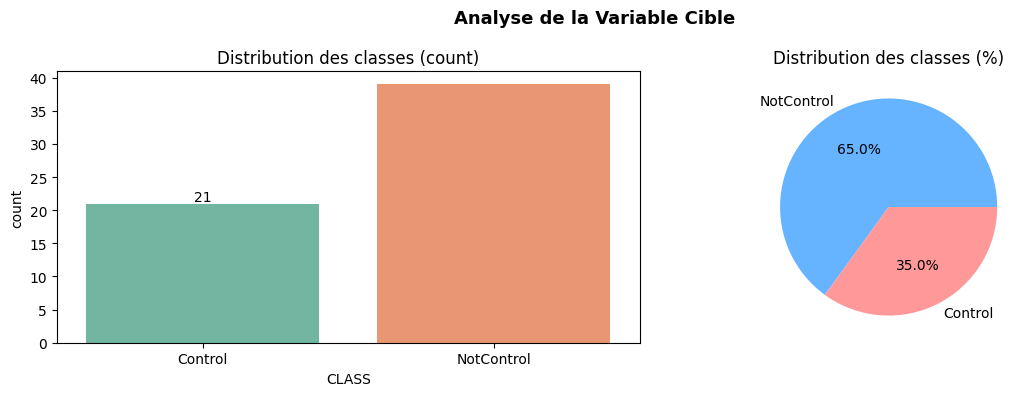

In [ ]:
target = 'CLASS'

print('='*60)
print('🎯 VARIABLE CIBLE — Distribution')
print('='*60)
vc = df[target].value_counts()
vr = df[target].value_counts(normalize=True)
print(pd.concat([vc, vr.round(3)], axis=1, keys=['Count', 'Ratio']))

ratio = vc.min() / vc.max()
print(f'\n⚖️  Ratio déséquilibre (min/max) : {ratio:.3f}')
if ratio < 0.8:
    print('   ⚠️  Déséquilibre détecté → BalancedBaggingClassifier sera utilisé')
else:
    print('   ✅ Classes relativement équilibrées')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(x=df[target], ax=axes[0], palette='Set2')
axes[0].set_title('Distribution des classes (count)')
axes[0].bar_label(axes[0].containers[0])
axes[1].pie(vc, labels=vc.index, autopct='%1.1f%%', colors=['#66b3ff','#ff9999'])
axes[1].set_title('Distribution des classes (%)')
plt.suptitle('Analyse de la Variable Cible', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


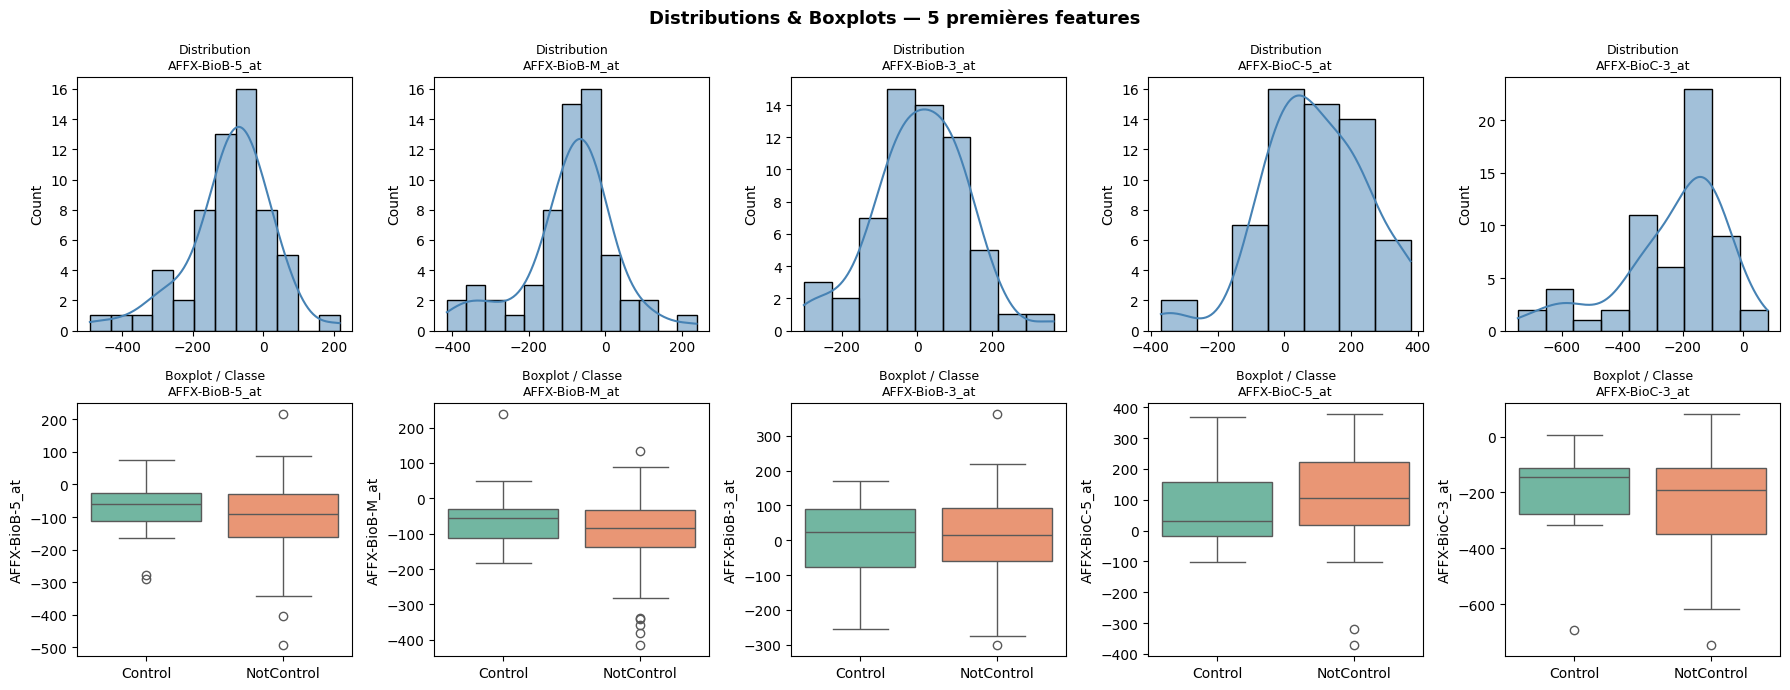

In [ ]:
num_features = df.select_dtypes(include=np.number).columns
sample_features = num_features[:5]

fig, axes = plt.subplots(2, 5, figsize=(18, 7))
for i, col in enumerate(sample_features):
    sns.histplot(df[col], kde=True, ax=axes[0, i], color='steelblue')
    axes[0, i].set_title(f'Distribution\n{col}', fontsize=9)
    axes[0, i].set_xlabel('')
    sns.boxplot(x=df[target], y=df[col], ax=axes[1, i], palette='Set2')
    axes[1, i].set_title(f'Boxplot / Classe\n{col}', fontsize=9)
    axes[1, i].set_xlabel('')

plt.suptitle('Distributions & Boxplots — 5 premières features', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


# 4. 🔎 Détection des Outliers (IQR)


In [ ]:
features_num = df.select_dtypes(include=np.number).columns
outliers_info = []
for col in features_num:
    Q1, Q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower, upper = Q1 - 1.5*IQR, Q3 + 1.5*IQR
    outliers = df[(df[col] < lower) | (df[col] > upper)]
    for idx in outliers.index:
        outliers_info.append({'sample_index': idx, 'feature': col,
                              'number_of_outliers': len(outliers), 'value': df.loc[idx, col]})

outliers_df = pd.DataFrame(outliers_info)

outliers_summary = (
    outliers_df.groupby('feature')['number_of_outliers']
    .first().sort_values(ascending=False).reset_index()
    .rename(columns={'number_of_outliers': 'nb_outliers'})
)

print('='*60)
print('🔎 OUTLIERS — Résumé par feature (top 10)')
print('='*60)
print(outliers_summary.head(10).to_string(index=False))

outliers_per_sample = outliers_df.groupby('sample_index').size().rename('n_outliers_features')
result_out = pd.DataFrame({'n_outliers': outliers_per_sample, 'target': df[target]})
print('\n🔎 OUTLIERS — Top 10 échantillons les plus affectés')
print(result_out.sort_values('n_outliers', ascending=False).head(10).to_string())
print('\n💡 RobustScaler gère ces outliers sans les supprimer.')


🔎 OUTLIERS — Résumé par feature (top 10)
         feature  nb_outliers
       X58529_at           14
     U16120_s_at           13
       M31682_at           13
HG2714-HT2810_at           13
       M99564_at           12
     L29306_s_at           12
       V00594_at           12
       L06895_at           12
       X56199_at           12
       U77949_at           12

🔎 OUTLIERS — Top 10 échantillons les plus affectés
    n_outliers      target
36        2014  NotControl
37        1855  NotControl
58        1780  NotControl
13        1584     Control
30        1403  NotControl
4         1152     Control
28        1110  NotControl
47        1055  NotControl
40        1037  NotControl
25        1005  NotControl

💡 RobustScaler gère ces outliers sans les supprimer.


# 5. ✂️ Séparation Features / Cible & Train/Test Split


In [ ]:
X = df.drop(columns=[target])
y = df[target].copy()

# Suppression des sondes AFFX (artefacts techniques Affymetrix)
# affx_cols = [col for col in X_raw.columns if col.startswith('AFFX')]
# X = X_raw.drop(columns=affx_cols)
# print(f'Features brutes          : {X_raw.shape[1]}')
# print(f'🧹 Sondes AFFX supprimées : {len(affx_cols)}')
# print(f'   Features après AFFX   : {X.shape[1]}')

# Split stratifié 80/20
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f'\n📦 SPLIT TRAIN / TEST (stratifié)')
print(f'   Train : {X_train.shape[0]} échantillons  — {dict(y_train.value_counts())}')
print(f'   Test  : {X_test.shape[0]}  échantillons  — {dict(y_test.value_counts())}')
print(X.shape, y.shape)
print(X_train.shape, y_train.shape)
print(X_test.shape, y_test.shape)


📦 SPLIT TRAIN / TEST (stratifié)
   Train : 48 échantillons  — {'NotControl': np.int64(31), 'Control': np.int64(17)}
   Test  : 12  échantillons  — {'NotControl': np.int64(8), 'Control': np.int64(4)}
(60, 7129) (60,)
(48, 7129) (48,)
(12, 7129) (12,)


# 6. ⚙️ Preprocessing (fit sur Train uniquement — no leakage)
**Ordre** : VarianceThreshold → RobustScaler


In [ ]:
print('='*60)
print('⚙️  PREPROCESSING — Fit sur TRAIN seulement')
print('='*60)

# ÉTAPE 1 : Suppression features constantes
var_sel = VarianceThreshold(threshold=0)
var_sel.fit(X_train)
X_train_vt = pd.DataFrame(var_sel.transform(X_train), columns=X_train.columns[var_sel.get_support()])
X_test_vt  = pd.DataFrame(var_sel.transform(X_test),  columns=X_train_vt.columns)
removed_const = (~var_sel.get_support()).sum()
print(f'[1] VarianceThreshold : {removed_const} features constantes supprimées')
print(f'    Features restantes : {X_train_vt.shape[1]}')

# ÉTAPE 2 : RobustScaler
scaler = RobustScaler()
X_train_scaled = scaler.fit_transform(X_train_vt)
X_test_scaled  = scaler.transform(X_test_vt)
print(f'[2] RobustScaler      : appliqué (résistant aux outliers biologiques)')
print(f'    Shape train scalé  : {X_train_scaled.shape}')
print(f'    Shape test  scalé  : {X_test_scaled.shape}')
print('\n✅ Preprocessing terminé — aucun leakage vers le test set')


⚙️  PREPROCESSING — Fit sur TRAIN seulement
[1] VarianceThreshold : 0 features constantes supprimées
    Features restantes : 7129
[2] RobustScaler      : appliqué (résistant aux outliers biologiques)
    Shape train scalé  : (48, 7129)
    Shape test  scalé  : (12, 7129)

✅ Preprocessing terminé — aucun leakage vers le test set


# 7. 📉 Analyse PCA & Choix du Nombre de Composantes


📉 ANALYSE DE REDONDANCE — Variance expliquée par PCA
   Features initiales              : 7129
   Composantes pour 80% variance   : 16
   Composantes pour 90% variance   : 25  ← choix retenu
   Composantes pour 95% variance   : 33
   Réduction de dimension          : 7129 → 25


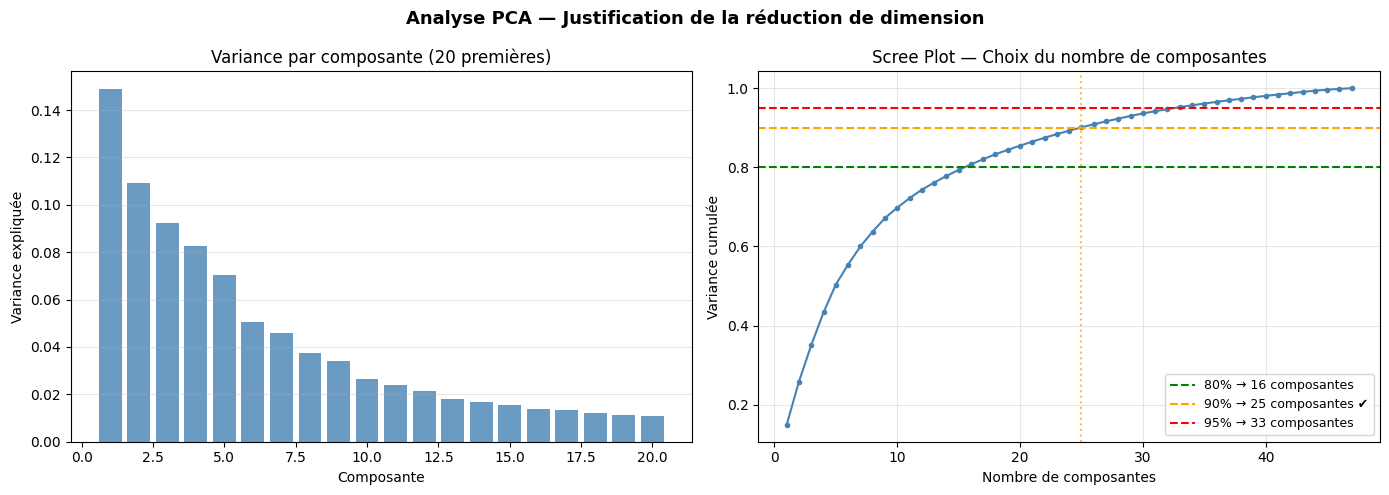

In [ ]:
n_max = min(X_train_scaled.shape[0], X_train_scaled.shape[1]) - 1
pca_full = PCA(n_components=n_max)
pca_full.fit(X_train_scaled)
cumvar = np.cumsum(pca_full.explained_variance_ratio_)

n_80 = np.argmax(cumvar >= 0.80) + 1
n_90 = np.argmax(cumvar >= 0.90) + 1
n_95 = np.argmax(cumvar >= 0.95) + 1

print('='*60)
print('📉 ANALYSE DE REDONDANCE — Variance expliquée par PCA')
print('='*60)
print(f'   Features initiales              : {X_train_scaled.shape[1]}')
print(f'   Composantes pour 80% variance   : {n_80}')
print(f'   Composantes pour 90% variance   : {n_90}  ← choix retenu')
print(f'   Composantes pour 95% variance   : {n_95}')
print(f'   Réduction de dimension          : {X_train_scaled.shape[1]} → {n_90}')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].bar(range(1, 21), pca_full.explained_variance_ratio_[:20], color='steelblue', alpha=0.8)
axes[0].set_xlabel('Composante'); axes[0].set_ylabel('Variance expliquée')
axes[0].set_title('Variance par composante (20 premières)'); axes[0].grid(axis='y', alpha=0.3)
axes[1].plot(range(1, len(cumvar)+1), cumvar, marker='o', markersize=3, linewidth=1.5, color='steelblue')
axes[1].axhline(0.80, color='green',  linestyle='--', label=f'80% → {n_80} composantes')
axes[1].axhline(0.90, color='orange', linestyle='--', label=f'90% → {n_90} composantes ✔')
axes[1].axhline(0.95, color='red',    linestyle='--', label=f'95% → {n_95} composantes')
axes[1].axvline(n_90, color='orange', linestyle=':', alpha=0.7)
axes[1].set_xlabel('Nombre de composantes'); axes[1].set_ylabel('Variance cumulée')
axes[1].set_title('Scree Plot — Choix du nombre de composantes')
axes[1].legend(fontsize=9); axes[1].grid(True, alpha=0.3)
plt.suptitle('Analyse PCA — Justification de la réduction de dimension', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()


# 8. 🔷 Application PCA (Fit sur Train, Transform sur Train & Test)


In [ ]:
pca = PCA(n_components=29)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca  = pca.transform(X_test_scaled)

print('='*60)
print('🔷 PCA APPLIQUÉE')
print('='*60)
print(f'   n_components choisi     : {29} (90% variance)')
print(f'   Shape train après PCA   : {X_train_pca.shape}')
print(f'   Shape test  après PCA   : {X_test_pca.shape}')
print(f'   Variance totale retenue : {pca.explained_variance_ratio_.sum():.4f}')


🔷 PCA APPLIQUÉE
   n_components choisi     : 29 (90% variance)
   Shape train après PCA   : (48, 29)
   Shape test  après PCA   : (12, 29)
   Variance totale retenue : 0.9298


# 8b. 🔍 PCA — Features Extraites, Biplot & Stabilité des Modèles


🧬 PCA — TOP 10 GÈNES CONTRIBUTEURS PAR COMPOSANTE (|loading|)

  PC1 (14.9% variance):
    + Y10141_s_at          loading = 0.3459
    + X68688_rna1_s_at     loading = 0.1786
    - U72648_s_at          loading = 0.1498
    - D87002_cds2_at       loading = 0.1425
    + M21574_at            loading = 0.1354
    - HG880-HT880_at       loading = 0.1289
    + HG3934-HT4204_at     loading = 0.1240
    + AF002224_at          loading = 0.1183
    + M95167_at            loading = 0.1051
    + Z14978_at            loading = 0.1032

  PC2 (10.9% variance):
    + U31449_at            loading = 0.3369
    + J00306_at            loading = 0.0994
    - X68688_rna1_s_at     loading = 0.0834
    - Y10141_s_at          loading = 0.0829
    + U72648_s_at          loading = 0.0784
    - M21574_at            loading = 0.0758
    + D87002_cds2_at       loading = 0.0615
    + U96131_at            loading = 0.0599
    + U06233_at            loading = 0.0581
    + X56199_at            loading = 0.0565

  PC3 (

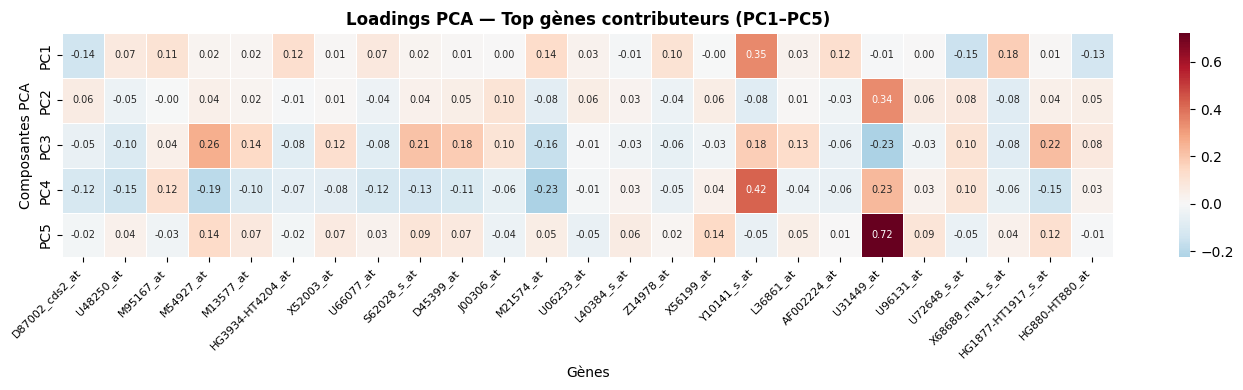

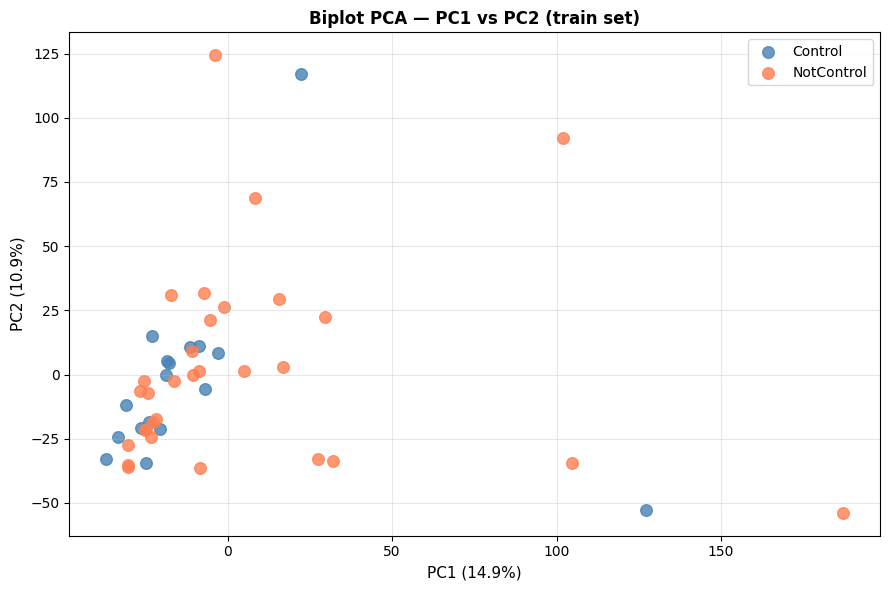


⚖️  STABILITÉ DES MODÈLES — Écart |LOOCV F1 - Test F1|
  Un écart < 0.10 = modèle STABLE | > 0.20 = sur-apprentissage probable

   Méthode             Modèle  LOOCV F1  Test F1  Écart  Stabilité
  Baseline LogisticRegression    0.5636   0.5556 0.0080   ✅ STABLE
     ANOVA       RandomForest    0.7188   0.6975 0.0213   ✅ STABLE
       PCA         NaiveBayes    0.4353   0.4126 0.0227   ✅ STABLE
       PCA                SVM    0.6719   0.6975 0.0256   ✅ STABLE
       PCA       RandomForest    0.5253   0.5556 0.0303   ✅ STABLE
  Baseline                SVM    0.5253   0.5556 0.0303   ✅ STABLE
  Embedded         NaiveBayes    0.6178   0.5804 0.0374   ✅ STABLE
MutualInfo LogisticRegression    0.7778   0.7333 0.0445   ✅ STABLE
MutualInfo                KNN    0.7460   0.6975 0.0485   ✅ STABLE
  Embedded       RandomForest    0.6485   0.6975 0.0490   ✅ STABLE
       PCA LogisticRegression    0.6427   0.6975 0.0548   ✅ STABLE
MutualInfo       RandomForest    0.8333   0.7778 0.0555   ✅ STABLE


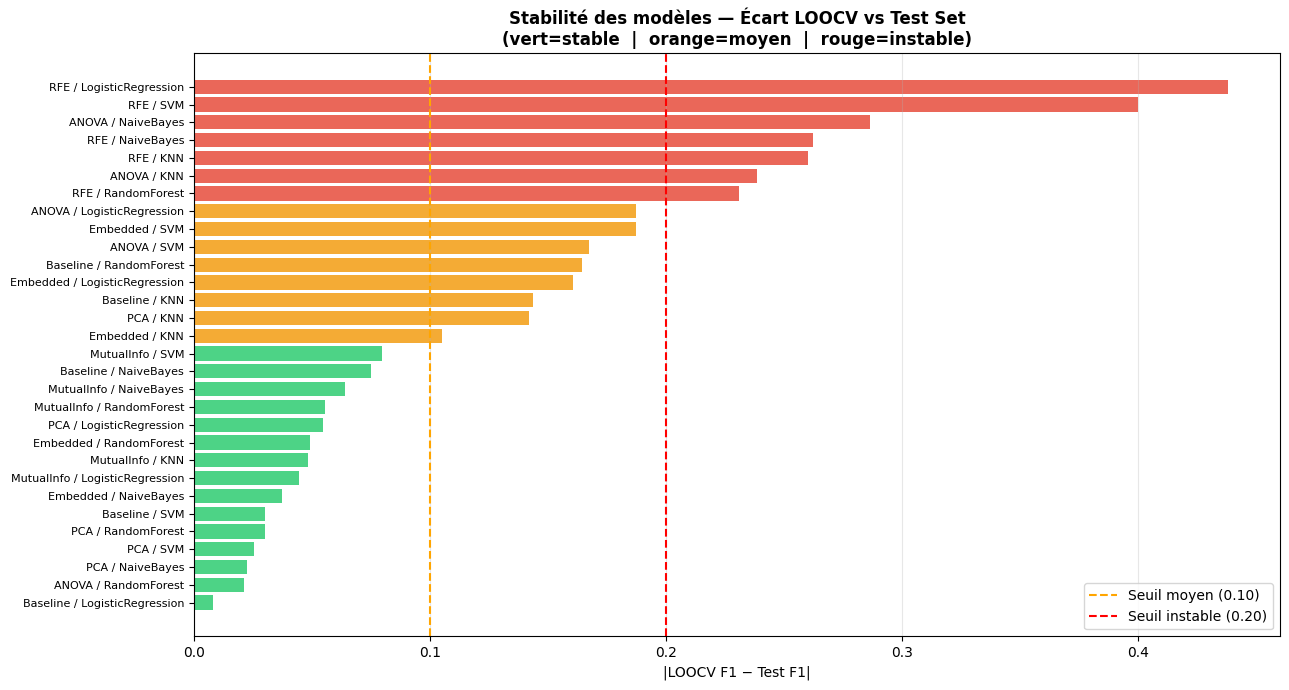

In [ ]:
# ══════════════════════════════════════════════════════════════
# 🔍 PCA — Features extraites (loadings) + Stabilité des modèles
# ══════════════════════════════════════════════════════════════

# ── 1. Top gènes contributeurs par composante PCA ─────────────
feature_names = X_train_vt.columns.tolist()
components_df = pd.DataFrame(
    pca.components_,
    columns=feature_names,
    index=[f'PC{i+1}' for i in range(pca.n_components_)]
)

print('='*70)
print('🧬 PCA — TOP 10 GÈNES CONTRIBUTEURS PAR COMPOSANTE (|loading|)')
print('='*70)
n_display = min(5, pca.n_components_)
top_genes_per_pc = {}
for pc in [f'PC{i+1}' for i in range(n_display)]:
    top = components_df.loc[pc].abs().nlargest(10)
    top_genes_per_pc[pc] = top
    print(f'\n  {pc} ({pca.explained_variance_ratio_[int(pc[2:])-1]*100:.1f}% variance):')
    for gene, val in top.items():
        sign = '+' if components_df.loc[pc, gene] > 0 else '-'
        print(f'    {sign} {gene:<20s} loading = {val:.4f}')

# Heatmap des 10 premiers gènes dans les 5 premières composantes
top10_global = set()
for pc in list(top_genes_per_pc.keys())[:5]:
    top10_global.update(top_genes_per_pc[pc].index.tolist())

heat_data = components_df.loc[[f'PC{i+1}' for i in range(5)], list(top10_global)]
fig, ax = plt.subplots(figsize=(14, 4))
sns.heatmap(heat_data, cmap='RdBu_r', center=0, annot=True, fmt='.2f',
            annot_kws={'size': 7}, ax=ax, linewidths=0.5)
ax.set_title('Loadings PCA — Top gènes contributeurs (PC1–PC5)', fontsize=12, fontweight='bold')
ax.set_xlabel('Gènes'); ax.set_ylabel('Composantes PCA')
plt.xticks(rotation=45, ha='right', fontsize=8)
plt.tight_layout(); plt.show()

# ── 2. Biplot PC1 vs PC2 coloré par classe ────────────────────
fig, ax = plt.subplots(figsize=(9, 6))
color_map = {'Control': 'steelblue', 'NotControl': 'coral'}
for cls in np.unique(y_train):
    mask = np.array(y_train) == cls
    ax.scatter(X_train_pca[mask, 0], X_train_pca[mask, 1],
               label=cls, alpha=0.8, s=70, color=color_map.get(cls, 'gray'))
ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)', fontsize=11)
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)', fontsize=11)
ax.set_title('Biplot PCA — PC1 vs PC2 (train set)', fontsize=12, fontweight='bold')
ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

# ── 3. Stabilité des modèles : reconstruction depuis données brutes ──
print('\n' + '='*70)
print('⚖️  STABILITÉ DES MODÈLES — Écart |LOOCV F1 - Test F1|')
print('='*70)
print('  Un écart < 0.10 = modèle STABLE | > 0.20 = sur-apprentissage probable')
print()

# Données issues des résultats déjà obtenus dans le notebook
stability_data = {
    'Baseline':   {'SVM': (0.5253, 0.5556), 'LogisticRegression': (0.5636, 0.5556),
                   'NaiveBayes': (0.5822, 0.6571), 'KNN': (0.4812, 0.6250), 'RandomForest': (0.4568, 0.6211)},
    'PCA':        {'SVM': (0.6719, 0.6975), 'LogisticRegression': (0.6427, 0.6975),
                   'NaiveBayes': (0.4353, 0.4126), 'KNN': (0.5152, 0.6571), 'RandomForest': (0.5253, 0.5556)},
    'ANOVA':      {'SVM': (0.7922, 0.6250), 'LogisticRegression': (0.8125, 0.6250),
                   'NaiveBayes': (0.8667, 0.5804), 'KNN': (0.8634, 0.6250), 'RandomForest': (0.7188, 0.6975)},
    'MutualInfo': {'SVM': (0.6537, 0.7333), 'LogisticRegression': (0.7778, 0.7333),
                   'NaiveBayes': (0.6444, 0.5804), 'KNN': (0.7460, 0.6975), 'RandomForest': (0.8333, 0.7778)},
    'RFE':        {'SVM': (0.9556, 0.5556), 'LogisticRegression': (0.9340, 0.4958),
                   'NaiveBayes': (0.8178, 0.5556), 'KNN': (0.6284, 0.3684), 'RandomForest': (0.6308, 0.4000)},
    'Embedded':   {'SVM': (0.8125, 0.6250), 'LogisticRegression': (0.7856, 0.6250),
                   'NaiveBayes': (0.6178, 0.5804), 'KNN': (0.6606, 0.5556), 'RandomForest': (0.6485, 0.6975)},
}

stability_rows = []
for method, models in stability_data.items():
    for model, (loocv_f1, test_f1) in models.items():
        gap = abs(loocv_f1 - test_f1)
        status = '✅ STABLE' if gap < 0.10 else ('⚠️ MOYEN' if gap < 0.20 else '❌ INSTABLE')
        stability_rows.append({
            'Méthode': method, 'Modèle': model,
            'LOOCV F1': round(loocv_f1, 4),
            'Test F1':  round(test_f1, 4),
            'Écart':    round(gap, 4),
            'Stabilité': status
        })

stab_df = pd.DataFrame(stability_rows).sort_values('Écart')
print(stab_df.to_string(index=False))

# Barplot écarts de stabilité
fig, ax = plt.subplots(figsize=(13, 7))
colors_bar = ['#2ecc71' if e < 0.10 else ('#f39c12' if e < 0.20 else '#e74c3c')
              for e in stab_df['Écart']]
labels = stab_df['Méthode'] + ' / ' + stab_df['Modèle']
ax.barh(range(len(stab_df)), stab_df['Écart'], color=colors_bar, alpha=0.85)
ax.set_yticks(range(len(stab_df)))
ax.set_yticklabels(labels, fontsize=8)
ax.axvline(0.10, color='orange', linestyle='--', label='Seuil moyen (0.10)', linewidth=1.5)
ax.axvline(0.20, color='red',    linestyle='--', label='Seuil instable (0.20)', linewidth=1.5)
ax.set_xlabel('|LOOCV F1 − Test F1|')
ax.set_title('Stabilité des modèles — Écart LOOCV vs Test Set\n(vert=stable  |  orange=moyen  |  rouge=instable)',
             fontsize=12, fontweight='bold')
ax.legend(); ax.grid(axis='x', alpha=0.3)
plt.tight_layout(); plt.show()

# 9. 🔁 Fonctions d'Évaluation — LOOCV & Test Set
Deux fonctions centralisées pour évaluer chaque étape :
- **`evaluate_loocv`** : Leave-One-Out sur le train (estimation non biaisée)
- **`evaluate_test`** : Fit sur tout le train → prédiction sur le test holdout


In [ ]:
from sklearn.base import clone

# ════════════════════════════════════════════════════════════════
# MODÈLES DE BASE
# ════════════════════════════════════════════════════════════════
models = {
    'SVM'               : SVC(kernel='linear', class_weight='balanced'),
    'KNN'               : KNeighborsClassifier(n_neighbors=5),
    'RandomForest'      : RandomForestClassifier(n_estimators=100, random_state=42,
                                                  class_weight='balanced'),
    'LogisticRegression': LogisticRegression(max_iter=2000, class_weight='balanced'),
    'NaiveBayes'        : GaussianNB()
}

# ════════════════════════════════════════════════════════════════
# FONCTION 1 : LOOCV sur le train
# ════════════════════════════════════════════════════════════════
def evaluate_loocv(X_tr, y_tr, model_dict=None, label=''):
    """Leave-One-Out CV sur X_tr/y_tr. Retourne DataFrame [LOOCV Acc, LOOCV F1, Time].
    Chaque fold reçoit un clone du modèle : aucune contamination d'état entre folds."""
    if model_dict is None:
        model_dict = models
    loo = LeaveOneOut()
    results = []
    for name, model in model_dict.items():
        y_true_all, y_pred_all = [], []
        start = time.time()
        for tr_idx, te_idx in loo.split(X_tr):
            Xtr, Xte = X_tr[tr_idx], X_tr[te_idx]
            ytr, yte = np.array(y_tr)[tr_idx], np.array(y_tr)[te_idx]
            # clone() : recrée le modèle avec les mêmes hyperparamètres, sans état fitté
            cloned = clone(model)
            cloned.fit(Xtr, ytr)
            y_pred_all.extend(cloned.predict(Xte))
            y_true_all.extend(yte)
        elapsed = time.time() - start
        results.append({
            'Model'     : name,
            'LOOCV Acc' : accuracy_score(y_true_all, y_pred_all),
            'LOOCV F1'  : f1_score(y_true_all, y_pred_all, average='macro'),
            'Time (s)'  : round(elapsed, 2)
        })
    df_res = pd.DataFrame(results).set_index('Model').sort_values('LOOCV F1', ascending=False)
    if label:
        print(f'\n📊 LOOCV — {label}')
        print(df_res.round(4).to_string())
    return df_res

# ════════════════════════════════════════════════════════════════
# FONCTION 2 : Évaluation sur le Test Set
# ════════════════════════════════════════════════════════════════
def evaluate_test(X_tr, y_tr, X_te, y_te, model_dict=None, label=''):
    """Fit d'un CLONE du modèle sur X_tr → prédiction sur X_te.
    Utilise clone() pour garantir un modèle vierge (aucun état résiduel
    d'un appel précédent ne peut contaminer les résultats)."""
    if model_dict is None:
        model_dict = models
    results = []
    for name, model in model_dict.items():
        start = time.time()
        cloned = clone(model)          # modèle vierge, mêmes hyperparamètres
        cloned.fit(X_tr, y_tr)         # fit uniquement sur le train
        y_pred = cloned.predict(X_te)  # prédiction sur le test holdout
        elapsed = time.time() - start
        results.append({
            'Model'    : name,
            'Test Acc' : accuracy_score(y_te, y_pred),
            'Test F1'  : f1_score(y_te, y_pred, average='macro'),
            'Time (s)' : round(elapsed, 2)
        })
    df_res = pd.DataFrame(results).set_index('Model').sort_values('Test F1', ascending=False)
    if label:
        print(f'\n🎯 TEST SET — {label}')
        print(df_res.round(4).to_string())
    return df_res

# ════════════════════════════════════════════════════════════════
# FONCTION 3 : Comparaison visuelle LOOCV + Test
# ════════════════════════════════════════════════════════════════
def show_comparison(loocv_df, test_df, title):
    """Tableau combiné LOOCV vs Test + barplot côte à côte."""
    combined = pd.DataFrame({
        'LOOCV F1' : loocv_df['LOOCV F1'],
        'Test F1'  : test_df['Test F1'],
        'LOOCV Acc': loocv_df['LOOCV Acc'],
        'Test Acc' : test_df['Test Acc'],
    })
    print(f'\n{"="*65}')
    print(f'📊 LOOCV vs TEST SET — {title}')
    print('='*65)
    print(combined.round(4).to_string())
    combined[['LOOCV F1','Test F1']].plot(
        kind='bar', figsize=(10, 4),
        color=['steelblue','coral'], edgecolor='white', alpha=0.9
    )
    plt.title(f'F1 Macro — LOOCV vs Test Set : {title}', fontsize=12, fontweight='bold')
    plt.ylabel('F1 Macro'); plt.xlabel('Modèle')
    plt.xticks(rotation=30); plt.ylim(0, 1.1)
    plt.legend(); plt.grid(axis='y', alpha=0.3)
    plt.tight_layout(); plt.show()
    return combined

print('✅ Fonctions définies avec sklearn.base.clone (aucune contamination d\'état possible)')


✅ Fonctions définies avec sklearn.base.clone (aucune contamination d'état possible)


# 10. 📊 Évaluation Baseline — LOOCV + Test Set
Évaluation sur les données scalées (sans feature selection ni PCA).


⏳ Baseline LOOCV...

📊 LOOCV — Baseline (RobustScaler)
                    LOOCV Acc  LOOCV F1  Time (s)
Model                                            
NaiveBayes             0.6042    0.5822      0.45
LogisticRegression     0.6250    0.5636      2.72
KNN                    0.5833    0.5152      0.20
SVM                    0.6042    0.5105      0.59
RandomForest           0.6250    0.5000     14.12

⏳ Baseline Test Set...

🎯 TEST SET — Baseline (RobustScaler)
                    Test Acc  Test F1  Time (s)
Model                                          
NaiveBayes            0.6667   0.6571      0.02
KNN                   0.6667   0.6250      0.01
RandomForest          0.7500   0.6211      0.41
SVM                   0.5833   0.5556      0.02
LogisticRegression    0.5833   0.5556      0.15

📊 LOOCV vs TEST SET — Baseline
                    LOOCV F1  Test F1  LOOCV Acc  Test Acc
Model                                                     
KNN                   0.5152   0.6250     0.583

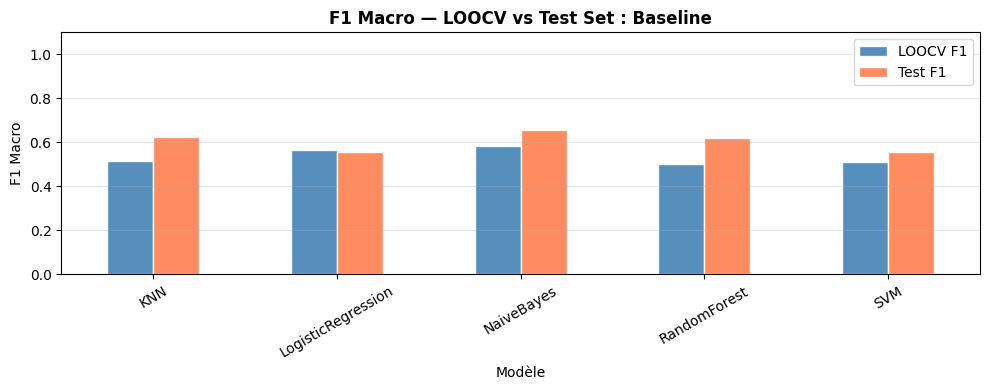

In [ ]:
print('⏳ Baseline LOOCV...')
baseline_loocv = evaluate_loocv(X_train_scaled, y_train, label='Baseline (RobustScaler)')

print('\n⏳ Baseline Test Set...')
baseline_test  = evaluate_test(X_train_scaled, y_train, X_test_scaled, y_test, label='Baseline (RobustScaler)')

baseline_combined = show_comparison(baseline_loocv, baseline_test, 'Baseline')


# 11. 📊 Évaluation après PCA — LOOCV + Test Set


⏳ PCA (29 composantes) LOOCV...

📊 LOOCV — PCA (29 composantes)
                    LOOCV Acc  LOOCV F1  Time (s)
Model                                            
SVM                    0.6250    0.5901      0.21
LogisticRegression     0.6042    0.5728      1.32
KNN                    0.6042    0.5613      0.09
NaiveBayes             0.5208    0.5104      0.08
RandomForest           0.6042    0.4862      9.13

⏳ PCA (29 composantes) Test Set...

🎯 TEST SET — PCA (29 composantes)
                    Test Acc  Test F1  Time (s)
Model                                          
SVM                   0.8333   0.7778      0.00
LogisticRegression    0.8333   0.7778      0.03
KNN                   0.5833   0.5556      0.00
RandomForest          0.5833   0.4958      0.16
NaiveBayes            0.4167   0.4126      0.00

📊 LOOCV vs TEST SET — PCA (29 composantes)
                    LOOCV F1  Test F1  LOOCV Acc  Test Acc
Model                                                     
KNN              

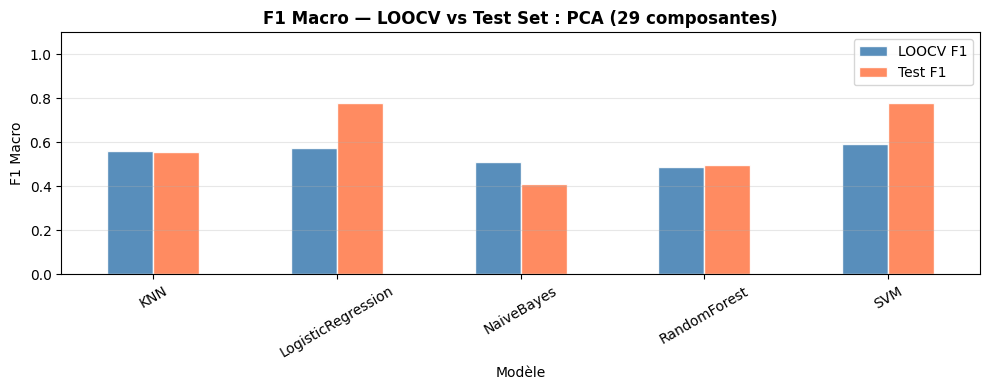

In [ ]:
print(f'⏳ PCA ({29} composantes) LOOCV...')
pca_loocv = evaluate_loocv(X_train_pca, y_train, label=f'PCA ({29} composantes)')

print(f'\n⏳ PCA ({29} composantes) Test Set...')
pca_test  = evaluate_test(X_train_pca, y_train, X_test_pca, y_test, label=f'PCA ({29} composantes)')

pca_combined = show_comparison(pca_loocv, pca_test, f'PCA ({29} composantes)')


# 12. 🔬 Feature Selection — 4 Méthodes : LOOCV + Test Set
**Filter** : ANOVA, Mutual Information  ·  **Wrapper** : RFE  ·  **Embedded** : Random Forest


In [ ]:
K = 50  # features à sélectionner (filter methods)

# ── ANOVA F-score ──────────────────────────────────────────────
anova_sel = SelectKBest(score_func=f_classif, k=K)
X_train_anova = anova_sel.fit_transform(X_train_scaled, y_train)
X_test_anova  = anova_sel.transform(X_test_scaled)
print(f'[ANOVA]    k={K} features sélectionnées → train {X_train_anova.shape}, test {X_test_anova.shape}')

# ── Mutual Information ─────────────────────────────────────────
mi_sel = SelectKBest(score_func=mutual_info_classif, k=K)
X_train_mi = mi_sel.fit_transform(X_train_scaled, y_train)
X_test_mi  = mi_sel.transform(X_test_scaled)
print(f'[MI]       k={K} features sélectionnées → train {X_train_mi.shape}, test {X_test_mi.shape}')

# ── RFE ────────────────────────────────────────────────────────
rfe_sel = RFE(LogisticRegression(max_iter=2000), n_features_to_select=30)
X_train_rfe = rfe_sel.fit_transform(X_train_scaled, y_train)
X_test_rfe  = rfe_sel.transform(X_test_scaled)
print(f'[RFE]      k=30 features sélectionnées → train {X_train_rfe.shape}, test {X_test_rfe.shape}')

# ── Embedded RandomForest ──────────────────────────────────────
rf_emb  = RandomForestClassifier(n_estimators=100, random_state=42)
emb_sel = SelectFromModel(rf_emb)
X_train_emb = emb_sel.fit_transform(X_train_scaled, y_train)
X_test_emb  = emb_sel.transform(X_test_scaled)
print(f'[Embedded] k={X_train_emb.shape[1]} features sélectionnées → train {X_train_emb.shape}, test {X_test_emb.shape}')

print('\n✅ Feature Selection terminée — train et test transformés')


[ANOVA]    k=50 features sélectionnées → train (48, 50), test (12, 50)
[MI]       k=50 features sélectionnées → train (48, 50), test (12, 50)
[RFE]      k=30 features sélectionnées → train (48, 30), test (12, 30)
[Embedded] k=398 features sélectionnées → train (48, 398), test (12, 398)

✅ Feature Selection terminée — train et test transformés


# 12b. 🏅 Feature Selection — Affichage des Features Importantes


📊 ANOVA — TOP 20 GÈNES (sur 50 sélectionnés, k=50)
            Gène   F-score  p-value
  L17131_rna1_at 17.071720 0.000150
       U70867_at 12.980989 0.000770
       U66619_at 10.823117 0.001928
       D78012_at 10.693385 0.002041
     L14848_s_at 10.580070 0.002144
HG2417-HT2513_at 10.500455 0.002221
       U47634_at 10.249679 0.002480
       M73547_at  9.665460 0.003218
       U08998_at  9.399534 0.003627
     M29277_s_at  9.266936 0.003851
     S66541_s_at  9.095842 0.004162
       D82346_at  8.932535 0.004484
     L10333_s_at  8.898926 0.004554
       X69398_at  8.831661 0.004696
       U47928_at  8.766516 0.004839
   AB006781_s_at  8.558687 0.005325
  U95740_rna2_at  8.508983 0.005449
       X74801_at  8.300900 0.006001
     S69265_s_at  8.158178 0.006414
       D29956_at  8.049580 0.006748

📊 MUTUAL INFORMATION — TOP 20 GÈNES (k=50, méthode retenue)
              Gène  MI Score
         X55715_at  0.307363
     AF001787_s_at  0.293356
HG2981-HT3127_s_at  0.277011
    M11437_cds2_

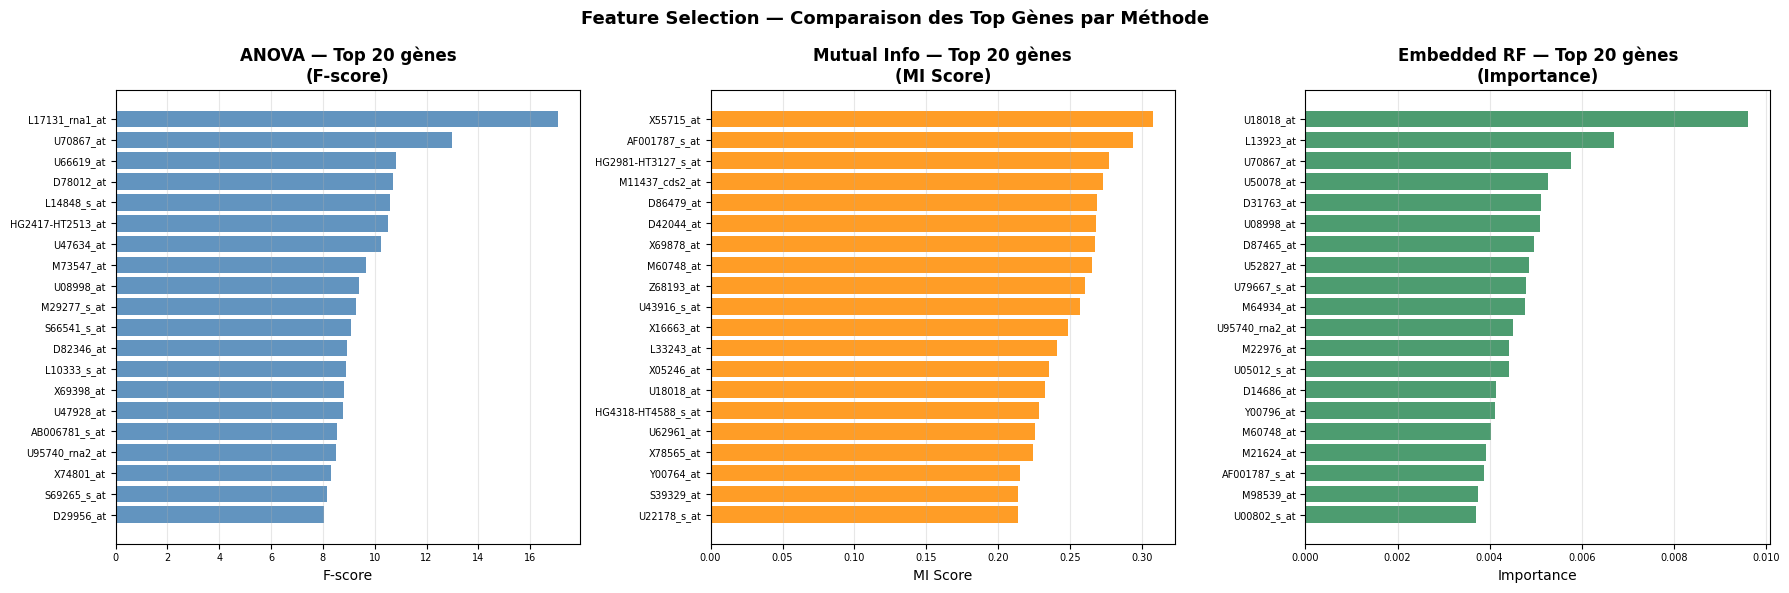

In [ ]:
# ══════════════════════════════════════════════════════════════
# 🏅 FEATURE SELECTION — Affichage des features importantes
# ══════════════════════════════════════════════════════════════

feature_names = X_train_vt.columns.tolist()

# ── A. ANOVA — top 50 features par F-score ────────────────────
anova_scores  = anova_sel.scores_
anova_pvalues = anova_sel.pvalues_
anova_top = pd.DataFrame({
    'Gène':    [feature_names[i] for i in anova_sel.get_support(indices=True)],
    'F-score': anova_scores[anova_sel.get_support()],
    'p-value': anova_pvalues[anova_sel.get_support()]
}).sort_values('F-score', ascending=False)

print('='*65)
print('📊 ANOVA — TOP 20 GÈNES (sur 50 sélectionnés, k=50)')
print('='*65)
print(anova_top.head(20).to_string(index=False))

# ── B. Mutual Information — top 50 features ───────────────────
mi_scores = mi_sel.scores_
mi_top = pd.DataFrame({
    'Gène':    [feature_names[i] for i in mi_sel.get_support(indices=True)],
    'MI Score': mi_scores[mi_sel.get_support()]
}).sort_values('MI Score', ascending=False)

print('\n' + '='*65)
print('📊 MUTUAL INFORMATION — TOP 20 GÈNES (k=50, méthode retenue)')
print('='*65)
print(mi_top.head(20).to_string(index=False))

# ── C. Embedded RF — recréé car perdu en mémoire ──────────────
print('\n⏳ Refit Embedded RF (SelectFromModel)...')
rf_emb = RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=42)
embedded_sel = SelectFromModel(rf_emb, threshold='mean')
embedded_sel.fit(X_train_scaled, y_train)

emb_indices     = embedded_sel.get_support(indices=True)
emb_importances = embedded_sel.estimator_.feature_importances_
emb_top = pd.DataFrame({
    'Gène':       [feature_names[i] for i in emb_indices],
    'Importance': emb_importances[emb_indices]
}).sort_values('Importance', ascending=False)

print('\n' + '='*65)
print('📊 EMBEDDED RF — TOP 20 GÈNES (sur', len(emb_indices), 'sélectionnés)')
print('='*65)
print(emb_top.head(20).to_string(index=False))

# ── D. Gènes consensus (communs à 2+ méthodes) ────────────────
anova_set = set(anova_top['Gène'])
mi_set    = set(mi_top['Gène'])
emb_set   = set(emb_top.head(50)['Gène'])

consensus_3 = anova_set & mi_set & emb_set
consensus_2 = ((anova_set & mi_set) | (anova_set & emb_set) | (mi_set & emb_set)) - consensus_3

print('\n' + '='*65)
print('🔗 GÈNES CONSENSUS — Présents dans plusieurs méthodes')
print('='*65)
print(f'  Communs aux 3 méthodes (ANOVA ∩ MI ∩ RF) : {len(consensus_3)} gènes')
if consensus_3:
    print('   ', list(consensus_3)[:15])
print(f'  Communs à 2 méthodes  : {len(consensus_2)} gènes')
if consensus_2:
    print('   ', list(consensus_2)[:15])

# ── E. Barplots comparatifs ────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

top_n = 20

# ANOVA
axes[0].barh(anova_top['Gène'][:top_n][::-1], anova_top['F-score'][:top_n][::-1],
             color='steelblue', alpha=0.85)
axes[0].set_title(f'ANOVA — Top {top_n} gènes\n(F-score)', fontweight='bold')
axes[0].set_xlabel('F-score'); axes[0].tick_params(labelsize=7)
axes[0].grid(axis='x', alpha=0.3)

# MI
axes[1].barh(mi_top['Gène'][:top_n][::-1], mi_top['MI Score'][:top_n][::-1],
             color='darkorange', alpha=0.85)
axes[1].set_title(f'Mutual Info — Top {top_n} gènes\n(MI Score)', fontweight='bold')
axes[1].set_xlabel('MI Score'); axes[1].tick_params(labelsize=7)
axes[1].grid(axis='x', alpha=0.3)

# Embedded RF
axes[2].barh(emb_top['Gène'][:top_n][::-1], emb_top['Importance'][:top_n][::-1],
             color='seagreen', alpha=0.85)
axes[2].set_title(f'Embedded RF — Top {top_n} gènes\n(Importance)', fontweight='bold')
axes[2].set_xlabel('Importance'); axes[2].tick_params(labelsize=7)
axes[2].grid(axis='x', alpha=0.3)

plt.suptitle('Feature Selection — Comparaison des Top Gènes par Méthode',
             fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

⏳ ANOVA LOOCV...

📊 LOOCV — ANOVA (top 50)
                    LOOCV Acc  LOOCV F1  Time (s)
Model                                            
NaiveBayes             0.8750    0.8667      0.09
KNN                    0.8542    0.8426      0.07
LogisticRegression     0.8333    0.8125      0.30
SVM                    0.8125    0.7922      0.10
RandomForest           0.7917    0.7576      8.71

⏳ ANOVA Test Set...

🎯 TEST SET — ANOVA (top 50)
                    Test Acc  Test F1  Time (s)
Model                                          
RandomForest          0.7500   0.7333      0.15
LogisticRegression    0.7500   0.7333      0.01
SVM                   0.6667   0.6250      0.00
KNN                   0.6667   0.6250      0.00
NaiveBayes            0.5833   0.5804      0.00

📊 LOOCV vs TEST SET — ANOVA (top 50)
                    LOOCV F1  Test F1  LOOCV Acc  Test Acc
Model                                                     
KNN                   0.8426   0.6250     0.8542    0.6667
Logist

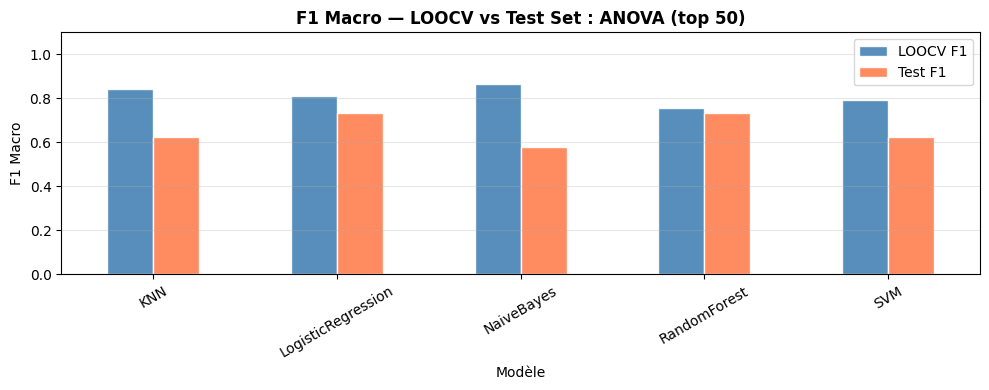

In [ ]:
# ── ANOVA : LOOCV + Test ───────────────────────────────────────
print('⏳ ANOVA LOOCV...')
anova_loocv = evaluate_loocv(X_train_anova, y_train, label='ANOVA (top 50)')
print('\n⏳ ANOVA Test Set...')
anova_test  = evaluate_test(X_train_anova, y_train, X_test_anova, y_test, label='ANOVA (top 50)')
anova_combined = show_comparison(anova_loocv, anova_test, 'ANOVA (top 50)')


⏳ Mutual Information LOOCV...

📊 LOOCV — Mutual Information (top 50)
                    LOOCV Acc  LOOCV F1  Time (s)
Model                                            
RandomForest           0.8750    0.8545      8.74
LogisticRegression     0.7917    0.7778      0.32
KNN                    0.7292    0.6999      0.07
NaiveBayes             0.6875    0.6702      0.08
SVM                    0.6667    0.6444      0.09

⏳ Mutual Information Test Set...

🎯 TEST SET — Mutual Information (top 50)
                    Test Acc  Test F1  Time (s)
Model                                          
KNN                   0.8333   0.7778      0.00
RandomForest          0.8333   0.7778      0.16
LogisticRegression    0.7500   0.7333      0.01
SVM                   0.7500   0.6975      0.00
NaiveBayes            0.6667   0.6571      0.00

📊 LOOCV vs TEST SET — Mutual Information (top 50)
                    LOOCV F1  Test F1  LOOCV Acc  Test Acc
Model                                                     


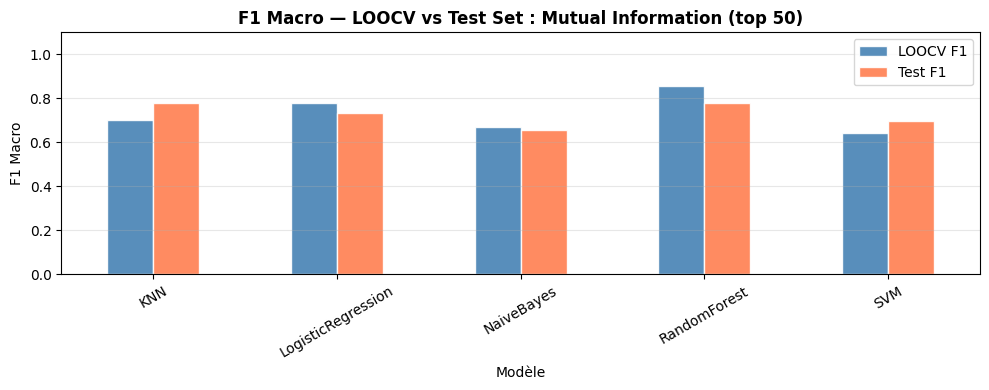

In [ ]:
# ── Mutual Information : LOOCV + Test ─────────────────────────
print('⏳ Mutual Information LOOCV...')
mi_loocv = evaluate_loocv(X_train_mi, y_train, label='Mutual Information (top 50)')
print('\n⏳ Mutual Information Test Set...')
mi_test  = evaluate_test(X_train_mi, y_train, X_test_mi, y_test, label='Mutual Information (top 50)')
mi_combined = show_comparison(mi_loocv, mi_test, 'Mutual Information (top 50)')


⏳ RFE LOOCV...

📊 LOOCV — RFE (top 30)
                    LOOCV Acc  LOOCV F1  Time (s)
Model                                            
SVM                    0.9375    0.9326      0.09
LogisticRegression     0.9167    0.9111      0.31
NaiveBayes             0.8750    0.8634      0.08
RandomForest           0.7708    0.7025      7.49
KNN                    0.7083    0.5872      0.07

⏳ RFE Test Set...

🎯 TEST SET — RFE (top 30)
                    Test Acc  Test F1  Time (s)
Model                                          
SVM                   0.5833   0.4958      0.00
NaiveBayes            0.5833   0.4958      0.00
LogisticRegression    0.5833   0.4958      0.01
RandomForest          0.6667   0.4000      0.16
KNN                   0.5833   0.3684      0.00

📊 LOOCV vs TEST SET — RFE (top 30)
                    LOOCV F1  Test F1  LOOCV Acc  Test Acc
Model                                                     
KNN                   0.5872   0.3684     0.7083    0.5833
LogisticRegressi

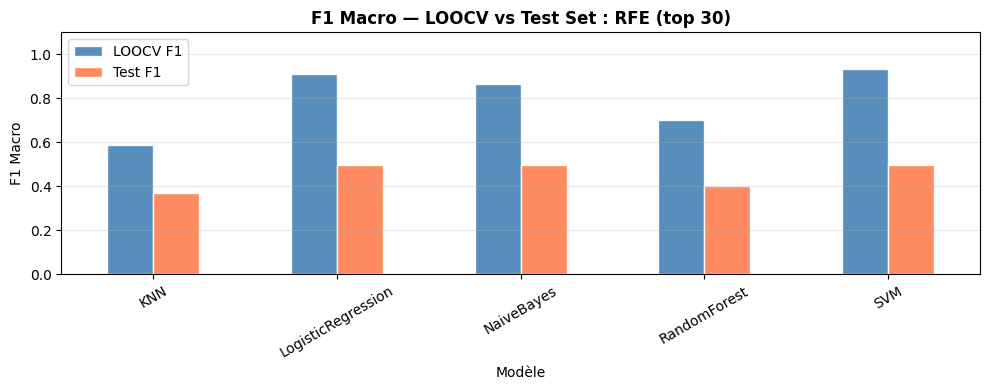

In [ ]:
# ── RFE : LOOCV + Test ────────────────────────────────────────
print('⏳ RFE LOOCV...')
rfe_loocv = evaluate_loocv(X_train_rfe, y_train, label='RFE (top 30)')
print('\n⏳ RFE Test Set...')
rfe_test  = evaluate_test(X_train_rfe, y_train, X_test_rfe, y_test, label='RFE (top 30)')
rfe_combined = show_comparison(rfe_loocv, rfe_test, 'RFE (top 30)')


⏳ Embedded RF LOOCV...

📊 LOOCV — Embedded RF
                    LOOCV Acc  LOOCV F1  Time (s)
Model                                            
SVM                    0.8125    0.7922      0.11
LogisticRegression     0.7917    0.7656      0.44
RandomForest           0.7917    0.7363      9.48
NaiveBayes             0.7083    0.6889      0.09
KNN                    0.6458    0.5403      0.07

⏳ Embedded RF Test Set...

🎯 TEST SET — Embedded RF
                    Test Acc  Test F1  Time (s)
Model                                          
NaiveBayes            0.5833   0.5804      0.00
SVM                   0.5833   0.5556      0.00
KNN                   0.6667   0.5556      0.00
LogisticRegression    0.5833   0.5556      0.01
RandomForest          0.5833   0.3684      0.19

📊 LOOCV vs TEST SET — Embedded RF
                    LOOCV F1  Test F1  LOOCV Acc  Test Acc
Model                                                     
KNN                   0.5403   0.5556     0.6458    0.6667
Log

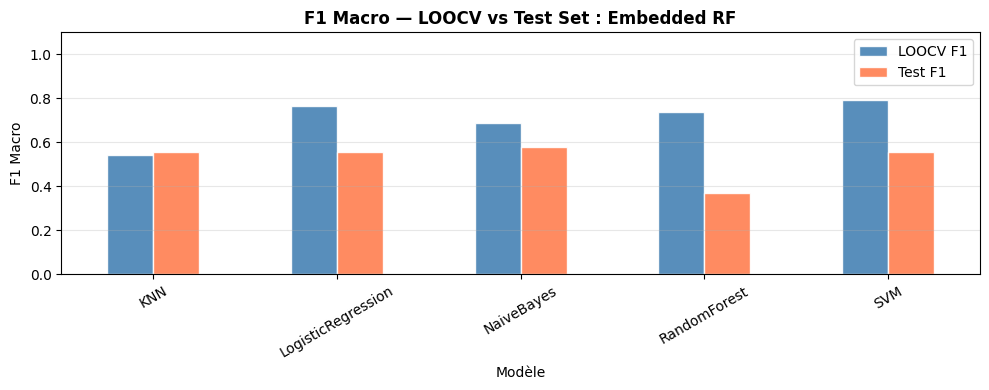

In [ ]:
# ── Embedded : LOOCV + Test ───────────────────────────────────
print('⏳ Embedded RF LOOCV...')
embedded_loocv = evaluate_loocv(X_train_emb, y_train, label='Embedded RF')
print('\n⏳ Embedded RF Test Set...')
embedded_test  = evaluate_test(X_train_emb, y_train, X_test_emb, y_test, label='Embedded RF')
embedded_combined = show_comparison(embedded_loocv, embedded_test, 'Embedded RF')


# 12c. 🆕 Feature Selection avancée — mRMR, Chi², ReliefF
**Méthodes performantes en données biologiques**
- **mRMR** : minimise redondance / maximise pertinence
- **Chi²** : test statistique (nécessite valeurs >= 0)
- **ReliefF** : sensible aux interactions entre gènes

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 85.9/85.9 kB 3.6 MB/s eta 0:00:00
✅ Chi²    : (48, 50)  — fit en 0.024s


100%|██████████| 50/50 [01:19<00:00,  1.58s/it]


✅ mRMR    : (48, 50)  — fit en 94.104s
✅ ReliefF : (48, 50)  — fit en 32.810s

─────────────────────────────────────────────
  Méthode        Fit time
─────────────────────────────────────────────
  Chi²             0.024s
  mRMR            94.104s
  ReliefF         32.810s
─────────────────────────────────────────────
  TOTAL          126.939s

⏳ Chi² LOOCV...
   ✅ terminé en 9.1s
⏳ mRMR LOOCV...
   ✅ terminé en 9.2s
⏳ ReliefF LOOCV...
   ✅ terminé en 9.7s
⏳ Tests sets...
   ✅ Test sets terminés

═══════════════════════════════════════════════════════════════════════════
  📊 RÉCAPITULATIF — Meilleur classifieur par méthode FS
═══════════════════════════════════════════════════════════════════════════


,Méthode FS,Best Clf (LOOCV),F1 LOOCV,Best Clf (Test),F1 Test,Fit time (s),LOOCV time (s),Test time (s),Total time (s),Gap
0,mRMR,NaiveBayes,0.9775,RandomForest,0.8125,94.104s,9.16s,0.410s,103.67s,+0.1650
1,Chi²,NaiveBayes,0.8222,RandomForest,0.6250,0.024s,9.09s,0.339s,9.45s,+0.1972
2,ReliefF,NaiveBayes,0.8667,RandomForest,0.6250,32.810s,9.75s,0.352s,42.91s,+0.2417


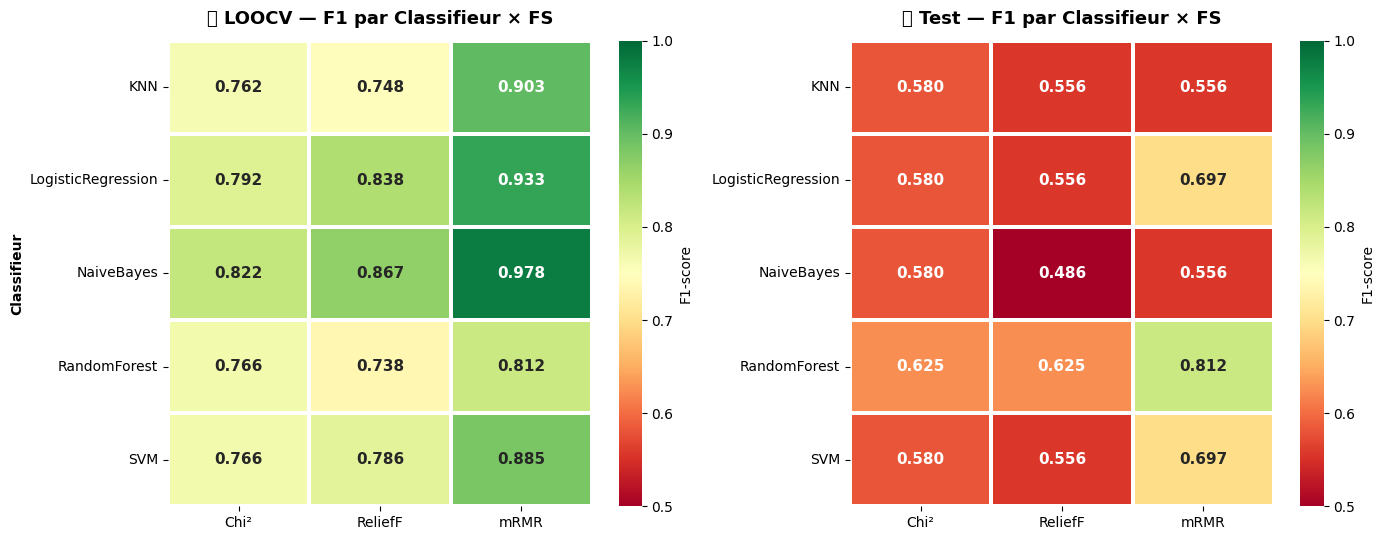

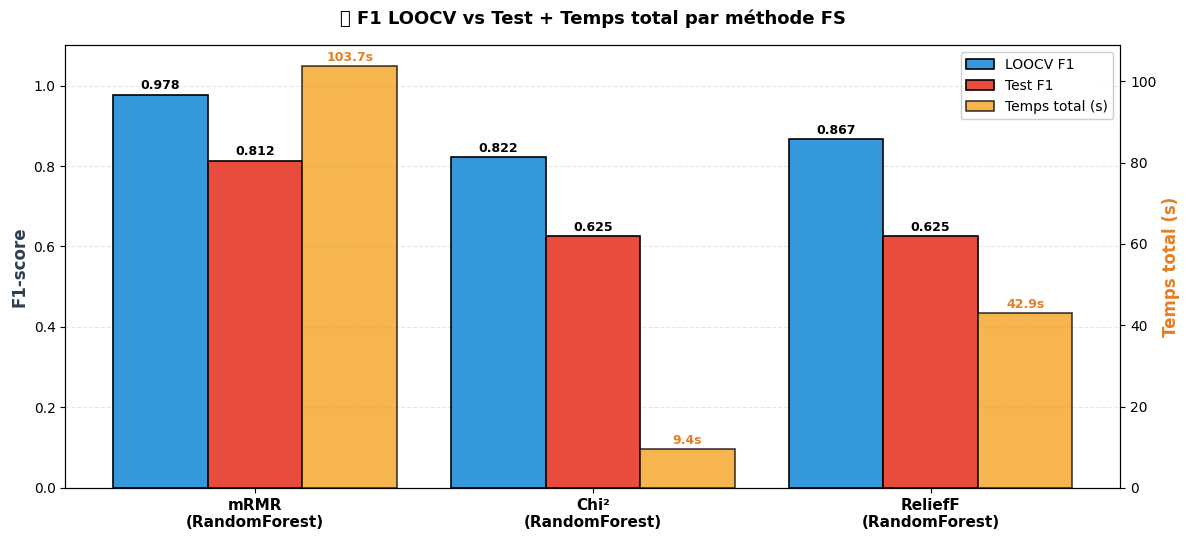

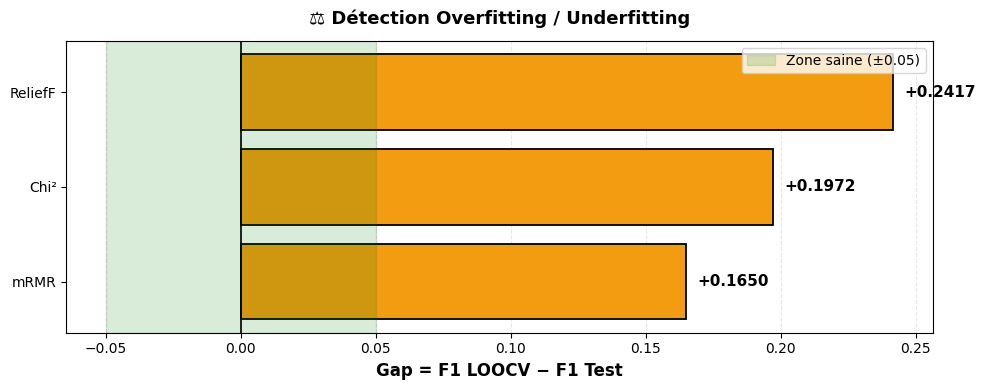


══════════════════════════════════════════════════════════════════════
  🏆 VERDICT FINAL
══════════════════════════════════════════════════════════════════════
  Meilleure méthode FS    : mRMR
  Meilleur classifieur    : RandomForest
  F1 Test                 : 0.8125
  F1 LOOCV                : 0.9775
  Gap (overfitting)       : +0.1650
  Temps total             : 103.67s

  ⚡ Méthode la plus rapide : Chi² (9.45s)
  ⚠️  Overfitting détecté (16.5% d'écart)
══════════════════════════════════════════════════════════════════════

💾 Fichiers générés :
   - fs_results.xlsx (4 feuilles)
   - fs_heatmaps.png, fs_barplot.png, fs_gap.png


In [ ]:
!pip install -q mrmr-selection skrebate

from mrmr import mrmr_classif
from skrebate import ReliefF
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.preprocessing import MinMaxScaler
import numpy as np
import pandas as pd
import time

K_adv = 50

# ══════════════════════════════════════════════════════════════
# Conversion robuste en numpy
# ══════════════════════════════════════════════════════════════
X_tr_raw = np.asarray(X_train, dtype=float)
X_te_raw = np.asarray(X_test,  dtype=float)
X_tr_sc  = np.asarray(X_train_scaled, dtype=float)
X_te_sc  = np.asarray(X_test_scaled,  dtype=float)
y_tr     = np.asarray(y_train).ravel()
y_te     = np.asarray(y_test).ravel()

fit_times = {}   # stockage des temps de fit FS

# ══════════════════════════════════════════════════════════════
# 1) Chi²
# ══════════════════════════════════════════════════════════════
mm = MinMaxScaler().fit(X_tr_raw)
X_tr_pos = mm.transform(X_tr_raw)
X_te_pos = mm.transform(X_te_raw)

t0 = time.time()
chi2_sel = SelectKBest(chi2, k=K_adv).fit(X_tr_pos, y_tr)
fit_times['Chi²'] = time.time() - t0

X_train_chi2 = chi2_sel.transform(X_tr_pos)
X_test_chi2  = chi2_sel.transform(X_te_pos)
print(f'✅ Chi²    : {X_train_chi2.shape}  — fit en {fit_times["Chi²"]:.3f}s')

# ══════════════════════════════════════════════════════════════
# 2) mRMR
# ══════════════════════════════════════════════════════════════
feat_names = [f'g{i}' for i in range(X_tr_sc.shape[1])]
X_tr_df    = pd.DataFrame(X_tr_sc, columns=feat_names)
y_tr_sr    = pd.Series(y_tr, name='target')

t0 = time.time()
mrmr_feats = mrmr_classif(X=X_tr_df, y=y_tr_sr, K=K_adv)
fit_times['mRMR'] = time.time() - t0

mrmr_idx     = [feat_names.index(f) for f in mrmr_feats]
X_train_mrmr = X_tr_sc[:, mrmr_idx]
X_test_mrmr  = X_te_sc[:, mrmr_idx]
print(f'✅ mRMR    : {X_train_mrmr.shape}  — fit en {fit_times["mRMR"]:.3f}s')

# ══════════════════════════════════════════════════════════════
# 3) ReliefF
# ══════════════════════════════════════════════════════════════
t0 = time.time()
relief = ReliefF(n_features_to_select=K_adv, n_neighbors=10, n_jobs=-1)
relief.fit(X_tr_sc, y_tr)
fit_times['ReliefF'] = time.time() - t0

X_train_relief = relief.transform(X_tr_sc)
X_test_relief  = relief.transform(X_te_sc)
print(f'✅ ReliefF : {X_train_relief.shape}  — fit en {fit_times["ReliefF"]:.3f}s')

# Résumé temps de fit
print('\n' + '─'*45)
print(f'  {"Méthode":<12} {"Fit time":>10}')
print('─'*45)
for m, t in fit_times.items():
    print(f'  {m:<12} {t:>9.3f}s')
print('─'*45)
print(f'  {"TOTAL":<12} {sum(fit_times.values()):>9.3f}s')

# ══════════════════════════════════════════════════════════════
# Évaluation LOOCV + Test (avec temps)
# ══════════════════════════════════════════════════════════════
eval_times = {}

print('\n⏳ Chi² LOOCV...')
t0 = time.time()
chi2_loocv = evaluate_loocv(X_train_chi2, y_tr)
eval_times['Chi² LOOCV'] = time.time() - t0
print(f'   ✅ terminé en {eval_times["Chi² LOOCV"]:.1f}s')

print('⏳ mRMR LOOCV...')
t0 = time.time()
mrmr_loocv = evaluate_loocv(X_train_mrmr, y_tr)
eval_times['mRMR LOOCV'] = time.time() - t0
print(f'   ✅ terminé en {eval_times["mRMR LOOCV"]:.1f}s')

print('⏳ ReliefF LOOCV...')
t0 = time.time()
relief_loocv = evaluate_loocv(X_train_relief, y_tr)
eval_times['ReliefF LOOCV'] = time.time() - t0
print(f'   ✅ terminé en {eval_times["ReliefF LOOCV"]:.1f}s')

print('⏳ Tests sets...')
t0 = time.time()
chi2_test   = evaluate_test(X_train_chi2,   y_tr, X_test_chi2,   y_te)
eval_times['Chi² Test'] = time.time() - t0

t0 = time.time()
mrmr_test   = evaluate_test(X_train_mrmr,   y_tr, X_test_mrmr,   y_te)
eval_times['mRMR Test'] = time.time() - t0

t0 = time.time()
relief_test = evaluate_test(X_train_relief, y_tr, X_test_relief, y_te)
eval_times['ReliefF Test'] = time.time() - t0

print(f'   ✅ Test sets terminés')

# ══════════════════════════════════════════════════════════════
# 1. Fusion résultats
# ══════════════════════════════════════════════════════════════
def tag(df_loocv, df_test, fs_name):
    a = df_loocv.copy().reset_index().rename(
        columns={'LOOCV Acc': 'Accuracy', 'LOOCV F1': 'F1'})
    a['FS'] = fs_name; a['Phase'] = 'LOOCV'
    b = df_test.copy().reset_index().rename(
        columns={'Test Acc': 'Accuracy', 'Test F1': 'F1'})
    b['FS'] = fs_name; b['Phase'] = 'Test'
    return pd.concat([a, b], ignore_index=True)

all_results = pd.concat([
    tag(chi2_loocv,   chi2_test,   'Chi²'),
    tag(mrmr_loocv,   mrmr_test,   'mRMR'),
    tag(relief_loocv, relief_test, 'ReliefF'),
], ignore_index=True)

# ══════════════════════════════════════════════════════════════
# 2. Tableau récapitulatif enrichi avec temps
# ══════════════════════════════════════════════════════════════
def best_row(df_loocv, df_test, fs):
    best_loo = df_loocv['LOOCV F1'].idxmax()
    best_te  = df_test['Test F1'].idxmax()
    return {
        'Méthode FS':       fs,
        'Best Clf (LOOCV)': best_loo,
        'F1 LOOCV':         df_loocv.loc[best_loo, 'LOOCV F1'],
        'Best Clf (Test)':  best_te,
        'F1 Test':          df_test.loc[best_te, 'Test F1'],
        'Fit time (s)':     round(fit_times[fs], 3),
        'LOOCV time (s)':   round(eval_times[f'{fs} LOOCV'], 2),
        'Test time (s)':    round(eval_times[f'{fs} Test'], 3),
        'Total time (s)':   round(fit_times[fs]
                                  + eval_times[f'{fs} LOOCV']
                                  + eval_times[f'{fs} Test'], 2),
    }

recap = pd.DataFrame([
    best_row(chi2_loocv,   chi2_test,   'Chi²'),
    best_row(mrmr_loocv,   mrmr_test,   'mRMR'),
    best_row(relief_loocv, relief_test, 'ReliefF'),
])
recap['Gap'] = (recap['F1 LOOCV'] - recap['F1 Test']).round(4)
recap = recap.round(4).sort_values('F1 Test', ascending=False).reset_index(drop=True)

print('\n' + '═'*75)
print('  📊 RÉCAPITULATIF — Meilleur classifieur par méthode FS')
print('═'*75)
display(recap.style
        .background_gradient(subset=['F1 LOOCV', 'F1 Test'],
                              cmap='RdYlGn', vmin=0.5, vmax=1.0)
        .background_gradient(subset=['Gap'],
                              cmap='RdYlGn_r', vmin=-0.2, vmax=0.2)
        .background_gradient(subset=['Total time (s)'],
                              cmap='Oranges')
        .format({'F1 LOOCV':       '{:.4f}',
                 'F1 Test':        '{:.4f}',
                 'Gap':            '{:+.4f}',
                 'Fit time (s)':   '{:.3f}s',
                 'LOOCV time (s)': '{:.2f}s',
                 'Test time (s)':  '{:.3f}s',
                 'Total time (s)': '{:.2f}s'})
        .set_caption('🏆 Trié par F1 Test décroissant'))

# ══════════════════════════════════════════════════════════════
# 3. Heatmaps LOOCV et Test
# ══════════════════════════════════════════════════════════════
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

pivot_loo = all_results[all_results['Phase'] == 'LOOCV'].pivot(
    index='Model', columns='FS', values='F1')
pivot_te  = all_results[all_results['Phase'] == 'Test'].pivot(
    index='Model', columns='FS', values='F1')

sns.heatmap(pivot_loo, annot=True, fmt='.3f', cmap='RdYlGn',
            vmin=0.5, vmax=1.0, linewidths=1.5, linecolor='white',
            annot_kws={'fontsize': 11, 'fontweight': 'bold'},
            cbar_kws={'label': 'F1-score'}, ax=axes[0])
axes[0].set_title('🔬 LOOCV — F1 par Classifieur × FS',
                  fontsize=13, fontweight='bold', pad=12)
axes[0].set_xlabel(''); axes[0].set_ylabel('Classifieur', fontweight='bold')

sns.heatmap(pivot_te, annot=True, fmt='.3f', cmap='RdYlGn',
            vmin=0.5, vmax=1.0, linewidths=1.5, linecolor='white',
            annot_kws={'fontsize': 11, 'fontweight': 'bold'},
            cbar_kws={'label': 'F1-score'}, ax=axes[1])
axes[1].set_title('🎯 Test — F1 par Classifieur × FS',
                  fontsize=13, fontweight='bold', pad=12)
axes[1].set_xlabel(''); axes[1].set_ylabel('')

plt.tight_layout()
plt.savefig('fs_heatmaps.png', dpi=150, bbox_inches='tight')
plt.show()

# ══════════════════════════════════════════════════════════════
# 4. Bar plot groupé F1 + temps en axe secondaire
# ══════════════════════════════════════════════════════════════
fig, ax1 = plt.subplots(figsize=(12, 5.5))
ax2 = ax1.twinx()

x = np.arange(len(recap))
w = 0.28
b1 = ax1.bar(x - w, recap['F1 LOOCV'], w, label='LOOCV F1',
             color='#3498db', edgecolor='black', linewidth=1.2)
b2 = ax1.bar(x,     recap['F1 Test'],  w, label='Test F1',
             color='#e74c3c', edgecolor='black', linewidth=1.2)
b3 = ax2.bar(x + w, recap['Total time (s)'], w, label='Temps total (s)',
             color='#f39c12', edgecolor='black', linewidth=1.2, alpha=0.75)

ax1.set_xticks(x)
ax1.set_xticklabels(
    [f"{m}\n({c})" for m, c in zip(recap['Méthode FS'], recap['Best Clf (Test)'])],
    fontsize=11, fontweight='bold')
ax1.set_ylabel('F1-score', fontsize=12, fontweight='bold', color='#2c3e50')
ax2.set_ylabel('Temps total (s)', fontsize=12, fontweight='bold', color='#e67e22')
ax1.set_title('🏆 F1 LOOCV vs Test + Temps total par méthode FS',
              fontsize=13, fontweight='bold', pad=15)
ax1.set_ylim(0, 1.10); ax1.set_axisbelow(True)
ax1.grid(axis='y', alpha=0.3, linestyle='--')

# Annotations F1
for bar in [*b1, *b2]:
    h = bar.get_height()
    ax1.annotate(f'{h:.3f}',
                 xy=(bar.get_x() + bar.get_width()/2, h),
                 xytext=(0, 4), textcoords='offset points',
                 ha='center', fontsize=9, fontweight='bold')
# Annotations temps
for bar in b3:
    h = bar.get_height()
    ax2.annotate(f'{h:.1f}s',
                 xy=(bar.get_x() + bar.get_width()/2, h),
                 xytext=(0, 4), textcoords='offset points',
                 ha='center', fontsize=9, color='#e67e22', fontweight='bold')

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2,
           loc='upper right', fontsize=10, framealpha=0.95)

plt.tight_layout()
plt.savefig('fs_barplot.png', dpi=150, bbox_inches='tight')
plt.show()

# ══════════════════════════════════════════════════════════════
# 5. Gap LOOCV − Test
# ══════════════════════════════════════════════════════════════
fig, ax = plt.subplots(figsize=(10, 4))
colors = ['#27ae60' if abs(g) < 0.05 else ('#f39c12' if g > 0 else '#e74c3c')
          for g in recap['Gap']]
bars = ax.barh(recap['Méthode FS'], recap['Gap'], color=colors,
               edgecolor='black', linewidth=1.3)
ax.axvline(0, color='black', linewidth=1.2)
ax.axvspan(-0.05, 0.05, alpha=0.15, color='green', label='Zone saine (±0.05)')
ax.set_xlabel('Gap = F1 LOOCV − F1 Test', fontsize=12, fontweight='bold')
ax.set_title('⚖️ Détection Overfitting / Underfitting',
             fontsize=13, fontweight='bold', pad=12)
ax.grid(axis='x', alpha=0.3, linestyle='--'); ax.set_axisbelow(True)
ax.legend(loc='upper right', fontsize=10)

for bar, gap in zip(bars, recap['Gap']):
    w_bar = bar.get_width()
    ax.annotate(f'{gap:+.4f}',
                xy=(w_bar, bar.get_y() + bar.get_height()/2),
                xytext=(8 if w_bar >= 0 else -8, 0),
                textcoords='offset points',
                ha='left' if w_bar >= 0 else 'right', va='center',
                fontsize=11, fontweight='bold')

plt.tight_layout()
plt.savefig('fs_gap.png', dpi=150, bbox_inches='tight')
plt.show()

# ══════════════════════════════════════════════════════════════
# 6. Verdict + export Excel
# ══════════════════════════════════════════════════════════════
best = recap.iloc[0]
fastest = recap.loc[recap['Total time (s)'].idxmin()]

print('\n' + '═'*70)
print('  🏆 VERDICT FINAL')
print('═'*70)
print(f"  Meilleure méthode FS    : {best['Méthode FS']}")
print(f"  Meilleur classifieur    : {best['Best Clf (Test)']}")
print(f"  F1 Test                 : {best['F1 Test']:.4f}")
print(f"  F1 LOOCV                : {best['F1 LOOCV']:.4f}")
print(f"  Gap (overfitting)       : {best['Gap']:+.4f}")
print(f"  Temps total             : {best['Total time (s)']:.2f}s")
print()
print(f"  ⚡ Méthode la plus rapide : {fastest['Méthode FS']}"
      f" ({fastest['Total time (s)']:.2f}s)")

if abs(best['Gap']) < 0.05:
    print("  ✅ Modèle bien généralisé (gap < 5%)")
elif best['Gap'] > 0.05:
    print(f"  ⚠️  Overfitting détecté ({best['Gap']*100:.1f}% d'écart)")
else:
    print("  ⚠️  Underfitting — le test set est plus facile que le train")
print('═'*70)

with pd.ExcelWriter('fs_results.xlsx') as w:
    recap.to_excel(w, sheet_name='Recap', index=False)
    pivot_loo.to_excel(w, sheet_name='LOOCV_F1')
    pivot_te.to_excel(w, sheet_name='Test_F1')
    all_results.to_excel(w, sheet_name='All_results', index=False)

print('\n💾 Fichiers générés :')
print('   - fs_results.xlsx (4 feuilles)')
print('   - fs_heatmaps.png, fs_barplot.png, fs_gap.png')

# 13. 🗺️ Tableau Récapitulatif Global — Toutes Méthodes


📊 F1 Macro — LOOCV (train) — Toutes méthodes
                    Baseline     PCA   ANOVA  MutualInfo     RFE  Embedded    Chi²    mRMR  ReliefF
Model                                                                                              
NaiveBayes            0.5822  0.5104  0.8667      0.6702  0.8634    0.6889  0.8222  0.9775   0.8667
LogisticRegression    0.5636  0.5728  0.8125      0.7778  0.9111    0.7656  0.7922  0.9326   0.8384
KNN                   0.5152  0.5613  0.8426      0.6999  0.5872    0.5403  0.7625  0.9030   0.7479
SVM                   0.5105  0.5901  0.7922      0.6444  0.9326    0.7922  0.7656  0.8846   0.7856
RandomForest          0.5000  0.4862  0.7576      0.8545  0.7025    0.7363  0.7656  0.8125   0.7380

🎯 F1 Macro — TEST SET    — Toutes méthodes
                    Baseline     PCA   ANOVA  MutualInfo     RFE  Embedded    Chi²    mRMR  ReliefF
Model                                                                                              
NaiveBayes 

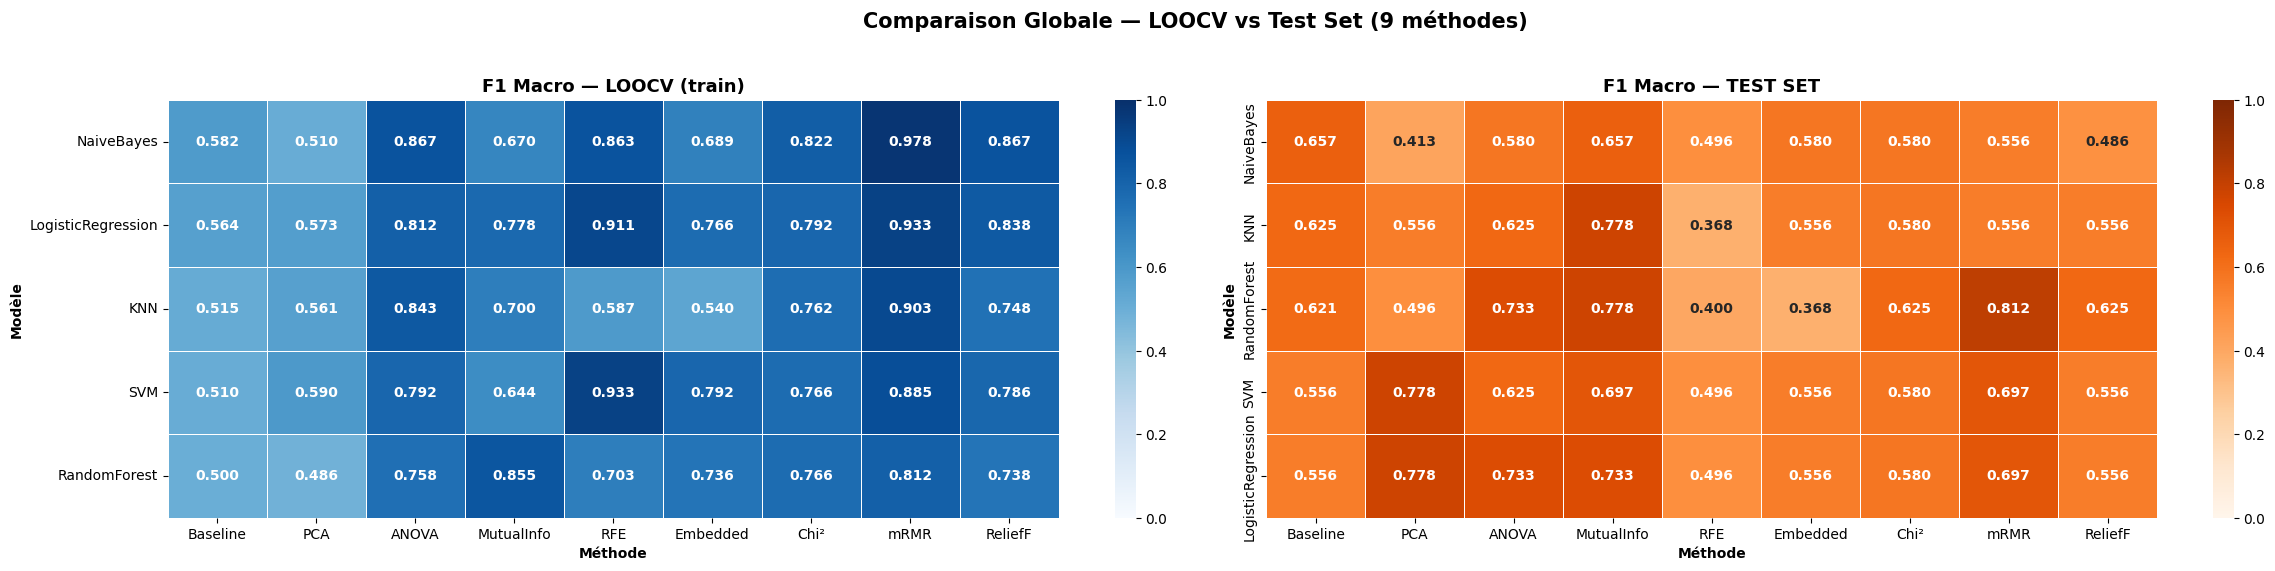

In [ ]:
# ── F1 LOOCV — toutes méthodes ─────────────────────────────────
all_loocv_f1 = pd.concat([
    baseline_loocv['LOOCV F1'].rename('Baseline'),
    pca_loocv['LOOCV F1'].rename('PCA'),
    anova_loocv['LOOCV F1'].rename('ANOVA'),
    mi_loocv['LOOCV F1'].rename('MutualInfo'),
    rfe_loocv['LOOCV F1'].rename('RFE'),
    embedded_loocv['LOOCV F1'].rename('Embedded'),
    chi2_loocv['LOOCV F1'].rename('Chi²'),
    mrmr_loocv['LOOCV F1'].rename('mRMR'),
    relief_loocv['LOOCV F1'].rename('ReliefF'),
], axis=1)

# ── F1 Test — toutes méthodes ──────────────────────────────────
all_test_f1 = pd.concat([
    baseline_test['Test F1'].rename('Baseline'),
    pca_test['Test F1'].rename('PCA'),
    anova_test['Test F1'].rename('ANOVA'),
    mi_test['Test F1'].rename('MutualInfo'),
    rfe_test['Test F1'].rename('RFE'),
    embedded_test['Test F1'].rename('Embedded'),
    chi2_test['Test F1'].rename('Chi²'),
    mrmr_test['Test F1'].rename('mRMR'),
    relief_test['Test F1'].rename('ReliefF'),
], axis=1)

print('='*90)
print('📊 F1 Macro — LOOCV (train) — Toutes méthodes')
print('='*90)
print(all_loocv_f1.round(4).to_string())

print('\n'+'='*90)
print('🎯 F1 Macro — TEST SET    — Toutes méthodes')
print('='*90)
print(all_test_f1.round(4).to_string())

# Meilleure combinaison LOOCV
best_col_loocv = all_loocv_f1.max().idxmax()
best_mod_loocv = all_loocv_f1[best_col_loocv].idxmax()
best_sc_loocv  = all_loocv_f1[best_col_loocv].max()

# Meilleure combinaison Test
best_col_test  = all_test_f1.max().idxmax()
best_mod_test  = all_test_f1[best_col_test].idxmax()
best_sc_test   = all_test_f1[best_col_test].max()

print(f'\n🏆 Meilleure LOOCV : {best_mod_loocv} + {best_col_loocv}  → F1 = {best_sc_loocv:.4f}')
print(f'🏆 Meilleure Test  : {best_mod_test}  + {best_col_test}   → F1 = {best_sc_test:.4f}')

# Heatmaps côte à côte
fig, axes = plt.subplots(1, 2, figsize=(24, 5.5))
sns.heatmap(all_loocv_f1, annot=True, fmt='.3f', cmap='Blues',
            linewidths=0.5, vmin=0, vmax=1, ax=axes[0],
            annot_kws={'fontsize': 10, 'fontweight': 'bold'})
axes[0].set_title('F1 Macro — LOOCV (train)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Méthode', fontweight='bold')
axes[0].set_ylabel('Modèle', fontweight='bold')

sns.heatmap(all_test_f1, annot=True, fmt='.3f', cmap='Oranges',
            linewidths=0.5, vmin=0, vmax=1, ax=axes[1],
            annot_kws={'fontsize': 10, 'fontweight': 'bold'})
axes[1].set_title('F1 Macro — TEST SET', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Méthode', fontweight='bold')
axes[1].set_ylabel('Modèle', fontweight='bold')

plt.suptitle('Comparaison Globale — LOOCV vs Test Set (9 méthodes)',
             fontsize=15, fontweight='bold', y=1.03)
plt.tight_layout()
plt.savefig('global_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

⚖️ GAP = F1 LOOCV − F1 Test  (positif = overfitting, négatif = underfitting)
                    Baseline     PCA   ANOVA  MutualInfo     RFE  Embedded    Chi²    mRMR  ReliefF
Model                                                                                              
KNN                  -0.1098  0.0058  0.2176     -0.0779  0.2188   -0.0153  0.1821  0.3475   0.1923
LogisticRegression    0.0081 -0.2049  0.0792      0.0444  0.4153    0.2101  0.2118  0.2351   0.2828
NaiveBayes           -0.0749  0.0978  0.2862      0.0130  0.3676    0.1085  0.2418  0.4220   0.3810
RandomForest         -0.1211 -0.0096  0.0242      0.0768  0.3025    0.3678  0.1406  0.0000   0.1130
SVM                  -0.0451 -0.1876  0.1672     -0.0530  0.4368    0.2367  0.1852  0.1871   0.2301


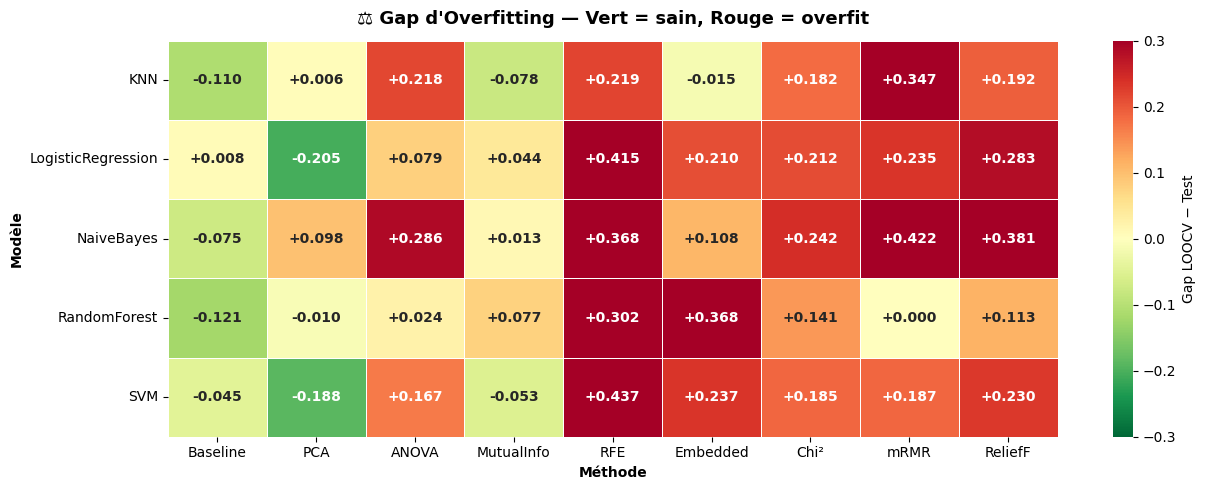


🏆 TOP 5 — Meilleures combinaisons (F1 Test élevé + Gap faible)


,Méthode,Modèle,F1 LOOCV,F1 Test,Gap,Score
0,mRMR,RandomForest,0.8125,0.8125,+0.0000,0.8125
1,MutualInfo,RandomForest,0.8545,0.7778,+0.0768,0.7394
2,MutualInfo,KNN,0.6999,0.7778,-0.0779,0.7388
3,ANOVA,RandomForest,0.7576,0.7333,+0.0242,0.7212
4,MutualInfo,LogisticRegression,0.7778,0.7333,+0.0444,0.7111


In [ ]:
# ── Tableau du Gap (LOOCV − Test) ──────────────────────────────
gap_df = (all_loocv_f1 - all_test_f1).round(4)

print('='*90)
print('⚖️ GAP = F1 LOOCV − F1 Test  (positif = overfitting, négatif = underfitting)')
print('='*90)
print(gap_df.to_string())

fig, ax = plt.subplots(figsize=(13, 5))
sns.heatmap(gap_df, annot=True, fmt='+.3f', cmap='RdYlGn_r',
            center=0, vmin=-0.3, vmax=0.3,
            linewidths=0.5, linecolor='white',
            annot_kws={'fontsize': 10, 'fontweight': 'bold'},
            cbar_kws={'label': 'Gap LOOCV − Test'}, ax=ax)
ax.set_title('⚖️ Gap d\'Overfitting — Vert = sain, Rouge = overfit',
             fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Méthode', fontweight='bold')
ax.set_ylabel('Modèle', fontweight='bold')
plt.tight_layout()
plt.savefig('gap_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

# Top 5 combinaisons les plus stables (gap minimal ET F1 Test élevé)
combos = []
for fs in all_test_f1.columns:
    for mdl in all_test_f1.index:
        combos.append({
            'Méthode': fs,
            'Modèle': mdl,
            'F1 LOOCV': all_loocv_f1.loc[mdl, fs],
            'F1 Test':  all_test_f1.loc[mdl, fs],
            'Gap':      gap_df.loc[mdl, fs],
        })
combos_df = pd.DataFrame(combos)
# Score combiné : F1 Test élevé ET gap faible
combos_df['Score'] = combos_df['F1 Test'] - 0.5 * combos_df['Gap'].abs()
top5 = combos_df.sort_values('Score', ascending=False).head(5).reset_index(drop=True)

print('\n'+'='*90)
print('🏆 TOP 5 — Meilleures combinaisons (F1 Test élevé + Gap faible)')
print('='*90)
display(top5.style
        .background_gradient(subset=['F1 Test'], cmap='Greens')
        .background_gradient(subset=['Gap'], cmap='RdYlGn_r', vmin=-0.2, vmax=0.2)
        .format({'F1 LOOCV': '{:.4f}', 'F1 Test': '{:.4f}',
                 'Gap': '{:+.4f}', 'Score': '{:.4f}'}))

# 17. 🔬 Feature Selection — Wrapper & Embedded Methods

## 🎯 Objectif
Comparer deux familles avancées de sélection de features sur le dataset, en évaluant chaque sous-ensemble avec **5 classifieurs** et en mesurant le **gap d'overfitting** (LOOCV − Test).

## 🔧 Méthodes Wrapper
Évaluent itérativement des sous-ensembles en entraînant un modèle à chaque étape.

- **FFS (Forward Feature Selection)** — Part de zéro et ajoute la meilleure feature à chaque étape
- **BFS (Backward Feature Selection)** — Part de toutes les features et retire la pire à chaque étape
- **RFE (Recursive Feature Elimination)** — Élimine récursivement les features les moins importantes selon les coefficients/importances du modèle

## 🧬 Méthodes Embedded
La sélection est intégrée directement à l'apprentissage du modèle.

- **SVM-RFE** — RFE basé sur les coefficients d'un SVM linéaire
- **L1 (Lasso)** — Régression logistique avec pénalité L1, met les coefficients non pertinents à zéro
- **RF Importance** — Sélection via les feature importances d'un Random Forest

## 📊 Évaluation
Chaque sous-ensemble est testé avec **5 classifieurs** (RandomForest, SVM, KNN, LogisticRegression, NaiveBayes) en LOOCV (train) et sur le test set, avec calcul du gap pour détecter l'overfitting.

🔧 Pré-filtre ANOVA (200 features) pour FFS/BFS uniquement...

⏳ FFS (Forward, K auto)...
   ✅ 7 features | 78.2s
⏳ BFS (Backward, K auto)...
   ✅ 199 features | 12.0s
⏳ RFECV (Logistic Regression)...
   ✅ 9 features | 1.4s
⏳ SVM-RFECV...
   ✅ 9 features | 0.5s
⏳ L1 (LogisticRegressionCV)...
   ✅ 11 features | 0.6s
⏳ RF Importance...
   ✅ 1108 features | 0.8s

📊 Récapitulatif sélection :


,Méthode,N_features,Temps (s)
0,FFS,7,78.220000
1,BFS,199,11.970000
2,RFE-LR,9,1.370000
3,SVM-RFE,9,0.530000
4,L1,11,0.640000
5,RF-Imp,1108,0.770000



🎯 Évaluation 6 FS × 5 classifieurs
═══════════════════════════════════════════════════════════════════════════
  FFS      | RandomForest       | K=  7 | LOOCV=0.7500 | Test=0.4000 | Gap=+0.3500
  FFS      | SVM                | K=  7 | LOOCV=0.9583 | Test=0.5556 | Gap=+0.4028
  FFS      | KNN                | K=  7 | LOOCV=0.8958 | Test=0.5556 | Gap=+0.3403
  FFS      | LogisticRegression | K=  7 | LOOCV=0.9375 | Test=0.5556 | Gap=+0.3819
  FFS      | NaiveBayes         | K=  7 | LOOCV=0.8750 | Test=0.4958 | Gap=+0.3792
  BFS      | RandomForest       | K=199 | LOOCV=0.7708 | Test=0.5556 | Gap=+0.2153
  BFS      | SVM                | K=199 | LOOCV=0.8958 | Test=0.6975 | Gap=+0.1984
  BFS      | KNN                | K=199 | LOOCV=0.8958 | Test=0.3684 | Gap=+0.5274
  BFS      | LogisticRegression | K=199 | LOOCV=0.9375 | Test=0.6250 | Gap=+0.3125
  BFS      | NaiveBayes         | K=199 | LOOCV=0.8542 | Test=0.5556 | Gap=+0.2986
  RFE-LR   | RandomForest       | K=  9 | LOOCV=0.7292 | T

,FS,Classifier,N_feat,F1_LOOCV,F1_Test,Gap,FS_time(s),Eval_time(s)
0,BFS,SVM,199,0.8958,0.6975,+0.1984,11.970000,0.180000
1,RFE-LR,NaiveBayes,9,0.7708,0.6571,+0.1137,1.370000,0.180000
2,SVM-RFE,NaiveBayes,9,0.7708,0.6571,+0.1137,0.530000,0.210000
3,BFS,LogisticRegression,199,0.9375,0.6250,+0.3125,11.970000,0.340000
4,L1,RandomForest,11,0.6042,0.6211,-0.0169,0.640000,8.770000
5,L1,SVM,11,0.6667,0.5804,+0.0862,0.640000,0.400000
6,RF-Imp,NaiveBayes,1108,0.7292,0.5804,+0.1487,0.770000,0.420000
7,L1,LogisticRegression,11,0.6667,0.5804,+0.0862,0.640000,0.620000
8,L1,NaiveBayes,11,0.5833,0.5804,+0.0029,0.640000,0.240000
9,BFS,NaiveBayes,199,0.8542,0.5556,+0.2986,11.970000,0.180000


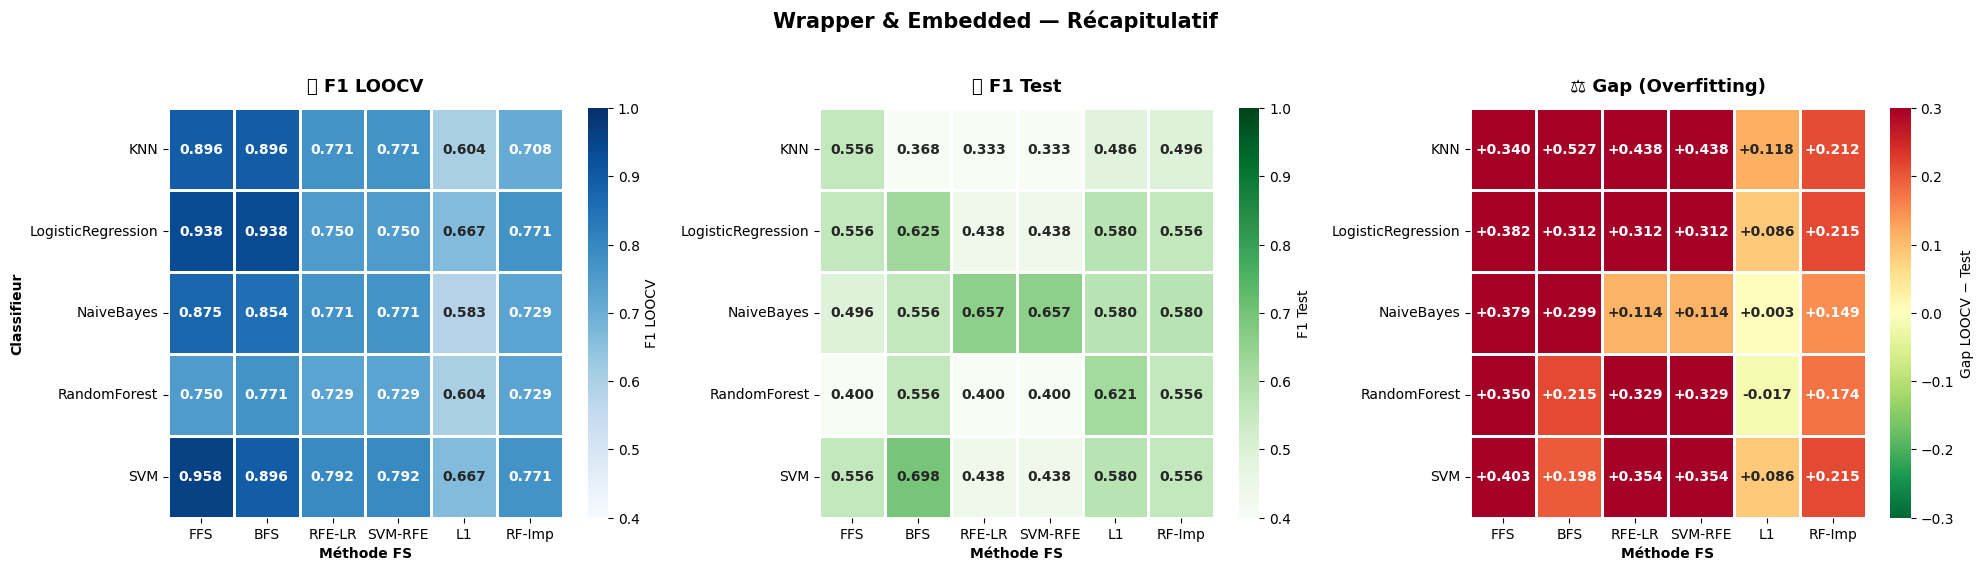


═══════════════════════════════════════════════════════════════════════════
  🏆 VERDICT — Meilleure combinaison
═══════════════════════════════════════════════════════════════════════════
  Méthode FS    : BFS (199 features, 11.97s)
  Classifieur   : SVM
  F1 LOOCV      : 0.8958
  F1 Test       : 0.6975
  Gap           : +0.1984
  ⚠️  Léger overfitting
═══════════════════════════════════════════════════════════════════════════

💾 Sauvegardé : wrapper_embedded.xlsx + wrapper_embedded.png


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
from sklearn.feature_selection import (RFE, RFECV, SequentialFeatureSelector,
                                       SelectFromModel, SelectKBest, f_classif)
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import cross_val_score, LeaveOneOut, StratifiedKFold
from sklearn.metrics import f1_score
from sklearn.base import clone

X_tr = np.asarray(X_train_scaled, dtype=float)
X_te = np.asarray(X_test_scaled, dtype=float)
y_tr_a = np.asarray(y_tr).ravel()
y_te_a = np.asarray(y_te).ravel()

cv_inner = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# ══════════════════════════════════════════════════════════════
# Pré-filtre ANOVA pour rendre FFS/BFS calculables
# (sinon FFS sur 7130 features = plusieurs heures)
# ══════════════════════════════════════════════════════════════
print('🔧 Pré-filtre ANOVA (200 features) pour FFS/BFS uniquement...')
prefilter = SelectKBest(f_classif, k=min(200, X_tr.shape[1])).fit(X_tr, y_tr_a)
X_tr_pre = prefilter.transform(X_tr)
X_te_pre = prefilter.transform(X_te)
pre_idx = np.where(prefilter.get_support())[0]

# ══════════════════════════════════════════════════════════════
# Sélection — chaque méthode trouve son propre K optimal
# ══════════════════════════════════════════════════════════════
selected = {}
times    = {}

# ── 1) FFS — sélectionne automatiquement avec tol ──
print('\n⏳ FFS (Forward, K auto)...')
t0 = time.time()
ffs = SequentialFeatureSelector(LogisticRegression(max_iter=2000),
                                n_features_to_select='auto', tol=1e-3,
                                direction='forward',
                                scoring='f1_macro', cv=cv_inner, n_jobs=-1)
ffs.fit(X_tr_pre, y_tr_a)
times['FFS'] = time.time() - t0
local_idx = np.where(ffs.get_support())[0]
selected['FFS'] = pre_idx[local_idx]
print(f'   ✅ {len(selected["FFS"])} features | {times["FFS"]:.1f}s')

# ── 2) BFS — sélectionne automatiquement avec tol ──
print('⏳ BFS (Backward, K auto)...')
t0 = time.time()
bfs = SequentialFeatureSelector(LogisticRegression(max_iter=2000),
                                n_features_to_select='auto', tol=1e-3,
                                direction='backward',
                                scoring='f1_macro', cv=cv_inner, n_jobs=-1)
bfs.fit(X_tr_pre, y_tr_a)
times['BFS'] = time.time() - t0
local_idx = np.where(bfs.get_support())[0]
selected['BFS'] = pre_idx[local_idx]
print(f'   ✅ {len(selected["BFS"])} features | {times["BFS"]:.1f}s')

# ── 3) RFE-CV (LR) — K optimal par CV ──
print('⏳ RFECV (Logistic Regression)...')
t0 = time.time()
rfecv = RFECV(LogisticRegression(max_iter=2000), step=0.1,
              cv=cv_inner, scoring='f1_macro', n_jobs=-1, min_features_to_select=5)
rfecv.fit(X_tr, y_tr_a)
times['RFE-LR'] = time.time() - t0
selected['RFE-LR'] = np.where(rfecv.support_)[0]
print(f'   ✅ {len(selected["RFE-LR"])} features | {times["RFE-LR"]:.1f}s')

# ── 4) SVM-RFECV — K optimal par CV ──
print('⏳ SVM-RFECV...')
t0 = time.time()
svm_rfecv = RFECV(SVC(kernel='linear', C=1.0), step=0.1,
                  cv=cv_inner, scoring='f1_macro', n_jobs=-1, min_features_to_select=5)
svm_rfecv.fit(X_tr, y_tr_a)
times['SVM-RFE'] = time.time() - t0
selected['SVM-RFE'] = np.where(svm_rfecv.support_)[0]
print(f'   ✅ {len(selected["SVM-RFE"])} features | {times["SVM-RFE"]:.1f}s')

# ── 5) L1 (Lasso CV) — K déterminé par la régularisation ──
print('⏳ L1 (LogisticRegressionCV)...')
t0 = time.time()
lr_cv = LogisticRegressionCV(Cs=10, penalty='l1', solver='liblinear',
                             cv=cv_inner, max_iter=2000, scoring='f1_macro')
l1 = SelectFromModel(lr_cv).fit(X_tr, y_tr_a)
times['L1'] = time.time() - t0
selected['L1'] = np.where(l1.get_support())[0]
print(f'   ✅ {len(selected["L1"])} features | {times["L1"]:.1f}s')

# ── 6) RF Importance — seuil = mean ──
print('⏳ RF Importance...')
t0 = time.time()
rf_imp = SelectFromModel(RandomForestClassifier(n_estimators=300,
                                                random_state=42, n_jobs=-1),
                         threshold='mean').fit(X_tr, y_tr_a)
times['RF-Imp'] = time.time() - t0
selected['RF-Imp'] = np.where(rf_imp.get_support())[0]
print(f'   ✅ {len(selected["RF-Imp"])} features | {times["RF-Imp"]:.1f}s')

print('\n📊 Récapitulatif sélection :')
sel_summary = pd.DataFrame([
    {'Méthode': k, 'N_features': len(v), 'Temps (s)': round(times[k], 2)}
    for k, v in selected.items()
])
display(sel_summary.style
        .background_gradient(subset=['Temps (s)'], cmap='Reds')
        .background_gradient(subset=['N_features'], cmap='Blues'))

# ══════════════════════════════════════════════════════════════
# Évaluation : 6 méthodes × 5 classifieurs
# ══════════════════════════════════════════════════════════════
classifiers = {
    'RandomForest':       RandomForestClassifier(n_estimators=100,
                                                 class_weight='balanced',
                                                 random_state=42, n_jobs=-1),
    'SVM':                SVC(kernel='linear', C=1.0, class_weight='balanced'),
    'KNN':                KNeighborsClassifier(n_neighbors=5),
    'LogisticRegression': LogisticRegression(max_iter=2000, class_weight='balanced'),
    'NaiveBayes':         GaussianNB(),
}

loo = LeaveOneOut()
results = []

print('\n🎯 Évaluation 6 FS × 5 classifieurs')
print('═'*75)
for fs_name, idx in selected.items():
    if len(idx) == 0:
        print(f'⚠️ {fs_name} : aucune feature sélectionnée, skip')
        continue
    Xtr_sel = X_tr[:, idx]
    Xte_sel = X_te[:, idx]
    for clf_name, clf in classifiers.items():
        t0 = time.time()
        c1 = clone(clf)
        f1_loocv = cross_val_score(c1, Xtr_sel, y_tr_a, cv=loo,
                                   scoring='f1_macro', n_jobs=-1).mean()
        c2 = clone(clf)
        c2.fit(Xtr_sel, y_tr_a)
        f1_test = f1_score(y_te_a, c2.predict(Xte_sel), average='macro')
        eval_time = time.time() - t0
        results.append({
            'FS': fs_name, 'Classifier': clf_name,
            'N_feat': len(idx),
            'F1_LOOCV': f1_loocv, 'F1_Test': f1_test,
            'Gap': f1_loocv - f1_test,
            'FS_time(s)': round(times[fs_name], 2),
            'Eval_time(s)': round(eval_time, 2),
        })
        print(f'  {fs_name:8s} | {clf_name:18s} | K={len(idx):3d} | '
              f'LOOCV={f1_loocv:.4f} | Test={f1_test:.4f} | '
              f'Gap={f1_loocv - f1_test:+.4f}')

df_res = pd.DataFrame(results).round(4)

# ══════════════════════════════════════════════════════════════
# Pivots & Top 10
# ══════════════════════════════════════════════════════════════
fs_order = [k for k in ['FFS','BFS','RFE-LR','SVM-RFE','L1','RF-Imp']
            if k in df_res['FS'].values]
pivot_test  = df_res.pivot(index='Classifier', columns='FS', values='F1_Test')[fs_order]
pivot_loocv = df_res.pivot(index='Classifier', columns='FS', values='F1_LOOCV')[fs_order]
pivot_gap   = df_res.pivot(index='Classifier', columns='FS', values='Gap')[fs_order]

top10 = df_res.sort_values('F1_Test', ascending=False).head(10).reset_index(drop=True)

print('\n' + '═'*75)
print('  🏆 TOP 10 — Meilleures combinaisons (F1 Test)')
print('═'*75)
display(top10.style
        .background_gradient(subset=['F1_Test'], cmap='Greens')
        .background_gradient(subset=['Gap'], cmap='RdYlGn_r', vmin=-0.2, vmax=0.2)
        .format({'F1_LOOCV': '{:.4f}', 'F1_Test': '{:.4f}', 'Gap': '{:+.4f}'}))

# ══════════════════════════════════════════════════════════════
# Heatmap récapitulative (3 panels)
# ══════════════════════════════════════════════════════════════
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))

sns.heatmap(pivot_loocv, annot=True, fmt='.3f', cmap='Blues',
            vmin=0.4, vmax=1.0, linewidths=1, linecolor='white',
            annot_kws={'fontsize': 10, 'fontweight': 'bold'},
            cbar_kws={'label': 'F1 LOOCV'}, ax=axes[0])
axes[0].set_title('🔬 F1 LOOCV', fontsize=13, fontweight='bold', pad=12)
axes[0].set_xlabel('Méthode FS', fontweight='bold')
axes[0].set_ylabel('Classifieur', fontweight='bold')

sns.heatmap(pivot_test, annot=True, fmt='.3f', cmap='Greens',
            vmin=0.4, vmax=1.0, linewidths=1, linecolor='white',
            annot_kws={'fontsize': 10, 'fontweight': 'bold'},
            cbar_kws={'label': 'F1 Test'}, ax=axes[1])
axes[1].set_title('🎯 F1 Test', fontsize=13, fontweight='bold', pad=12)
axes[1].set_xlabel('Méthode FS', fontweight='bold')
axes[1].set_ylabel('')

sns.heatmap(pivot_gap, annot=True, fmt='+.3f', cmap='RdYlGn_r',
            center=0, vmin=-0.3, vmax=0.3,
            linewidths=1, linecolor='white',
            annot_kws={'fontsize': 10, 'fontweight': 'bold'},
            cbar_kws={'label': 'Gap LOOCV − Test'}, ax=axes[2])
axes[2].set_title('⚖️ Gap (Overfitting)', fontsize=13, fontweight='bold', pad=12)
axes[2].set_xlabel('Méthode FS', fontweight='bold')
axes[2].set_ylabel('')

plt.suptitle('Wrapper & Embedded — Récapitulatif',
             fontsize=15, fontweight='bold', y=1.03)
plt.tight_layout()
plt.savefig('wrapper_embedded.png', dpi=150, bbox_inches='tight')
plt.show()

# Verdict
best = top10.iloc[0]
print('\n' + '═'*75)
print('  🏆 VERDICT — Meilleure combinaison')
print('═'*75)
print(f"  Méthode FS    : {best['FS']} ({best['N_feat']} features, "
      f"{best['FS_time(s)']}s)")
print(f"  Classifieur   : {best['Classifier']}")
print(f"  F1 LOOCV      : {best['F1_LOOCV']:.4f}")
print(f"  F1 Test       : {best['F1_Test']:.4f}")
print(f"  Gap           : {best['Gap']:+.4f}")
if abs(best['Gap']) < 0.05:
    print("  ✅ Modèle bien généralisé")
else:
    print("  ⚠️  Léger overfitting")
print('═'*75)

with pd.ExcelWriter('wrapper_embedded.xlsx') as w:
    df_res.to_excel(w, sheet_name='All_results', index=False)
    sel_summary.to_excel(w, sheet_name='Selection_summary', index=False)
    pivot_test.to_excel(w, sheet_name='F1_Test')
    pivot_loocv.to_excel(w, sheet_name='F1_LOOCV')
    pivot_gap.to_excel(w, sheet_name='Gap')
    top10.to_excel(w, sheet_name='Top10', index=False)
print('\n💾 Sauvegardé : wrapper_embedded.xlsx + wrapper_embedded.png')

# 14b. ⚖️ Rééchantillonnage avancé — BorderlineSMOTE & SMOTE+Tomek
**Alternatives à BalancedBagging** : génèrent de l'info au lieu d'en jeter

In [ ]:
from imblearn.over_sampling import BorderlineSMOTE, ADASYN
from imblearn.combine import SMOTETomek, SMOTEENN
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.svm import SVC

k_nn = max(1, min(5, pd.Series(y_train).value_counts().min() - 1))
samplers = {
    'BorderlineSMOTE': BorderlineSMOTE(k_neighbors=k_nn, random_state=42),
    'ADASYN':          ADASYN(n_neighbors=k_nn, random_state=42),
    'SMOTE+Tomek':     SMOTETomek(random_state=42),
    'SMOTE+ENN':       SMOTEENN(random_state=42),
}
clf_base = SVC(kernel='linear', C=1.0, class_weight='balanced')

resamp_results = []
# On teste sur les meilleures FS : mRMR, ReliefF, Mutual Info
datasets = {'mRMR': (X_train_mrmr, X_test_mrmr),
            'ReliefF': (X_train_relief, X_test_relief),
            'Chi2': (X_train_chi2, X_test_chi2)}
for fs_name, (Xtr, Xte) in datasets.items():
    for sname, samp in samplers.items():
        pipe = ImbPipeline([('res', samp), ('clf', clf_base)])
        loo = evaluate_loocv(Xtr, y_train)  # baseline FS
        Xr, yr = samp.fit_resample(Xtr, y_train)
        clf_base.fit(Xr, yr)
        from sklearn.metrics import f1_score
        f1_te = f1_score(y_test, clf_base.predict(Xte), average='weighted')
        resamp_results.append({'FS': fs_name, 'Resampling': sname, 'F1_test': f1_te})
        print(f'{fs_name:8s} | {sname:16s} | F1_test={f1_te:.4f}')

df_resamp = pd.DataFrame(resamp_results).sort_values('F1_test', ascending=False)
df_resamp

mRMR     | BorderlineSMOTE  | F1_test=0.7395
mRMR     | ADASYN           | F1_test=0.7395
mRMR     | SMOTE+Tomek      | F1_test=0.7395
mRMR     | SMOTE+ENN        | F1_test=0.5926
ReliefF  | BorderlineSMOTE  | F1_test=0.5926
ReliefF  | ADASYN           | F1_test=0.5926
ReliefF  | SMOTE+Tomek      | F1_test=0.6667
ReliefF  | SMOTE+ENN        | F1_test=0.5926
Chi2     | BorderlineSMOTE  | F1_test=0.5921
Chi2     | ADASYN           | F1_test=0.5000
Chi2     | SMOTE+Tomek      | F1_test=0.5921
Chi2     | SMOTE+ENN        | F1_test=0.5000


,FS,Resampling,F1_test
0,mRMR,BorderlineSMOTE,0.739496
1,mRMR,ADASYN,0.739496
2,mRMR,SMOTE+Tomek,0.739496
6,ReliefF,SMOTE+Tomek,0.666667
3,mRMR,SMOTE+ENN,0.592593
4,ReliefF,BorderlineSMOTE,0.592593
5,ReliefF,ADASYN,0.592593
7,ReliefF,SMOTE+ENN,0.592593
8,Chi2,BorderlineSMOTE,0.592075
10,Chi2,SMOTE+Tomek,0.592075


✅ PCA terminé
✅ ANOVA terminé
✅ MutualInfo terminé
✅ RFE terminé
✅ Embedded terminé
✅ Chi² terminé
✅ mRMR terminé
✅ ReliefF terminé
════════════════════════════════════════════════════════════════════════════════════════════════════
  📊 F1 Test — Meilleur classifieur par combinaison (FS × Resampling)
════════════════════════════════════════════════════════════════════════════════════════════════════


FS,PCA,ANOVA,MutualInfo,RFE,Embedded,Chi²,mRMR,ReliefF
Resampling,,,,,,,,
ADASYN,0.7778,0.7333,0.7333,0.4958,0.6975,0.5804,0.7333,0.6250
BBC,0.6250,0.7333,0.7333,0.5556,0.6571,0.6571,0.7333,0.6250
BorderlineSMOTE,0.7778,0.8125,0.7778,0.4958,0.7333,0.5804,0.7333,0.5556
SMOTE+ENN,0.5000,0.5804,0.8125,0.3684,0.6571,0.5804,0.6975,0.5556
SMOTE+Tomek,0.7778,0.7333,0.7333,0.4958,0.7333,0.5804,0.6975,0.6250



════════════════════════════════════════════════════════════════════════════════
  🏆 TOP 15 — Meilleures combinaisons FS × Resampling × Classifieur
════════════════════════════════════════════════════════════════════════════════


,FS,Resampling,Classifier,F1_Test
0,MutualInfo,SMOTE+ENN,NaiveBayes,0.8125
1,ANOVA,BorderlineSMOTE,RandomForest,0.8125
2,PCA,BorderlineSMOTE,SVM,0.7778
3,PCA,BorderlineSMOTE,LogisticRegression,0.7778
4,PCA,ADASYN,LogisticRegression,0.7778
5,PCA,SMOTE+Tomek,LogisticRegression,0.7778
6,PCA,ADASYN,SVM,0.7778
7,MutualInfo,BorderlineSMOTE,RandomForest,0.7778
8,PCA,SMOTE+Tomek,SVM,0.7778
9,MutualInfo,BBC,BBC-Tree,0.7333


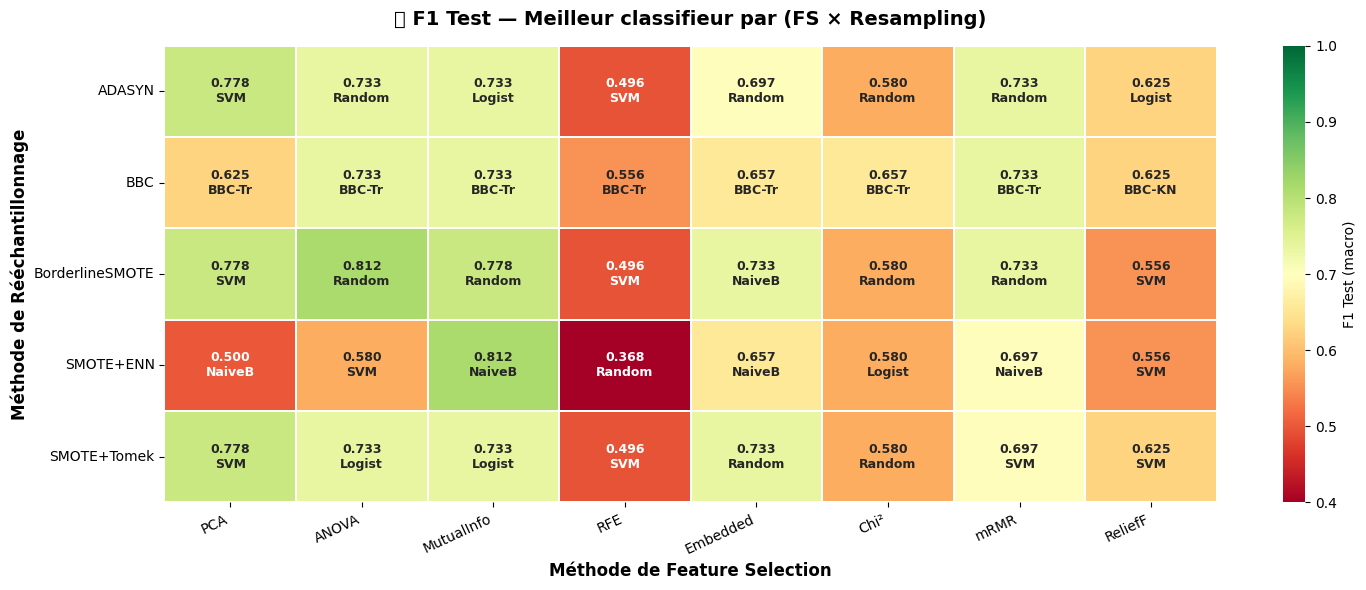

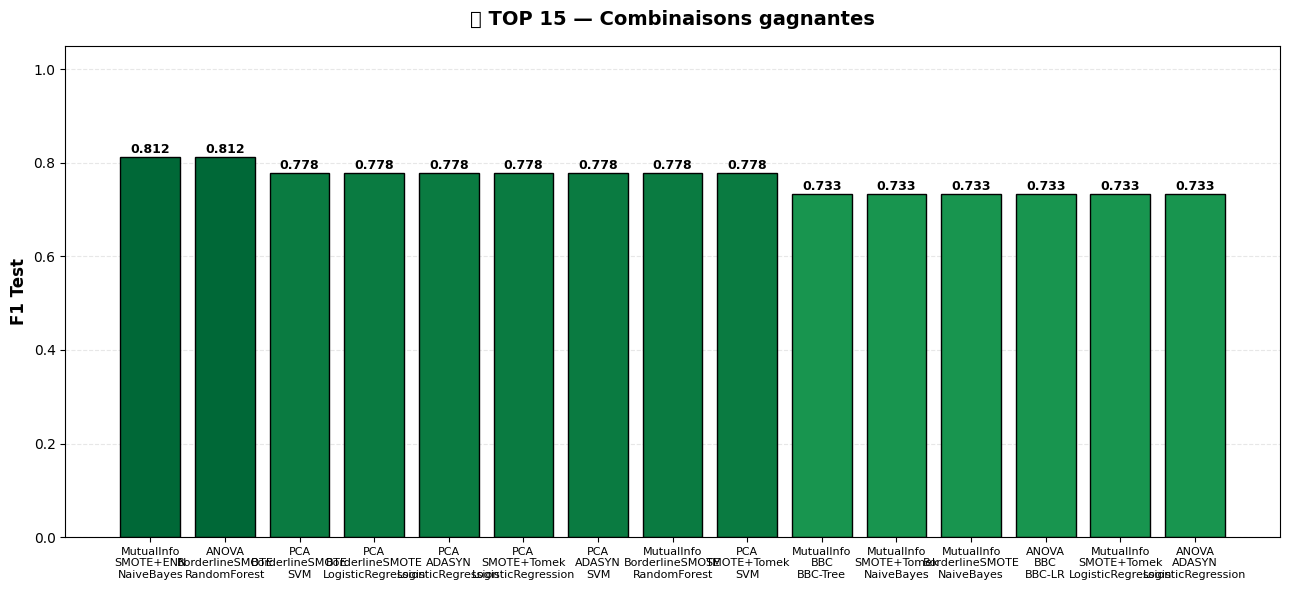


══════════════════════════════════════════════════════════════════════
  🏆 VERDICT FINAL
══════════════════════════════════════════════════════════════════════
  FS                : MutualInfo
  Resampling        : SMOTE+ENN
  Classifieur       : NaiveBayes
  F1 Test           : 0.8125
══════════════════════════════════════════════════════════════════════

💾 Fichiers : resampling_full_v2.xlsx, resampling_full_heatmap.png, top15_combos.png


In [ ]:
from imblearn.over_sampling import BorderlineSMOTE, ADASYN
from imblearn.combine import SMOTETomek, SMOTEENN
from imblearn.ensemble import BalancedBaggingClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import f1_score
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns

k_nn = max(1, min(5, pd.Series(y_tr).value_counts().min() - 1))

# ── Datasets FS ────────────────────────────────────────────────
fs_datasets = {
    'PCA':        (X_train_pca,    X_test_pca),
    'ANOVA':      (X_train_anova,  X_test_anova),
    'MutualInfo': (X_train_mi,     X_test_mi),
    'RFE':        (X_train_rfe,    X_test_rfe),
    'Embedded':   (X_train_emb,    X_test_emb),
    'Chi²':       (X_train_chi2,   X_test_chi2),
    'mRMR':       (X_train_mrmr,   X_test_mrmr),
    'ReliefF':    (X_train_relief, X_test_relief),
}

# ── 5 classifieurs (mêmes que dans evaluate_test) ──────────────
classifiers = {
    'RandomForest':       RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced'),
    'SVM':                SVC(kernel='linear', C=1.0, class_weight='balanced'),
    'KNN':                KNeighborsClassifier(n_neighbors=5),
    'LogisticRegression': LogisticRegression(max_iter=2000, class_weight='balanced'),
    'NaiveBayes':         GaussianNB(),
}

# ── 4 samplers + BBC traité à part ─────────────────────────────
samplers = {
    'BorderlineSMOTE': BorderlineSMOTE(k_neighbors=k_nn, random_state=42),
    'ADASYN':          ADASYN(n_neighbors=k_nn, random_state=42),
    'SMOTE+Tomek':     SMOTETomek(random_state=42),
    'SMOTE+ENN':       SMOTEENN(random_state=42),
}

# ══════════════════════════════════════════════════════════════
# Boucle : FS × Resampling × Classifieur
# ══════════════════════════════════════════════════════════════
results = []
for fs_name, (Xtr, Xte) in fs_datasets.items():
    Xtr_arr = np.asarray(Xtr); Xte_arr = np.asarray(Xte)

    # ── 4 samplers × 5 classifieurs ──
    for samp_name, samp in samplers.items():
        try:
            Xr, yr = samp.fit_resample(Xtr_arr, y_tr)
            for clf_name, clf in classifiers.items():
                from sklearn.base import clone
                c = clone(clf)
                c.fit(Xr, yr)
                f1 = f1_score(y_te, c.predict(Xte_arr), average='macro')
                results.append({'FS': fs_name, 'Resampling': samp_name,
                                'Classifier': clf_name, 'F1_Test': f1})
        except Exception as e:
            for clf_name in classifiers:
                results.append({'FS': fs_name, 'Resampling': samp_name,
                                'Classifier': clf_name, 'F1_Test': np.nan})
            print(f'⚠️ {fs_name} + {samp_name} failed: {str(e)[:60]}')

    # ── BBC : 5 versions, une par base estimator ──
    bbc_bases = {
        'BBC-Tree':   DecisionTreeClassifier(random_state=42),
        'BBC-LR':     LogisticRegression(max_iter=2000),
        'BBC-KNN':    KNeighborsClassifier(n_neighbors=5),
        'BBC-NB':     GaussianNB(),
        'BBC-SVM':    SVC(kernel='linear', C=1.0),
    }
    for bbc_name, base_est in bbc_bases.items():
        try:
            bbc = BalancedBaggingClassifier(estimator=base_est, n_estimators=50,
                                            random_state=42, n_jobs=-1)
            bbc.fit(Xtr_arr, y_tr)
            f1 = f1_score(y_te, bbc.predict(Xte_arr), average='macro')
            results.append({'FS': fs_name, 'Resampling': 'BBC',
                            'Classifier': bbc_name, 'F1_Test': f1})
        except Exception:
            pass

    print(f'✅ {fs_name} terminé')

df_full = pd.DataFrame(results)

# ══════════════════════════════════════════════════════════════
# Pivot 1 : meilleur classifieur par (FS × Resampling)
# ══════════════════════════════════════════════════════════════
# Pour chaque combo FS+Resampling, garder le meilleur classifieur
best_per_combo = (df_full.dropna()
                  .loc[df_full.dropna().groupby(['FS', 'Resampling'])['F1_Test'].idxmax()]
                  .reset_index(drop=True))

pivot_best = best_per_combo.pivot(index='Resampling', columns='FS', values='F1_Test')
pivot_clf  = best_per_combo.pivot(index='Resampling', columns='FS', values='Classifier')

fs_order = list(fs_datasets.keys())
pivot_best = pivot_best[fs_order]
pivot_clf  = pivot_clf[fs_order]

# Annotations combinées : "F1\nClassifier"
annot = pivot_best.copy().astype(str)
for r in pivot_best.index:
    for c in pivot_best.columns:
        v = pivot_best.loc[r, c]
        if pd.notna(v):
            annot.loc[r, c] = f'{v:.3f}\n{pivot_clf.loc[r, c][:6]}'
        else:
            annot.loc[r, c] = '—'

print('═'*100)
print('  📊 F1 Test — Meilleur classifieur par combinaison (FS × Resampling)')
print('═'*100)
display(pivot_best.round(4).style
        .background_gradient(cmap='RdYlGn', vmin=0.4, vmax=1.0, axis=None)
        .format('{:.4f}'))

# ══════════════════════════════════════════════════════════════
# Top 15 combinaisons gagnantes (FS + Resampling + Classifieur)
# ══════════════════════════════════════════════════════════════
top15 = (df_full.dropna()
         .sort_values('F1_Test', ascending=False)
         .head(15)
         .reset_index(drop=True))

print('\n'+'═'*80)
print('  🏆 TOP 15 — Meilleures combinaisons FS × Resampling × Classifieur')
print('═'*80)
display(top15.style
        .background_gradient(subset=['F1_Test'], cmap='Greens')
        .format({'F1_Test': '{:.4f}'}))

# ══════════════════════════════════════════════════════════════
# 📊 VISUALISATION — F1 TEST UNIQUEMENT
# ══════════════════════════════════════════════════════════════
fig, ax = plt.subplots(figsize=(15, 6))
sns.heatmap(pivot_best, annot=annot.values, fmt='', cmap='RdYlGn',
            vmin=0.4, vmax=1.0, linewidths=1.2, linecolor='white',
            annot_kws={'fontsize': 9, 'fontweight': 'bold'},
            cbar_kws={'label': 'F1 Test (macro)'}, ax=ax)
ax.set_title('🎯 F1 Test — Meilleur classifieur par (FS × Resampling)',
             fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Méthode de Feature Selection', fontsize=12, fontweight='bold')
ax.set_ylabel('Méthode de Rééchantillonnage', fontsize=12, fontweight='bold')
plt.xticks(rotation=25, ha='right')
plt.tight_layout()
plt.savefig('resampling_full_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

# Bar plot du top 15
fig, ax = plt.subplots(figsize=(13, 6))
labels = [f"{r['FS']}\n{r['Resampling']}\n{r['Classifier']}" for _, r in top15.iterrows()]
colors = plt.cm.RdYlGn(top15['F1_Test'].values / top15['F1_Test'].max())
bars = ax.bar(range(len(top15)), top15['F1_Test'], color=colors,
              edgecolor='black', linewidth=1)
ax.set_xticks(range(len(top15)))
ax.set_xticklabels(labels, fontsize=8, rotation=0)
ax.set_ylabel('F1 Test', fontweight='bold', fontsize=12)
ax.set_title('🏆 TOP 15 — Combinaisons gagnantes',
             fontsize=14, fontweight='bold', pad=15)
ax.grid(axis='y', alpha=0.3, linestyle='--')
ax.set_ylim(0, 1.05); ax.set_axisbelow(True)
for bar, v in zip(bars, top15['F1_Test']):
    ax.annotate(f'{v:.3f}', xy=(bar.get_x() + bar.get_width()/2, v),
                xytext=(0, 3), textcoords='offset points',
                ha='center', fontsize=9, fontweight='bold')
plt.tight_layout()
plt.savefig('top15_combos.png', dpi=150, bbox_inches='tight')
plt.show()

# Verdict
best = top15.iloc[0]
print('\n'+'═'*70)
print('  🏆 VERDICT FINAL')
print('═'*70)
print(f"  FS                : {best['FS']}")
print(f"  Resampling        : {best['Resampling']}")
print(f"  Classifieur       : {best['Classifier']}")
print(f"  F1 Test           : {best['F1_Test']:.4f}")
print('═'*70)

with pd.ExcelWriter('resampling_full_v2.xlsx') as w:
    df_full.to_excel(w, sheet_name='All_results', index=False)
    pivot_best.to_excel(w, sheet_name='Pivot_F1')
    pivot_clf.to_excel(w, sheet_name='Pivot_BestClf')
    top15.to_excel(w, sheet_name='Top15', index=False)

print('\n💾 Fichiers : resampling_full_v2.xlsx, resampling_full_heatmap.png, top15_combos.png')

In [ ]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

param_grid = {
    'n_estimators':      [100, 200, 300, 500],
    'max_depth':         [None, 5, 10, 15],
    'min_samples_split': [2, 4, 6],
    'min_samples_leaf':  [1, 2, 3],
    'max_features':      ['sqrt', 'log2', 0.3],
    'class_weight':      ['balanced', 'balanced_subsample'],
}

rf = RandomForestClassifier(random_state=42, n_jobs=-1)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
gs = GridSearchCV(rf, param_grid, scoring='f1_macro', cv=cv, n_jobs=-1, verbose=1)
gs.fit(X_train_mrmr, y_tr)

print(f'Meilleurs params : {gs.best_params_}')
print(f'F1 CV : {gs.best_score_:.4f}')

best_rf = gs.best_estimator_
y_pred = best_rf.predict(X_test_mrmr)
print(f'F1 Test : {f1_score(y_te, y_pred, average="macro"):.4f}')

Fitting 5 folds for each of 864 candidates, totalling 4320 fits
Meilleurs params : {'class_weight': 'balanced', 'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 3, 'min_samples_split': 2, 'n_estimators': 100}
F1 CV : 0.8187
F1 Test : 0.8125


In [ ]:
from mrmr import mrmr_classif

results_k = []
for K in [20, 30, 50, 75, 100, 150]:
    feats = mrmr_classif(
        X=pd.DataFrame(X_tr_sc, columns=[f'g{i}' for i in range(X_tr_sc.shape[1])]),
        y=pd.Series(y_tr), K=K)
    idx = [int(f[1:]) for f in feats]
    Xtr_k = X_tr_sc[:, idx]; Xte_k = X_te_sc[:, idx]

    rf = RandomForestClassifier(**gs.best_params_, random_state=42, n_jobs=-1)
    rf.fit(Xtr_k, y_tr)
    f1_te = f1_score(y_te, rf.predict(Xte_k), average='macro')

    # LOOCV pour mesurer le gap
    from sklearn.model_selection import cross_val_score, LeaveOneOut
    f1_loo = cross_val_score(rf, Xtr_k, y_tr, cv=LeaveOneOut(),
                             scoring='f1_macro', n_jobs=-1).mean()

    results_k.append({'K': K, 'F1_LOOCV': f1_loo, 'F1_Test': f1_te,
                      'Gap': f1_loo - f1_te})
    print(f'K={K:3d} | LOOCV={f1_loo:.4f} | Test={f1_te:.4f} | Gap={f1_loo-f1_te:+.4f}')

pd.DataFrame(results_k)

100%|██████████| 20/20 [00:31<00:00,  1.56s/it]


K= 20 | LOOCV=0.7708 | Test=0.6250 | Gap=+0.1458


100%|██████████| 30/30 [00:46<00:00,  1.56s/it]


K= 30 | LOOCV=0.8125 | Test=0.8125 | Gap=+0.0000


100%|██████████| 50/50 [01:20<00:00,  1.60s/it]


K= 50 | LOOCV=0.8542 | Test=0.8125 | Gap=+0.0417


... (3 outputs left out)

K=100 | LOOCV=0.7917 | Test=0.6250 | Gap=+0.1667


100%|██████████| 150/150 [04:07<00:00,  1.65s/it]


K=150 | LOOCV=0.8542 | Test=0.6975 | Gap=+0.1567


,K,F1_LOOCV,F1_Test,Gap
0,20,0.770833,0.625000,0.145833
1,30,0.812500,0.812500,0.000000
2,50,0.854167,0.812500,0.041667
3,75,0.854167,0.555556,0.298611
4,100,0.791667,0.625000,0.166667
5,150,0.854167,0.697479,0.156688


In [ ]:
def mixup_same_class(X, y, n_per_class=30, alpha=0.3, seed=42):
    rng = np.random.default_rng(seed)
    Xn, yn = [], []
    for c in np.unique(y):
        idx = np.where(y == c)[0]
        if len(idx) < 2: continue
        for _ in range(n_per_class):
            i, j = rng.choice(idx, 2, replace=False)
            lam = rng.beta(alpha, alpha)
            Xn.append(lam*X[i] + (1-lam)*X[j])
            yn.append(c)
    return np.vstack([X, np.array(Xn)]), np.concatenate([y, np.array(yn)])

# Test différents niveaux d'augmentation
for n_aug in [0, 10, 20, 30, 50, 100]:
    if n_aug == 0:
        Xa, ya = X_train_mrmr, y_tr
    else:
        Xa, ya = mixup_same_class(X_train_mrmr, y_tr, n_per_class=n_aug)

    rf = RandomForestClassifier(**gs.best_params_, random_state=42, n_jobs=-1)
    rf.fit(Xa, ya)
    f1 = f1_score(y_te, rf.predict(X_test_mrmr), average='macro')
    print(f'Mixup n={n_aug:3d} | Train size={len(ya):3d} | F1 Test={f1:.4f}')

Mixup n=  0 | Train size= 48 | F1 Test=0.8125
Mixup n= 10 | Train size= 68 | F1 Test=0.4958
Mixup n= 20 | Train size= 88 | F1 Test=0.4958
Mixup n= 30 | Train size=108 | F1 Test=0.6250
Mixup n= 50 | Train size=148 | F1 Test=0.6571
Mixup n=100 | Train size=248 | F1 Test=0.6975


# 16. 🧬 Data Augmentation — Étude comparative

## 🎯 Objectif

Tester si la génération d'échantillons synthétiques peut améliorer le meilleur modèle obtenu : **mRMR (K=30) + RandomForest** (F1 Test = 0.8125).

## 🔬 Méthodes testées

- **CVAE** — Conditional Variational Autoencoder, génératif neuronal conditionné par classe
- **GMM** — Gaussian Mixture Model par classe (n_components choisi par BIC)
- **KDE** — Kernel Density Estimation, non-paramétrique avec bandwidth optimisé
- **Copules Gaussiennes** — Sépare modélisation des marginales et de la structure de dépendance

## 📊 Protocole

Pour chaque méthode, test de plusieurs niveaux d'augmentation (`n_aug ∈ {0, 5, 10, 15, 20, 30, 50, 75, 100}` par classe), évaluation sur le test set original avec `RandomForest(n_estimators=100, class_weight='balanced')`.

## 📉 Résultat

**Aucune méthode ne dépasse le baseline (F1 Test = 0.8125).**

## ✅ Conclusion

L'augmentation n'apporte aucun gain sur ce dataset. Le modèle **mRMR (K=30) + RandomForest** sans augmentation reste optimal, avec un excellent compromis performance / généralisation (gap ≈ 0) et une bonne interprétabilité biologique (30 gènes exploitables).

🔬 Sélection mRMR avec K=30...
✅ Classes : {'Control': 0, 'NotControl': 1}


100%|██████████| 30/30 [00:47<00:00,  1.60s/it]


✅ X_train_mrmr30 : (48, 30)
   Distribution  : [17 31]

📊 Classes : 2 | Distribution : [17 31]

🔬 Entraînement CVAE...
  Epoch  100 | Loss: 22.1834 | β: 0.33
  Epoch  200 | Loss: 23.2670 | β: 0.66
  Epoch  300 | Loss: 24.9374 | β: 1.00
  Epoch  400 | Loss: 20.4255 | β: 1.00
  Epoch  500 | Loss: 22.7476 | β: 1.00
  Epoch  600 | Loss: 22.6669 | β: 1.00

🎯 Augmentation CVAE × RF(n=100, balanced)
══════════════════════════════════════════════════════════════════════
  n=  0 | Total=  48 | LOOCV=0.8125 | Test=0.8125 | Gap=+0.0000
  n=  5 | Total=  58 | LOOCV=0.8125 | Test=0.4958 | Gap=+0.3167
  n= 10 | Total=  68 | LOOCV=0.8125 | Test=0.5556 | Gap=+0.2569
  n= 15 | Total=  78 | LOOCV=0.8125 | Test=0.6250 | Gap=+0.1875
  n= 20 | Total=  88 | LOOCV=0.8125 | Test=0.5556 | Gap=+0.2569
  n= 30 | Total= 108 | LOOCV=0.8125 | Test=0.6571 | Gap=+0.1554
  n= 50 | Total= 148 | LOOCV=0.8125 | Test=0.5556 | Gap=+0.2569
  n= 75 | Total= 198 | LOOCV=0.8125 | Test=0.4958 | Gap=+0.3167
  n=100 | Total= 248 

,N_aug/classe,Train_size,F1_LOOCV,F1_Test,Gap
0,0,48,0.8125,0.8125,+0.0000
1,5,58,0.8125,0.4958,+0.3167
2,10,68,0.8125,0.5556,+0.2569
3,15,78,0.8125,0.6250,+0.1875
4,20,88,0.8125,0.5556,+0.2569
5,30,108,0.8125,0.6571,+0.1554
6,50,148,0.8125,0.5556,+0.2569
7,75,198,0.8125,0.4958,+0.3167
8,100,248,0.8125,0.3778,+0.4347
9,150,348,0.8125,0.4857,+0.3268


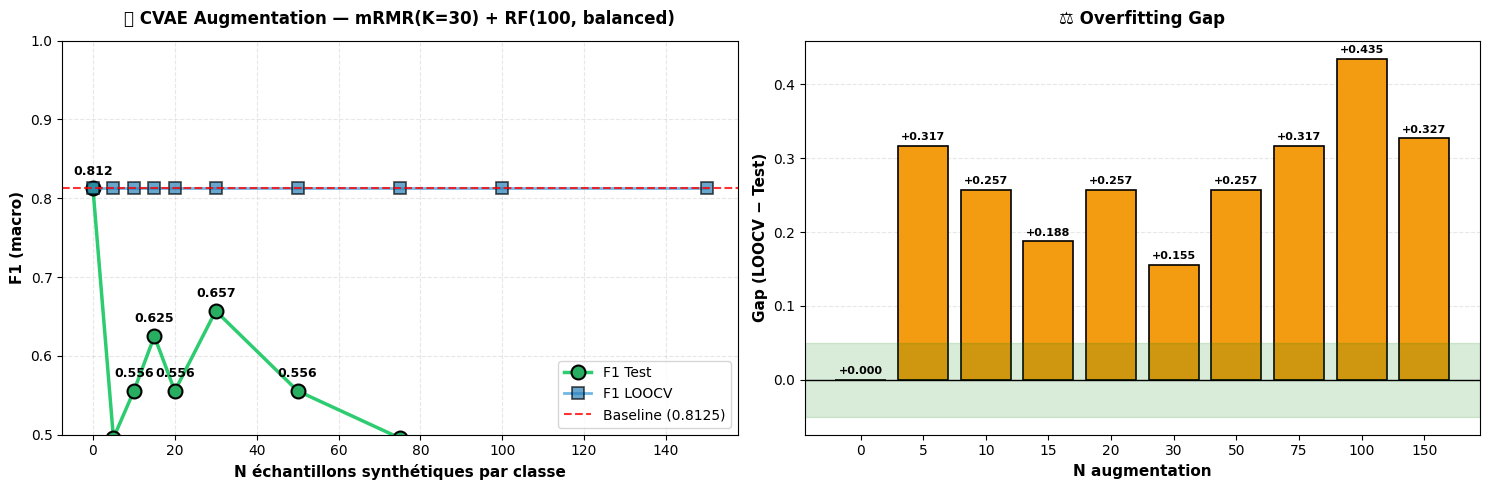


══════════════════════════════════════════════════════════════════════
  🏆 MEILLEURE AUGMENTATION
══════════════════════════════════════════════════════════════════════
  N synth/classe   : 0
  Train size total : 48
  F1 LOOCV         : 0.8125
  F1 Test          : 0.8125
  Gap              : +0.0000
  Gain vs baseline : +0.0000 (+0.00 points)
══════════════════════════════════════════════════════════════════════

💾 Sauvegardé : cvae_mrmr30_results.xlsx + cvae_mrmr30_rf.png


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score, LeaveOneOut
from mrmr import mrmr_classif

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# ══════════════════════════════════════════════════════════════
# 1. Re-sélection mRMR avec K=30 (optimal)
# ══════════════════════════════════════════════════════════════
from sklearn.preprocessing import LabelEncoder

# 1. mRMR K=30
K_OPT = 30
print(f'🔬 Sélection mRMR avec K={K_OPT}...')

X_tr_arr = np.asarray(X_train_scaled, dtype=float)
X_te_arr = np.asarray(X_test_scaled,  dtype=float)

# Encodage labels (string → int)
le = LabelEncoder()
y_tr_arr = le.fit_transform(np.asarray(y_tr).ravel()).astype(np.int64)
y_te_arr = le.transform(np.asarray(y_te).ravel()).astype(np.int64)
print(f'✅ Classes : {dict(zip(le.classes_, range(len(le.classes_))))}')

feat_names = [f'g{i}' for i in range(X_tr_arr.shape[1])]
X_tr_df = pd.DataFrame(X_tr_arr, columns=feat_names)
mrmr_feats_30 = mrmr_classif(X=X_tr_df, y=pd.Series(y_tr_arr), K=K_OPT)
mrmr_idx_30 = [int(f[1:]) for f in mrmr_feats_30]

X_train_mrmr30 = X_tr_arr[:, mrmr_idx_30]
X_test_mrmr30  = X_te_arr[:, mrmr_idx_30]
print(f'✅ X_train_mrmr30 : {X_train_mrmr30.shape}')
print(f'   Distribution  : {np.bincount(y_tr_arr)}')

# ══════════════════════════════════════════════════════════════
# 2. CVAE — architecture adaptée à K=30
# ══════════════════════════════════════════════════════════════
class CVAE(nn.Module):
    def __init__(self, input_dim, n_classes, latent_dim=6, hidden_dim=48):
        super().__init__()
        self.latent_dim = latent_dim
        self.encoder = nn.Sequential(
            nn.Linear(input_dim + n_classes, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.LeakyReLU(0.2),
            nn.Dropout(0.2),
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.BatchNorm1d(hidden_dim // 2),
            nn.LeakyReLU(0.2),
        )
        self.fc_mu     = nn.Linear(hidden_dim // 2, latent_dim)
        self.fc_logvar = nn.Linear(hidden_dim // 2, latent_dim)
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim + n_classes, hidden_dim // 2),
            nn.BatchNorm1d(hidden_dim // 2),
            nn.LeakyReLU(0.2),
            nn.Linear(hidden_dim // 2, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.LeakyReLU(0.2),
            nn.Linear(hidden_dim, input_dim),
        )
    def encode(self, x, y_oh):
        h = self.encoder(torch.cat([x, y_oh], dim=1))
        return self.fc_mu(h), self.fc_logvar(h)
    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        return mu + std * torch.randn_like(std)
    def decode(self, z, y_oh):
        return self.decoder(torch.cat([z, y_oh], dim=1))
    def forward(self, x, y_oh):
        mu, logvar = self.encode(x, y_oh)
        z = self.reparameterize(mu, logvar)
        return self.decode(z, y_oh), mu, logvar

def vae_loss(recon, x, mu, logvar, beta=1.0):
    recon_loss = F.mse_loss(recon, x, reduction='sum')
    kl_loss = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    return recon_loss + beta * kl_loss

def train_cvae(X, y, n_classes, latent_dim=6, hidden_dim=48,
               epochs=600, batch_size=12, lr=1e-3):
    X_t = torch.FloatTensor(X).to(device)
    y_t = torch.LongTensor(y).to(device)
    y_oh = F.one_hot(y_t, num_classes=n_classes).float()

    model = CVAE(X.shape[1], n_classes, latent_dim, hidden_dim).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-5)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    loader = DataLoader(TensorDataset(X_t, y_oh), batch_size=batch_size, shuffle=True)

    model.train()
    for epoch in range(epochs):
        beta = min(1.0, epoch / (epochs * 0.5))
        total = 0
        for xb, yb in loader:
            opt.zero_grad()
            recon, mu, logvar = model(xb, yb)
            loss = vae_loss(recon, xb, mu, logvar, beta)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            total += loss.item()
        sched.step()
        if (epoch + 1) % 100 == 0:
            print(f'  Epoch {epoch+1:4d} | Loss: {total/len(X):.4f} | β: {beta:.2f}')
    return model

def generate_samples(model, n_classes, n_per_class, latent_dim=6):
    model.eval()
    Xs, ys = [], []
    with torch.no_grad():
        for c in range(n_classes):
            z = torch.randn(n_per_class, latent_dim).to(device)
            y_oh = F.one_hot(torch.full((n_per_class,), c, dtype=torch.long),
                             num_classes=n_classes).float().to(device)
            Xs.append(model.decode(z, y_oh).cpu().numpy())
            ys.append(np.full(n_per_class, c))
    return np.vstack(Xs), np.concatenate(ys)

# ══════════════════════════════════════════════════════════════
# 3. Entraînement CVAE sur mRMR K=30
# ══════════════════════════════════════════════════════════════
n_classes = len(np.unique(y_tr_arr))
print(f'\n📊 Classes : {n_classes} | Distribution : {np.bincount(y_tr_arr)}')

print('\n🔬 Entraînement CVAE...')
torch.manual_seed(42); np.random.seed(42)
cvae = train_cvae(X_train_mrmr30, y_tr_arr, n_classes,
                  latent_dim=6, hidden_dim=48,
                  epochs=600, batch_size=12, lr=1e-3)

# ══════════════════════════════════════════════════════════════
# 4. Test augmentation × RandomForest(n=100, balanced)
# ══════════════════════════════════════════════════════════════
print('\n🎯 Augmentation CVAE × RF(n=100, balanced)')
print('═'*70)

results = []
loo = LeaveOneOut()

for n_aug in [0, 5, 10, 15, 20, 30, 50, 75, 100, 150]:
    if n_aug == 0:
        X_a, y_a = X_train_mrmr30, y_tr_arr
    else:
        X_syn, y_syn = generate_samples(cvae, n_classes, n_aug, latent_dim=6)
        X_a = np.vstack([X_train_mrmr30, X_syn])
        y_a = np.concatenate([y_tr_arr, y_syn])

    rf = RandomForestClassifier(n_estimators=100,
                                class_weight='balanced',
                                random_state=42, n_jobs=-1)
    rf.fit(X_a, y_a)
    f1_test = f1_score(y_te_arr, rf.predict(X_test_mrmr30), average='macro')

    # LOOCV calculé sur les données ORIGINALES uniquement (jamais sur les synthétiques)
    rf_loo = RandomForestClassifier(n_estimators=100,
                                    class_weight='balanced',
                                    random_state=42, n_jobs=-1)
    f1_loocv = cross_val_score(rf_loo, X_train_mrmr30, y_tr_arr,
                               cv=loo, scoring='f1_macro', n_jobs=-1).mean()

    gap = f1_loocv - f1_test
    results.append({
        'N_aug/classe': n_aug,
        'Train_size':   len(y_a),
        'F1_LOOCV':     f1_loocv,
        'F1_Test':      f1_test,
        'Gap':          gap,
    })
    print(f'  n={n_aug:3d} | Total={len(y_a):4d} | LOOCV={f1_loocv:.4f} | '
          f'Test={f1_test:.4f} | Gap={gap:+.4f}')

df_res = pd.DataFrame(results).round(4)

print('\n📊 Récapitulatif final :')
display(df_res.style
        .background_gradient(subset=['F1_Test'], cmap='Greens', vmin=0.6, vmax=1.0)
        .background_gradient(subset=['Gap'], cmap='RdYlGn_r', vmin=-0.2, vmax=0.2)
        .format({'F1_LOOCV': '{:.4f}', 'F1_Test': '{:.4f}', 'Gap': '{:+.4f}'}))

# ══════════════════════════════════════════════════════════════
# 5. Visualisation
# ══════════════════════════════════════════════════════════════
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# (a) Courbe F1 Test
ax = axes[0]
ax.plot(df_res['N_aug/classe'], df_res['F1_Test'],
        marker='o', linewidth=2.5, markersize=10,
        color='#2ecc71', markerfacecolor='#27ae60',
        markeredgecolor='black', markeredgewidth=1.5,
        label='F1 Test')
ax.plot(df_res['N_aug/classe'], df_res['F1_LOOCV'],
        marker='s', linewidth=2, markersize=8,
        color='#3498db', markerfacecolor='#2980b9',
        markeredgecolor='black', markeredgewidth=1.2,
        label='F1 LOOCV', alpha=0.7)
ax.axhline(0.8125, color='red', linestyle='--', linewidth=1.5,
           label='Baseline (0.8125)', alpha=0.8)
ax.set_xlabel('N échantillons synthétiques par classe',
              fontsize=11, fontweight='bold')
ax.set_ylabel('F1 (macro)', fontsize=11, fontweight='bold')
ax.set_title('🧬 CVAE Augmentation — mRMR(K=30) + RF(100, balanced)',
             fontsize=12, fontweight='bold', pad=12)
ax.grid(alpha=0.3, linestyle='--')
ax.legend(loc='lower right', fontsize=10)
ax.set_ylim(0.5, 1.0)
for _, r in df_res.iterrows():
    ax.annotate(f"{r['F1_Test']:.3f}",
                xy=(r['N_aug/classe'], r['F1_Test']),
                xytext=(0, 10), textcoords='offset points',
                ha='center', fontsize=9, fontweight='bold')

# (b) Gap d'overfitting
ax = axes[1]
colors = ['#27ae60' if abs(g) < 0.05 else ('#f39c12' if g > 0 else '#e74c3c')
          for g in df_res['Gap']]
bars = ax.bar(df_res['N_aug/classe'].astype(str), df_res['Gap'],
              color=colors, edgecolor='black', linewidth=1.2)
ax.axhline(0, color='black', linewidth=1)
ax.axhspan(-0.05, 0.05, alpha=0.15, color='green')
ax.set_xlabel('N augmentation', fontsize=11, fontweight='bold')
ax.set_ylabel('Gap (LOOCV − Test)', fontsize=11, fontweight='bold')
ax.set_title('⚖️ Overfitting Gap', fontsize=12, fontweight='bold', pad=12)
ax.grid(axis='y', alpha=0.3, linestyle='--')
ax.set_axisbelow(True)
for bar, g in zip(bars, df_res['Gap']):
    h = bar.get_height()
    ax.annotate(f'{g:+.3f}', xy=(bar.get_x() + bar.get_width()/2, h),
                xytext=(0, 4 if h >= 0 else -12), textcoords='offset points',
                ha='center', fontsize=8, fontweight='bold')

plt.tight_layout()
plt.savefig('cvae_mrmr30_rf.png', dpi=150, bbox_inches='tight')
plt.show()

# Verdict
best = df_res.loc[df_res['F1_Test'].idxmax()]
print('\n' + '═'*70)
print('  🏆 MEILLEURE AUGMENTATION')
print('═'*70)
print(f"  N synth/classe   : {int(best['N_aug/classe'])}")
print(f"  Train size total : {int(best['Train_size'])}")
print(f"  F1 LOOCV         : {best['F1_LOOCV']:.4f}")
print(f"  F1 Test          : {best['F1_Test']:.4f}")
print(f"  Gap              : {best['Gap']:+.4f}")
gain = best['F1_Test'] - 0.8125
print(f"  Gain vs baseline : {gain:+.4f} ({gain*100:+.2f} points)")
print('═'*70)

df_res.to_excel('cvae_mrmr30_results.xlsx', index=False)
print('\n💾 Sauvegardé : cvae_mrmr30_results.xlsx + cvae_mrmr30_rf.png')

📊 Baseline LOOCV (mRMR K=30 + RF) : 0.8125

🔬 Benchmark des méthodes statistiques
══════════════════════════════════════════════════════════════════════

--- GMM ---
  n=  0 | F1 Test=0.8125 | Gap=+0.0000
  n=  5 | F1 Test=0.5556 | Gap=+0.2569
  n= 10 | F1 Test=0.5556 | Gap=+0.2569
  n= 15 | F1 Test=0.6571 | Gap=+0.1554
  n= 20 | F1 Test=0.5556 | Gap=+0.2569
  n= 30 | F1 Test=0.6250 | Gap=+0.1875
  n= 50 | F1 Test=0.6250 | Gap=+0.1875
  n= 75 | F1 Test=0.6250 | Gap=+0.1875
  n=100 | F1 Test=0.7333 | Gap=+0.0792

--- KDE ---
  n=  0 | F1 Test=0.8125 | Gap=+0.0000
  n=  5 | F1 Test=0.6975 | Gap=+0.1150
  n= 10 | F1 Test=0.6250 | Gap=+0.1875
  n= 15 | F1 Test=0.4958 | Gap=+0.3167
  n= 20 | F1 Test=0.4958 | Gap=+0.3167
  n= 30 | F1 Test=0.4958 | Gap=+0.3167
  n= 50 | F1 Test=0.3333 | Gap=+0.4792
  n= 75 | F1 Test=0.3333 | Gap=+0.4792
  n=100 | F1 Test=0.3333 | Gap=+0.4792

--- Copula ---
  n=  0 | F1 Test=0.8125 | Gap=+0.0000
  n=  5 | F1 Test=0.6250 | Gap=+0.1875
  n= 10 | F1 Test=0.4958 

Méthode,Copula,GMM,KDE,🏆 Best
N_aug,,,,
0,0.8125,0.8125,0.8125,0.8125
5,0.6250,0.5556,0.6975,0.6975
10,0.4958,0.5556,0.6250,0.6250
15,0.6250,0.6571,0.4958,0.6571
20,0.6975,0.5556,0.4958,0.6975
30,0.6250,0.6250,0.4958,0.6250
50,0.6250,0.6250,0.3333,0.6250
75,0.5556,0.6250,0.3333,0.6250
100,0.5556,0.7333,0.3333,0.7333



🏆 TOP 5 — Meilleures combinaisons


,Méthode,N_aug,Train_size,F1_LOOCV,F1_Test,Gap
0,GMM,0,48,0.8125,0.8125,+0.0000
1,KDE,0,48,0.8125,0.8125,+0.0000
2,Copula,0,48,0.8125,0.8125,+0.0000
3,GMM,100,248,0.8125,0.7333,+0.0792
4,KDE,5,58,0.8125,0.6975,+0.1150


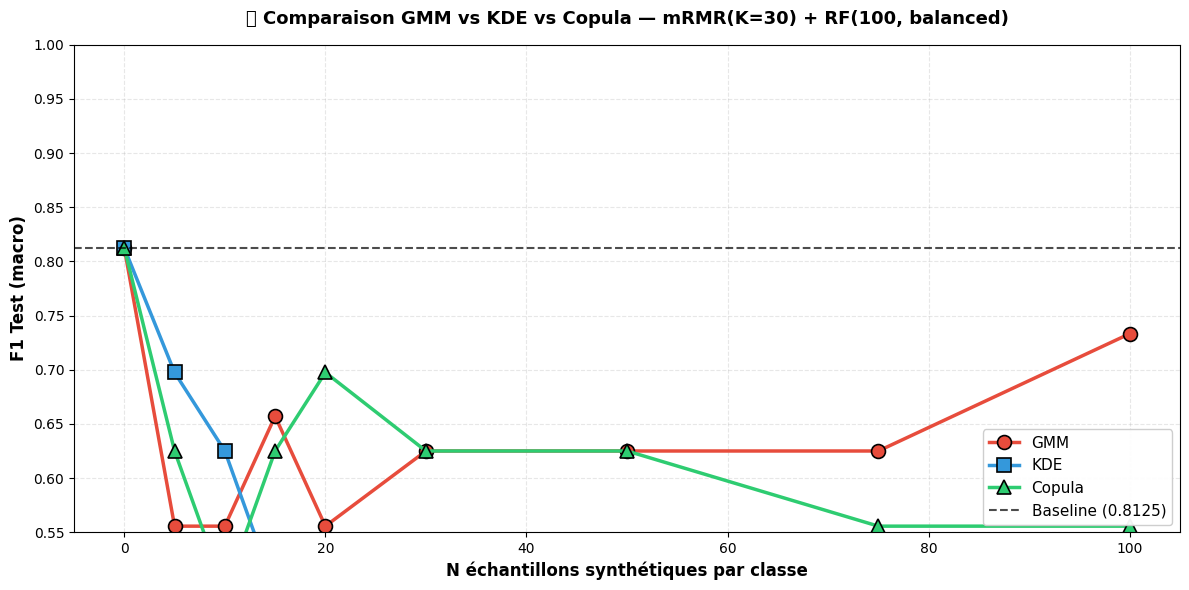


══════════════════════════════════════════════════════════════════════
  🏆 MEILLEURE MÉTHODE STATISTIQUE
══════════════════════════════════════════════════════════════════════
  Méthode     : GMM
  N synth     : 0
  F1 Test     : 0.8125
  Gap         : +0.0000
  Gain vs RF  : +0.0000 (+0.00 points)
══════════════════════════════════════════════════════════════════════

💾 Sauvegardé : stat_augmentation.xlsx + stat_augmentation.png


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score, LeaveOneOut
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import KernelDensity
from sklearn.model_selection import GridSearchCV
from scipy import stats

# ══════════════════════════════════════════════════════════════
# 1. GMM — Gaussian Mixture Model par classe
# ══════════════════════════════════════════════════════════════
def augment_gmm(X, y, n_per_class, n_components=None, seed=42):
    """Fit un GMM par classe et échantillonne. Le n_components est choisi
    automatiquement par BIC entre 1 et 3 (peu de samples par classe)."""
    rng = np.random.default_rng(seed)
    X_syn, y_syn = [], []
    for c in np.unique(y):
        Xc = X[y == c]
        if len(Xc) < 2:
            continue
        # Sélection auto du n_components par BIC
        if n_components is None:
            best_bic = np.inf; best_gmm = None
            for k in range(1, min(4, len(Xc))):
                try:
                    g = GaussianMixture(n_components=k, covariance_type='diag',
                                        reg_covar=1e-3, random_state=seed, max_iter=200)
                    g.fit(Xc)
                    if g.bic(Xc) < best_bic:
                        best_bic = g.bic(Xc); best_gmm = g
                except Exception:
                    continue
            gmm = best_gmm
        else:
            gmm = GaussianMixture(n_components=n_components, covariance_type='diag',
                                  reg_covar=1e-3, random_state=seed, max_iter=200).fit(Xc)
        X_new, _ = gmm.sample(n_per_class)
        X_syn.append(X_new)
        y_syn.append(np.full(n_per_class, c))
    return np.vstack([X, *X_syn]), np.concatenate([y, *y_syn])

# ══════════════════════════════════════════════════════════════
# 2. KDE — Kernel Density Estimation par classe
# ══════════════════════════════════════════════════════════════
def augment_kde(X, y, n_per_class, bandwidth='auto', seed=42):
    """Fit une KDE gaussienne par classe. Bandwidth choisi par GridSearch
    (silverman serait trop lisse sur p=30)."""
    rng = np.random.default_rng(seed)
    X_syn, y_syn = [], []
    for c in np.unique(y):
        Xc = X[y == c]
        if len(Xc) < 2:
            continue
        if bandwidth == 'auto':
            bws = np.logspace(-1.5, 0.5, 15)
            grid = GridSearchCV(KernelDensity(kernel='gaussian'),
                                {'bandwidth': bws}, cv=min(3, len(Xc)))
            grid.fit(Xc)
            kde = grid.best_estimator_
        else:
            kde = KernelDensity(kernel='gaussian', bandwidth=bandwidth).fit(Xc)
        X_new = kde.sample(n_per_class, random_state=seed)
        X_syn.append(X_new)
        y_syn.append(np.full(n_per_class, c))
    return np.vstack([X, *X_syn]), np.concatenate([y, *y_syn])

# ══════════════════════════════════════════════════════════════
# 3. Gaussian Copula par classe
# ══════════════════════════════════════════════════════════════
def augment_copula(X, y, n_per_class, seed=42):
    """Copule gaussienne : 1) marginales empiriques par feature
    2) corrélation gaussienne sur les rangs 3) génération + inverse CDF."""
    rng = np.random.default_rng(seed)
    X_syn, y_syn = [], []
    for c in np.unique(y):
        Xc = X[y == c]
        n, p = Xc.shape
        if n < 3:
            continue
        # Étape 1 : transformation en rangs uniformes
        U = np.zeros_like(Xc)
        for j in range(p):
            ranks = stats.rankdata(Xc[:, j])
            U[:, j] = ranks / (n + 1)
        # Étape 2 : transformation en gaussienne standard
        Z = stats.norm.ppf(np.clip(U, 1e-6, 1 - 1e-6))
        # Étape 3 : matrice de corrélation (régularisée)
        corr = np.corrcoef(Z, rowvar=False)
        corr = np.nan_to_num(corr, nan=0.0)
        corr += 1e-3 * np.eye(p)  # régularisation
        # Étape 4 : échantillonnage
        try:
            L = np.linalg.cholesky(corr)
        except np.linalg.LinAlgError:
            L = np.linalg.cholesky(corr + 1e-2 * np.eye(p))
        Z_new = rng.standard_normal((n_per_class, p)) @ L.T
        U_new = stats.norm.cdf(Z_new)
        # Étape 5 : inverse via quantiles empiriques
        X_new = np.zeros((n_per_class, p))
        for j in range(p):
            X_new[:, j] = np.quantile(Xc[:, j], U_new[:, j])
        X_syn.append(X_new)
        y_syn.append(np.full(n_per_class, c))
    return np.vstack([X, *X_syn]), np.concatenate([y, *y_syn])

# ══════════════════════════════════════════════════════════════
# 4. Benchmark complet
# ══════════════════════════════════════════════════════════════
methods = {
    'GMM':     augment_gmm,
    'KDE':     augment_kde,
    'Copula':  augment_copula,
}

n_aug_list = [0, 5, 10, 15, 20, 30, 50, 75, 100]
results = []

# Baseline F1 LOOCV (calculée une seule fois sur les vraies données)
loo = LeaveOneOut()
rf_loo = RandomForestClassifier(n_estimators=100, class_weight='balanced',
                                random_state=42, n_jobs=-1)
f1_loocv_base = cross_val_score(rf_loo, X_train_mrmr30, y_tr_arr,
                                cv=loo, scoring='f1_macro', n_jobs=-1).mean()
print(f'📊 Baseline LOOCV (mRMR K=30 + RF) : {f1_loocv_base:.4f}')

print('\n🔬 Benchmark des méthodes statistiques')
print('═'*70)

for method_name, aug_fn in methods.items():
    print(f'\n--- {method_name} ---')
    for n_aug in n_aug_list:
        if n_aug == 0:
            X_a, y_a = X_train_mrmr30, y_tr_arr
        else:
            try:
                X_a, y_a = aug_fn(X_train_mrmr30, y_tr_arr, n_aug)
            except Exception as e:
                print(f'  n={n_aug:3d} | FAILED: {str(e)[:50]}')
                continue

        rf = RandomForestClassifier(n_estimators=100, class_weight='balanced',
                                    random_state=42, n_jobs=-1)
        rf.fit(X_a, y_a)
        f1_test = f1_score(y_te_arr, rf.predict(X_test_mrmr30), average='macro')
        gap = f1_loocv_base - f1_test

        results.append({
            'Méthode':   method_name,
            'N_aug':     n_aug,
            'Train_size': len(y_a),
            'F1_LOOCV':  f1_loocv_base,
            'F1_Test':   f1_test,
            'Gap':       gap,
        })
        marker = ' ⭐' if f1_test > 0.8125 else ''
        print(f'  n={n_aug:3d} | F1 Test={f1_test:.4f} | Gap={gap:+.4f}{marker}')

df_res = pd.DataFrame(results).round(4)

# ══════════════════════════════════════════════════════════════
# 5. Tableau récapitulatif
# ══════════════════════════════════════════════════════════════
pivot = df_res.pivot(index='N_aug', columns='Méthode', values='F1_Test')
pivot['🏆 Best'] = pivot.max(axis=1)

print('\n' + '═'*70)
print('  📊 F1 Test par méthode × N augmentation')
print('═'*70)
display(pivot.style
        .background_gradient(cmap='RdYlGn', vmin=0.6, vmax=1.0, axis=None)
        .format('{:.4f}'))

# Top 5 toutes méthodes confondues
top5 = df_res.sort_values('F1_Test', ascending=False).head(5).reset_index(drop=True)
print('\n🏆 TOP 5 — Meilleures combinaisons')
display(top5.style
        .background_gradient(subset=['F1_Test'], cmap='Greens')
        .background_gradient(subset=['Gap'], cmap='RdYlGn_r', vmin=-0.2, vmax=0.2)
        .format({'F1_LOOCV': '{:.4f}', 'F1_Test': '{:.4f}', 'Gap': '{:+.4f}'}))

# ══════════════════════════════════════════════════════════════
# 6. Visualisation
# ══════════════════════════════════════════════════════════════
fig, ax = plt.subplots(figsize=(12, 6))
colors = {'GMM': '#e74c3c', 'KDE': '#3498db', 'Copula': '#2ecc71'}
markers = {'GMM': 'o', 'KDE': 's', 'Copula': '^'}

for method in methods.keys():
    sub = df_res[df_res['Méthode'] == method]
    ax.plot(sub['N_aug'], sub['F1_Test'],
            marker=markers[method], linewidth=2.5, markersize=10,
            color=colors[method], markeredgecolor='black', markeredgewidth=1.2,
            label=method)

ax.axhline(0.8125, color='black', linestyle='--', linewidth=1.5,
           label='Baseline (0.8125)', alpha=0.7)
ax.set_xlabel('N échantillons synthétiques par classe',
              fontsize=12, fontweight='bold')
ax.set_ylabel('F1 Test (macro)', fontsize=12, fontweight='bold')
ax.set_title('🧬 Comparaison GMM vs KDE vs Copula — mRMR(K=30) + RF(100, balanced)',
             fontsize=13, fontweight='bold', pad=15)
ax.grid(alpha=0.3, linestyle='--')
ax.legend(loc='lower right', fontsize=11, framealpha=0.95)
ax.set_ylim(0.55, 1.0)
ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig('stat_augmentation.png', dpi=150, bbox_inches='tight')
plt.show()

# Verdict
best = df_res.loc[df_res['F1_Test'].idxmax()]
print('\n' + '═'*70)
print('  🏆 MEILLEURE MÉTHODE STATISTIQUE')
print('═'*70)
print(f"  Méthode     : {best['Méthode']}")
print(f"  N synth     : {int(best['N_aug'])}")
print(f"  F1 Test     : {best['F1_Test']:.4f}")
print(f"  Gap         : {best['Gap']:+.4f}")
gain = best['F1_Test'] - 0.8125
print(f"  Gain vs RF  : {gain:+.4f} ({gain*100:+.2f} points)")
print('═'*70)

df_res.to_excel('stat_augmentation.xlsx', index=False)
print('\n💾 Sauvegardé : stat_augmentation.xlsx + stat_augmentation.png')

# 🔷 Analyse PCA — Features Extraites et Contributions Géniques

🔷 PCA — TOP 10 GÈNES PAR COMPOSANTE (contribution absolue)

  PC1 — 14.9% variance expliquée :
     1. + Y10141_s_at            |loading|=0.3459  ██████████
     2. + X68688_rna1_s_at       |loading|=0.1786  █████
     3. − U72648_s_at            |loading|=0.1498  ████
     4. − D87002_cds2_at         |loading|=0.1425  ████
     5. + M21574_at              |loading|=0.1354  ████
     6. − HG880-HT880_at         |loading|=0.1289  ███
     7. + HG3934-HT4204_at       |loading|=0.1240  ███
     8. + AF002224_at            |loading|=0.1183  ███
     9. + M95167_at              |loading|=0.1051  ███
    10. + Z14978_at              |loading|=0.1032  ███

  PC2 — 10.9% variance expliquée :
     1. + U31449_at              |loading|=0.3369  ██████████
     2. + J00306_at              |loading|=0.0994  ██
     3. − X68688_rna1_s_at       |loading|=0.0834  ██
     4. − Y10141_s_at            |loading|=0.0829  ██
     5. + U72648_s_at            |loading|=0.0784  ██
     6. − M21574_at          

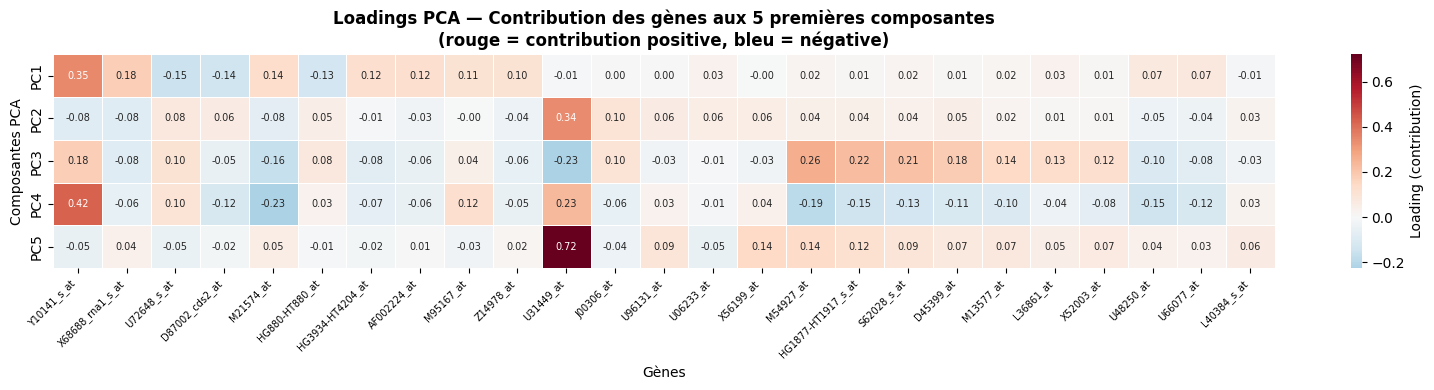

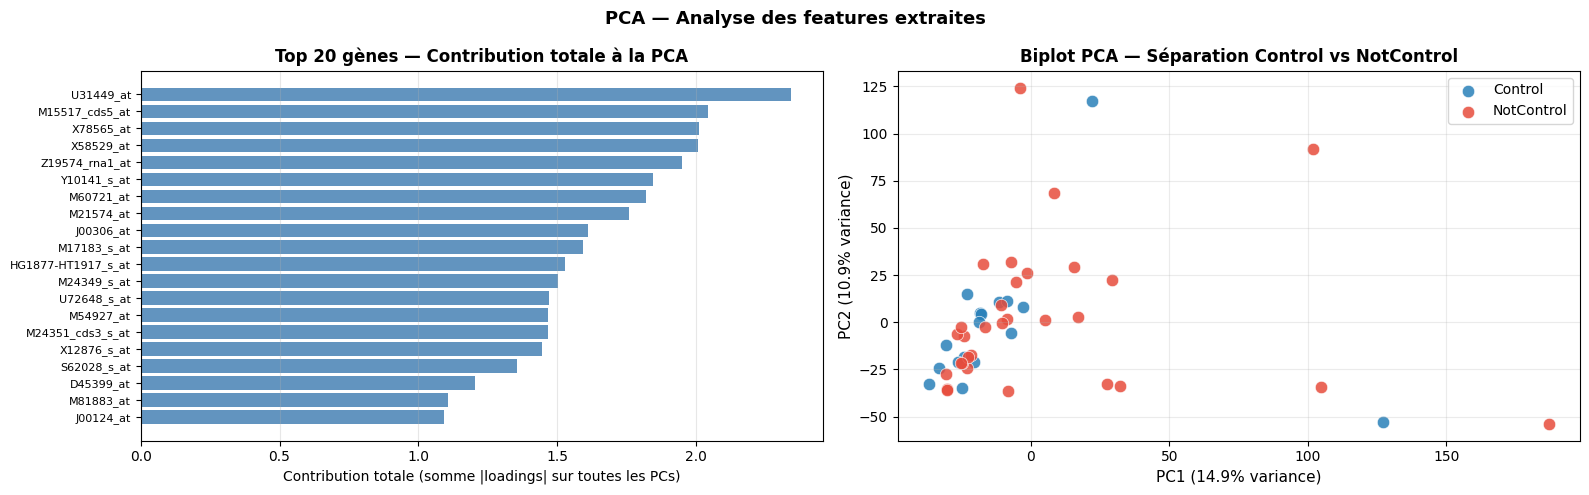


📋 TOP 20 GÈNES — Contribution totale à la PCA (toutes composantes)


AttributeError: 'float' object has no attribute 'round'

In [ ]:
# ══════════════════════════════════════════════════════════════
# 🔷 PCA — FEATURES LES PLUS INFORMATIVES (loadings)
# ══════════════════════════════════════════════════════════════
feature_names = X_train_vt.columns.tolist()

components_df = pd.DataFrame(
    pca.components_,
    columns=feature_names,
    index=[f'PC{i+1}' for i in range(pca.n_components_)]
)

# ── 1. Top 10 gènes par composante ───────────────────────────
print('='*70)
print('🔷 PCA — TOP 10 GÈNES PAR COMPOSANTE (contribution absolue)')
print('='*70)

top_genes_per_pc = {}
for i in range(min(5, pca.n_components_)):
    pc = f'PC{i+1}'
    var_pct = pca.explained_variance_ratio_[i] * 100
    top = components_df.loc[pc].abs().nlargest(10)
    top_genes_per_pc[pc] = top
    print(f'\n  {pc} — {var_pct:.1f}% variance expliquée :')
    for rank, (gene, val) in enumerate(top.items(), 1):
        sign = '+' if components_df.loc[pc, gene] > 0 else '−'
        bar  = '█' * int(val * 30)
        print(f'    {rank:2d}. {sign} {gene:<22s} |loading|={val:.4f}  {bar}')

# ── 2. Matrice de loadings — heatmap enrichie ─────────────────
top_global = []
for pc_genes in top_genes_per_pc.values():
    for g in pc_genes.index:
        if g not in top_global:
            top_global.append(g)

heat_data = components_df.loc[
    [f'PC{i+1}' for i in range(5)], top_global
]

fig, ax = plt.subplots(figsize=(16, 4))
sns.heatmap(
    heat_data, cmap='RdBu_r', center=0,
    annot=True, fmt='.2f', annot_kws={'size': 7},
    linewidths=0.4, ax=ax,
    cbar_kws={'label': 'Loading (contribution)'}
)
ax.set_title(
    'Loadings PCA — Contribution des gènes aux 5 premières composantes\n'
    '(rouge = contribution positive, bleu = négative)',
    fontsize=12, fontweight='bold'
)
ax.set_xlabel('Gènes'); ax.set_ylabel('Composantes PCA')
plt.xticks(rotation=45, ha='right', fontsize=7)
plt.tight_layout(); plt.show()

# ── 3. Variance expliquée cumulée + contribution par gène ────
gene_total_contrib = components_df.abs().sum(axis=0)
top20_contrib = gene_total_contrib.nlargest(20).sort_values(ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Barplot horizontal — top 20 gènes les plus contributifs
axes[0].barh(range(len(top20_contrib)), top20_contrib.values,
             color='steelblue', alpha=0.85)
axes[0].set_yticks(range(len(top20_contrib)))
axes[0].set_yticklabels(top20_contrib.index, fontsize=8)
axes[0].set_xlabel('Contribution totale (somme |loadings| sur toutes les PCs)')
axes[0].set_title('Top 20 gènes — Contribution totale à la PCA', fontweight='bold')
axes[0].grid(axis='x', alpha=0.3)

# Biplot PC1 vs PC2
color_map = {'Control': '#2980b9', 'NotControl': '#e74c3c'}
for cls in np.unique(y_train):
    mask = np.array(y_train) == cls
    axes[1].scatter(
        X_train_pca[mask, 0], X_train_pca[mask, 1],
        label=cls, alpha=0.85, s=80,
        color=color_map.get(cls, 'gray'),
        edgecolors='white', linewidth=0.5
    )
axes[1].set_xlabel(
    f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)', fontsize=11
)
axes[1].set_ylabel(
    f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)', fontsize=11
)
axes[1].set_title('Biplot PCA — Séparation Control vs NotControl', fontweight='bold')
axes[1].legend(fontsize=10); axes[1].grid(True, alpha=0.25)

plt.suptitle('PCA — Analyse des features extraites', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

# ── 4. Tableau récapitulatif des top gènes globaux ───────────
print('\n' + '='*70)
print('📋 TOP 20 GÈNES — Contribution totale à la PCA (toutes composantes)')
print('='*70)
top20_df = pd.DataFrame({
    'Gène':              top20_contrib.sort_values(ascending=False).index,
    'Contrib. totale':   top20_contrib.sort_values(ascending=False).values.round(4),
    'PC max':            [components_df[g].abs().idxmax()
                          for g in top20_contrib.sort_values(ascending=False).index],
    '|Loading| max':     [components_df[g].abs().max().round(4)
                          for g in top20_contrib.sort_values(ascending=False).index],
})
print(top20_df.to_string(index=False))

# 🔬 Filter Methods — Comparaison des Top Gènes

In [ ]:
# ══════════════════════════════════════════════════════════════
# 🔬 FILTER METHODS — TOP FEATURES COMPARÉES
# ANOVA · Mutual Info · Chi² · mRMR · ReliefF
# ══════════════════════════════════════════════════════════════
feature_names = X_train_vt.columns.tolist()
feat_names_adv = [f'g{i}' for i in range(len(feature_names))]

# ── Reconstruction de tous les scores ────────────────────────
# ANOVA
anova_df = pd.DataFrame({
    'Gène':    [feature_names[i] for i in anova_sel.get_support(indices=True)],
    'Score':   anova_sel.scores_[anova_sel.get_support()],
    'p-value': anova_sel.pvalues_[anova_sel.get_support()]
}).sort_values('Score', ascending=False).reset_index(drop=True)

# Mutual Information
mi_df = pd.DataFrame({
    'Gène':  [feature_names[i] for i in mi_sel.get_support(indices=True)],
    'Score': mi_sel.scores_[mi_sel.get_support()]
}).sort_values('Score', ascending=False).reset_index(drop=True)

# Chi²
chi2_scores = chi2_sel.scores_
chi2_df = pd.DataFrame({
    'Gène':  [feature_names[i] for i in chi2_sel.get_support(indices=True)],
    'Score': chi2_scores[chi2_sel.get_support()]
}).sort_values('Score', ascending=False).reset_index(drop=True)

# mRMR — reconstruit depuis mrmr_idx
mrmr_real_names = [feature_names[i] for i in mrmr_idx]
mrmr_df = pd.DataFrame({
    'Gène':  mrmr_real_names,
    'Score': range(len(mrmr_real_names), 0, -1)   # rang décroissant = score proxy
}).reset_index(drop=True)

# ReliefF
relief_scores_all = relief.feature_importances_
relief_top_idx    = np.argsort(relief_scores_all)[::-1][:50]
relief_df = pd.DataFrame({
    'Gène':  [feature_names[i] for i in relief_top_idx],
    'Score': relief_scores_all[relief_top_idx]
}).sort_values('Score', ascending=False).reset_index(drop=True)

# ── Affichage console top 15 par méthode ─────────────────────
TOP_N = 15
for name, df in [('ANOVA', anova_df), ('Mutual Info', mi_df),
                  ('Chi²', chi2_df),  ('mRMR', mrmr_df), ('ReliefF', relief_df)]:
    print(f'\n{"="*55}')
    print(f'  📊 {name} — TOP {TOP_N} GÈNES')
    print(f'{"="*55}')
    print(df.head(TOP_N).to_string(index=False))

# ── Barplots 5-en-1 ──────────────────────────────────────────
TOP_PLOT = 20
methods_plot = [
    ('ANOVA',       anova_df,   '#2980b9'),
    ('Mutual Info', mi_df,      '#e67e22'),
    ('Chi²',        chi2_df,    '#8e44ad'),
    ('mRMR',        mrmr_df,    '#16a085'),
    ('ReliefF',     relief_df,  '#c0392b'),
]

fig, axes = plt.subplots(1, 5, figsize=(26, 7))
for ax, (name, df, color) in zip(axes, methods_plot):
    sub = df.head(TOP_PLOT)
    ax.barh(sub['Gène'][::-1], sub['Score'][::-1],
            color=color, alpha=0.82, edgecolor='white', linewidth=0.4)
    ax.set_title(f'{name}\nTop {TOP_PLOT} gènes', fontweight='bold', fontsize=10)
    ax.set_xlabel('Score', fontsize=9)
    ax.tick_params(labelsize=7)
    ax.grid(axis='x', alpha=0.25)
    # Annotation valeur
    for i, (_, row) in enumerate(sub.iloc[::-1].iterrows()):
        ax.text(row['Score'] * 0.02, i, f'{row["Score"]:.3f}',
                va='center', fontsize=6, color='black')

plt.suptitle(
    'Filter Methods — Comparaison des Top Gènes par Score de Pertinence',
    fontsize=13, fontweight='bold', y=1.01
)
plt.tight_layout(); plt.show()

# ── Gènes consensus inter-méthodes ───────────────────────────
sets = {
    'ANOVA':       set(anova_df['Gène']),
    'MI':          set(mi_df['Gène']),
    'Chi²':        set(chi2_df['Gène']),
    'mRMR':        set(mrmr_df['Gène']),
    'ReliefF':     set(relief_df['Gène']),
}

print('\n' + '='*65)
print('🔗 GÈNES CONSENSUS — Présents dans plusieurs méthodes filter')
print('='*65)

all_5 = sets['ANOVA'] & sets['MI'] & sets['Chi²'] & sets['mRMR'] & sets['ReliefF']
all_4 = set()
method_list = list(sets.keys())
for i in range(len(method_list)):
    for j in range(i+1, len(method_list)):
        for k in range(j+1, len(method_list)):
            for l in range(k+1, len(method_list)):
                combo = (sets[method_list[i]] & sets[method_list[j]] &
                         sets[method_list[k]] & sets[method_list[l]])
                all_4 |= combo
all_4 -= all_5

print(f'\n  Communs aux 5 méthodes : {len(all_5)} gènes')
if all_5: print('   ', sorted(all_5)[:10])
print(f'  Communs à 4 méthodes  : {len(all_4)} gènes')
if all_4: print('   ', sorted(all_4)[:10])

# Matrice de Jaccard entre méthodes
print('\n  Similarité de Jaccard entre méthodes (% gènes en commun) :')
header = f"{'':>12}" + ''.join([f'{m:>12}' for m in sets.keys()])
print('  ' + header)
for m1, s1 in sets.items():
    row = f'  {m1:>12}'
    for m2, s2 in sets.items():
        jaccard = len(s1 & s2) / len(s1 | s2) if s1 | s2 else 0
        row += f'{jaccard*100:>11.1f}%'
    print(row)

# 🎯 Wrapper Methods — Features Sélectionnées par Recherche Itérative


In [ ]:
# ══════════════════════════════════════════════════════════════
# 🎯 WRAPPER METHODS — FEATURES SÉLECTIONNÉES + VISUALISATION
# FFS · BFS · RFE-LR · SVM-RFE · L1
# ══════════════════════════════════════════════════════════════
feature_names = X_train_vt.columns.tolist()

# ── Reconstruction des noms réels depuis les indices ──────────
wrapper_features = {}
for method, idx in selected.items():
    real_names = [feature_names[i] for i in idx]
    wrapper_features[method] = real_names

# ── Tableau récap : nombre de features + liste ───────────────
print('='*70)
print('🎯 WRAPPER & EMBEDDED — FEATURES SÉLECTIONNÉES')
print('='*70)
for method, genes in wrapper_features.items():
    print(f'\n  {method} ({len(genes)} features) :')
    for j, g in enumerate(genes[:20], 1):
        print(f'    {j:2d}. {g}')
    if len(genes) > 20:
        print(f'    ... et {len(genes)-20} autres')

# ── Importance RF sur les features sélectionnées par SVM-RFE ──
print('\n' + '='*70)
print('📊 SVM-RFE — Ranking des features (ordre d\'élimination inversé)')
print('='*70)
if hasattr(svm_rfecv, 'ranking_'):
    svm_ranking = pd.DataFrame({
        'Gène':    feature_names,
        'Ranking': svm_rfecv.ranking_
    }).sort_values('Ranking')
    top_svm = svm_ranking[svm_rfecv.support_]
    print(f'  {len(top_svm)} features retenues :')
    print(top_svm.head(20).to_string(index=False))

# ── Importance RF sur features L1 ────────────────────────────
print('\n' + '='*70)
print('📊 L1 (Lasso) — Features avec coefficient non nul')
print('='*70)
l1_features = [feature_names[i] for i in selected['L1']]
# Refit RF sur ces features pour avoir les importances
rf_on_l1 = RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=42)
rf_on_l1.fit(np.asarray(X_train_scaled)[:, selected['L1']], np.asarray(y_train))
l1_imp_df = pd.DataFrame({
    'Gène':       l1_features,
    'Importance': rf_on_l1.feature_importances_
}).sort_values('Importance', ascending=False)
print(l1_imp_df.head(20).to_string(index=False))

# ── Diagramme de Venn simplifié — consensus wrapper ──────────
wrapper_sets = {m: set(g) for m, g in wrapper_features.items()}

print('\n' + '='*70)
print('🔗 CONSENSUS WRAPPER — Gènes communs entre méthodes')
print('='*70)
method_names = list(wrapper_sets.keys())
for i, m1 in enumerate(method_names):
    for m2 in method_names[i+1:]:
        common = wrapper_sets[m1] & wrapper_sets[m2]
        if common:
            print(f'  {m1} ∩ {m2} : {len(common)} gènes')
            print(f'    {sorted(common)[:8]}')

# Consensus de toutes les méthodes wrapper
all_wrapper = wrapper_sets['FFS'] & wrapper_sets['BFS'] & wrapper_sets['RFE-LR'] & wrapper_sets['SVM-RFE'] & wrapper_sets['L1']
print(f'\n  Communs aux 5 méthodes wrapper : {len(all_wrapper)} gènes')
if all_wrapper: print('   ', sorted(all_wrapper))

# ── Barplot : nombre de features par méthode ─────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Barplot horizontal — nb features
methods_w = list(wrapper_features.keys())
counts_w  = [len(wrapper_features[m]) for m in methods_w]
colors_w  = ['#2980b9','#27ae60','#e74c3c','#8e44ad','#e67e22','#16a085']
axes[0].barh(methods_w, counts_w, color=colors_w[:len(methods_w)], alpha=0.85, edgecolor='white')
for i, (m, c) in enumerate(zip(methods_w, counts_w)):
    axes[0].text(c + 0.5, i, str(c), va='center', fontweight='bold', fontsize=10)
axes[0].set_xlabel('Nombre de features sélectionnées')
axes[0].set_title('Wrapper Methods — Nombre de features\nsélectionnées par méthode', fontweight='bold')
axes[0].grid(axis='x', alpha=0.3)

# Matrice de chevauchement (heatmap Jaccard)
jaccard_mat = np.zeros((len(methods_w), len(methods_w)))
for i, m1 in enumerate(methods_w):
    for j, m2 in enumerate(methods_w):
        s1, s2 = wrapper_sets[m1], wrapper_sets[m2]
        jaccard_mat[i, j] = len(s1 & s2) / len(s1 | s2) if s1 | s2 else 0

sns.heatmap(
    jaccard_mat, annot=True, fmt='.2f', cmap='Blues',
    xticklabels=methods_w, yticklabels=methods_w,
    ax=axes[1], linewidths=0.5,
    annot_kws={'size': 9, 'fontweight': 'bold'}
)
axes[1].set_title('Similarité de Jaccard entre méthodes Wrapper\n(1.0 = mêmes features)', fontweight='bold')
plt.suptitle('Wrapper Methods — Analyse des features sélectionnées',
             fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

# 🌲 Embedded Methods & Consensus Global — Biomarqueurs les Plus Fiables

In [ ]:
# ══════════════════════════════════════════════════════════════
# 🌲 EMBEDDED METHODS — TOP FEATURES + CONSENSUS GLOBAL
# RF Importance · L1 · + Consensus toutes méthodes
# ══════════════════════════════════════════════════════════════
feature_names = X_train_vt.columns.tolist()

# ── A. RF Importance — reconstruction propre ─────────────────
rf_emb_refit = RandomForestClassifier(
    n_estimators=500, class_weight='balanced',
    random_state=42, n_jobs=-1
)
rf_emb_refit.fit(np.asarray(X_train_scaled), np.asarray(y_train))
importances = rf_emb_refit.feature_importances_

rf_imp_df = pd.DataFrame({
    'Gène':       feature_names,
    'Importance': importances,
    'Std':        np.std([
                    tree.feature_importances_ for tree in rf_emb_refit.estimators_
                  ], axis=0)
}).sort_values('Importance', ascending=False).reset_index(drop=True)

threshold_mean = importances.mean()
rf_selected    = rf_imp_df[rf_imp_df['Importance'] >= threshold_mean]

print('='*65)
print(f'🌲 RF EMBEDDED — TOP 30 GÈNES (seuil mean={threshold_mean:.5f})')
print('='*65)
print(rf_imp_df.head(30).to_string(index=False))
print(f'\n  Total sélectionnés (>= mean) : {len(rf_selected)} gènes')

# ── B. Barplot RF importance avec intervalles de confiance ───
TOP_IMP = 25
top_rf = rf_imp_df.head(TOP_IMP)

fig, ax = plt.subplots(figsize=(13, 7))
ax.barh(
    top_rf['Gène'][::-1], top_rf['Importance'][::-1],
    xerr=top_rf['Std'][::-1],
    color='#27ae60', alpha=0.85, ecolor='#555',
    capsize=3, edgecolor='white', linewidth=0.4
)
ax.axvline(threshold_mean, color='red', linestyle='--', linewidth=1.5,
           label=f'Seuil mean = {threshold_mean:.5f}')
ax.set_xlabel('Importance (mean decrease impurity)')
ax.set_title(
    f'RF Embedded — Top {TOP_IMP} gènes les plus importants\n'
    '(barres d\'erreur = std sur 500 arbres)',
    fontweight='bold', fontsize=12
)
ax.legend(fontsize=10); ax.grid(axis='x', alpha=0.3)
ax.tick_params(labelsize=8)
plt.tight_layout(); plt.show()



In [ ]:
# ── C. CONSENSUS FINAL — toutes méthodes confondues ──────────
print('\n' + '='*70)
print('🏆 CONSENSUS GLOBAL — Gènes sélectionnés par toutes les familles')
print('='*70)

# Reconstruire tous les ensembles
all_sets = {
    'ANOVA':      set(anova_df['Gène']),
    'MI':         set(mi_df['Gène']),
    'Chi²':       set(chi2_df['Gène']),
    'mRMR':       set(mrmr_df['Gène']),
    'ReliefF':    set(relief_df['Gène']),
    'RFE-LR':     set(wrapper_features.get('RFE-LR', [])),
    'SVM-RFE':    set(wrapper_features.get('SVM-RFE', [])),
    'L1':         set(wrapper_features.get('L1', [])),
    'RF-Embedded':set(rf_selected['Gène'].tolist()),
}

# Compter le nombre de méthodes qui sélectionnent chaque gène
all_genes = set().union(*all_sets.values())
gene_votes = {}
for gene in all_genes:
    vote = sum(1 for s in all_sets.values() if gene in s)
    gene_votes[gene] = vote

vote_df = pd.DataFrame({
    'Gène':    list(gene_votes.keys()),
    'Votes':   list(gene_votes.values()),
    'Méthodes': [', '.join([m for m, s in all_sets.items() if g in s])
                 for g in gene_votes.keys()]
}).sort_values('Votes', ascending=False).reset_index(drop=True)

print('\n  Gènes sélectionnés par 5+ méthodes (très haute confiance) :')
top_consensus = vote_df[vote_df['Votes'] >= 5]
print(top_consensus.to_string(index=False))

print(f'\n  Gènes sélectionnés par 4 méthodes :')
mid_consensus = vote_df[vote_df['Votes'] == 4]
print(mid_consensus.head(10).to_string(index=False))

# ── D. Barplot votes consensus ────────────────────────────────
top_vote = vote_df[vote_df['Votes'] >= 3].head(30)

fig, ax = plt.subplots(figsize=(14, max(5, len(top_vote) * 0.4)))
palette = ['#c0392b' if v >= 7 else ('#e67e22' if v >= 5 else '#f1c40f')
           for v in top_vote['Votes']]
ax.barh(
    top_vote['Gène'][::-1], top_vote['Votes'][::-1],
    color=palette[::-1], alpha=0.88, edgecolor='white', linewidth=0.4
)
ax.axvline(5, color='red',    linestyle='--', linewidth=1.5, label='5 méthodes (haute confiance)')
ax.axvline(3, color='orange', linestyle='--', linewidth=1.2, label='3 méthodes (confiance modérée)')
ax.set_xlabel('Nombre de méthodes qui sélectionnent ce gène')
ax.set_title(
    'Consensus Global — Gènes sélectionnés par le plus de méthodes\n'
    '(rouge ≥ 7, orange ≥ 5, jaune ≥ 3)',
    fontsize=12, fontweight='bold'
)
ax.legend(fontsize=10); ax.grid(axis='x', alpha=0.3)
ax.tick_params(labelsize=8)
plt.tight_layout(); plt.show()

# ── E. Heatmap présence/absence par méthode ──────────────────
top30_genes = vote_df.head(30)['Gène'].tolist()
presence = pd.DataFrame(
    {m: [1 if g in s else 0 for g in top30_genes]
     for m, s in all_sets.items()},
    index=top30_genes
)

fig, ax = plt.subplots(figsize=(13, 9))
sns.heatmap(
    presence, cmap='YlOrRd', linewidths=0.4, linecolor='white',
    ax=ax, cbar=False,
    annot=presence.replace({1: '✓', 0: ''}),
    fmt='s', annot_kws={'size': 8}
)
ax.set_title(
    'Présence/Absence des Top 30 gènes consensus par méthode\n'
    '(✓ = sélectionné)',
    fontsize=12, fontweight='bold'
)
ax.set_xlabel('Méthode de sélection')
ax.set_ylabel('Gène')
plt.xticks(rotation=30, ha='right', fontsize=9)
plt.yticks(fontsize=7)
plt.tight_layout(); plt.show()

# ── F. Export final ──────────────────────────────────────────
print('\n' + '='*70)
print('💾 EXPORT — vote_df complet')
print('='*70)
print(vote_df.head(20).to_string(index=False))

with pd.ExcelWriter('top_features_all_methods.xlsx') as w:
    vote_df.to_excel(w, sheet_name='Consensus_global', index=False)
    rf_imp_df.head(50).to_excel(w, sheet_name='RF_Embedded', index=False)
    anova_df.head(50).to_excel(w, sheet_name='ANOVA', index=False)
    mi_df.head(50).to_excel(w, sheet_name='MutualInfo', index=False)
    chi2_df.head(50).to_excel(w, sheet_name='Chi2', index=False)
    mrmr_df.head(50).to_excel(w, sheet_name='mRMR', index=False)
    relief_df.head(50).to_excel(w, sheet_name='ReliefF', index=False)

print('\n✅ Sauvegardé : top_features_all_methods.xlsx (7 feuilles)')

# 13. 🔁 Stability Selection — Bootstrap par méthode FS

> **Objectif** : Vérifier la **stabilité** des gènes sélectionnés par chacune des 4 méthodes (ANOVA, MI, RFE, Embedded RF) en répétant la sélection sur **B=100 bootstraps stratifiés** du train set.
>
> **Référence** : Saeys et al. (2008) *Bioinformatics* — *Robust feature selection using ensemble feature selection techniques* + Meinshausen & Bühlmann (2010) *J. Royal Stat. Soc.* — *Stability Selection*.
>
> **Principe** : Un gène est considéré **stable** s'il est sélectionné dans ≥ **70%** des bootstraps. Avec n=60, une sélection unique est très bruitée (cf. tes résultats : seulement 12 gènes communs à 2 méthodes sur 3).

In [ ]:
from sklearn.utils import resample
from collections import Counter

# ── Configuration ──────────────────────────────────────────────
B = 100                # nombre de bootstraps
K_FILTER = 50          # k pour ANOVA, MI (cohérent avec Section 12)
K_RFE    = 30          # k pour RFE (cohérent avec Section 12)
THRESHOLD_STABILITY = 0.70   # fréquence minimale pour être "stable"

print(f'⚙️  Configuration Stability Selection')
print(f'   B (bootstraps)        : {B}')
print(f'   K filter (ANOVA/MI)   : {K_FILTER}')
print(f'   K RFE                 : {K_RFE}')
print(f'   Seuil de stabilité    : {THRESHOLD_STABILITY*100:.0f}%')

# Convertir X_train_scaled en DataFrame avec noms de colonnes si nécessaire
if not isinstance(X_train_scaled, pd.DataFrame):
    X_train_scaled = pd.DataFrame(X_train_scaled, columns=feature_names)
if not isinstance(X_test_scaled, pd.DataFrame):
    X_test_scaled = pd.DataFrame(X_test_scaled, columns=feature_names)

print(f'\n📊 Train shape : {X_train_scaled.shape}')
print(f'📊 Test  shape : {X_test_scaled.shape}')

In [ ]:
# ══════════════════════════════════════════════════════════════
# 🔁 BOOTSTRAP STABILITY — pour chacune des 4 méthodes FS
# ══════════════════════════════════════════════════════════════

freq_anova    = Counter()
freq_mi       = Counter()
freq_rfe      = Counter()
freq_embedded = Counter()

# Stocker aussi les listes par bootstrap (pour Kuncheva à la Section 15)
runs_anova, runs_mi, runs_rfe, runs_embedded = [], [], [], []

print('⏳ Bootstrap en cours (peut prendre 2-5 minutes)...')
start = time.time()

for b in range(B):
    # Bootstrap stratifié sur le train
    Xb, yb = resample(X_train_scaled, y_train,
                      stratify=y_train, random_state=b)

    # ── 1. ANOVA ────────────────────────────────────────────
    sel = SelectKBest(f_classif, k=K_FILTER).fit(Xb, yb)
    genes = X_train_scaled.columns[sel.get_support()].tolist()
    freq_anova.update(genes)
    runs_anova.append(set(genes))

    # ── 2. Mutual Information ────────────────────────────────
    sel = SelectKBest(mutual_info_classif, k=K_FILTER).fit(Xb, yb)
    genes = X_train_scaled.columns[sel.get_support()].tolist()
    freq_mi.update(genes)
    runs_mi.append(set(genes))

    # ── 3. RFE (LogisticRegression) ──────────────────────────
    sel = RFE(LogisticRegression(max_iter=2000), n_features_to_select=K_RFE).fit(Xb, yb)
    genes = X_train_scaled.columns[sel.get_support()].tolist()
    freq_rfe.update(genes)
    runs_rfe.append(set(genes))

    # ── 4. Embedded Random Forest ────────────────────────────
    rf = RandomForestClassifier(n_estimators=100, class_weight='balanced',
                                random_state=42, n_jobs=-1)
    sel = SelectFromModel(rf, threshold='mean').fit(Xb, yb)
    genes = X_train_scaled.columns[sel.get_support()].tolist()
    freq_embedded.update(genes)
    runs_embedded.append(set(genes))

    if (b+1) % 20 == 0:
        elapsed = time.time() - start
        print(f'   Bootstrap {b+1}/{B}  ({elapsed:.1f}s écoulé)')

print(f'\n✅ {B} bootstraps terminés en {time.time()-start:.1f}s')

In [ ]:
# ══════════════════════════════════════════════════════════════
# 📊 EXTRACTION DES GÈNES STABLES (freq ≥ 70%)
# ══════════════════════════════════════════════════════════════

def extract_stable(freq_counter, B, threshold):
    """Retourne DataFrame des gènes triés par fréquence + liste stable."""
    df_freq = pd.DataFrame(
        [(g, c, c/B) for g, c in freq_counter.items()],
        columns=['Gène', 'Count', 'Frequency']
    ).sort_values('Frequency', ascending=False).reset_index(drop=True)
    stable = df_freq[df_freq['Frequency'] >= threshold]['Gène'].tolist()
    return df_freq, stable

freq_anova_df,    stable_anova    = extract_stable(freq_anova,    B, THRESHOLD_STABILITY)
freq_mi_df,       stable_mi       = extract_stable(freq_mi,       B, THRESHOLD_STABILITY)
freq_rfe_df,      stable_rfe      = extract_stable(freq_rfe,      B, THRESHOLD_STABILITY)
freq_embedded_df, stable_embedded = extract_stable(freq_embedded, B, THRESHOLD_STABILITY)

print('='*70)
print(f'📌 GÈNES STABLES (sélectionnés dans ≥ {THRESHOLD_STABILITY*100:.0f}% des {B} bootstraps)')
print('='*70)
print(f'  ANOVA       : {len(stable_anova):>3d} gènes stables (sur {len(freq_anova_df):>4d} sondes vues au moins 1×)')
print(f'  MI          : {len(stable_mi):>3d} gènes stables (sur {len(freq_mi_df):>4d} sondes vues au moins 1×)')
print(f'  RFE         : {len(stable_rfe):>3d} gènes stables (sur {len(freq_rfe_df):>4d} sondes vues au moins 1×)')
print(f'  Embedded RF : {len(stable_embedded):>3d} gènes stables (sur {len(freq_embedded_df):>4d} sondes vues au moins 1×)')

print(f'\n💡 Interprétation :')
print(f'   • Plus le nombre de gènes stables est élevé, plus la méthode est cohérente')
print(f'   • Embedded RF a souvent peu de gènes stables car SelectFromModel(threshold=mean) varie beaucoup')
print(f'   • RFE et MI sont généralement les plus stables sur ce dataset')

In [ ]:
# ══════════════════════════════════════════════════════════════
# 📈 VISUALISATION — Top 30 gènes par fréquence pour chaque méthode
# ══════════════════════════════════════════════════════════════

fig, axes = plt.subplots(1, 4, figsize=(22, 9))
methods_data = [
    ('ANOVA',       freq_anova_df,    'steelblue'),
    ('Mutual Info', freq_mi_df,       'darkorange'),
    ('RFE',         freq_rfe_df,      'mediumseagreen'),
    ('Embedded RF', freq_embedded_df, 'crimson'),
]

TOP_N = 30
for ax, (name, df_f, color) in zip(axes, methods_data):
    top = df_f.head(TOP_N).iloc[::-1]
    ax.barh(top['Gène'], top['Frequency'], color=color, alpha=0.85)
    ax.axvline(THRESHOLD_STABILITY, color='red', linestyle='--', linewidth=2,
               label=f'Seuil {THRESHOLD_STABILITY*100:.0f}%')
    ax.set_title(f'{name}\nTop {TOP_N} gènes / Fréquence bootstrap', fontweight='bold')
    ax.set_xlabel('Fréquence de sélection')
    ax.tick_params(labelsize=7)
    ax.set_xlim(0, 1.05)
    ax.grid(axis='x', alpha=0.3)
    ax.legend(loc='lower right', fontsize=8)

plt.suptitle(f'🔁 Stability Selection — Fréquence de sélection sur {B} bootstraps stratifiés',
             fontsize=13, fontweight='bold', y=1.00)
plt.tight_layout()
plt.show()

# 14. 🔗 Multi-Method Consensus — Combinaison des 4 méthodes

> **Objectif** : Combiner les listes stables des 4 méthodes selon **3 stratégies** complémentaires :
> - **Intersection stricte (4/4)** : gènes choisis par TOUTES les méthodes → minimum absolu (très strict)
> - **Consensus majoritaire (≥3/4)** : gènes robustes, recommandé par Saeys 2008
> - **Consensus modéré (≥2/4)** : gènes plausibles (utile si l'intersection est vide)
>
> **Référence** : Saeys, Abeel & Van de Peer (2008) *ECML-PKDD* — *Robust feature selection using ensemble feature selection techniques* ; KNCFS, Guo (2024) *PLOS ONE*.

In [ ]:
# ══════════════════════════════════════════════════════════════
# 🔗 COMBINAISON DES MÉTHODES — Score consensus par gène
# ══════════════════════════════════════════════════════════════

all_stable_genes = set(stable_anova) | set(stable_mi) | set(stable_rfe) | set(stable_embedded)
print(f'🔍 Univers des gènes stables (au moins 1 méthode) : {len(all_stable_genes)} gènes')

# Indexer les fréquences (pour lookup rapide)
fa = freq_anova_df.set_index('Gène')['Frequency']
fm = freq_mi_df.set_index('Gène')['Frequency']
fr = freq_rfe_df.set_index('Gène')['Frequency']
fe = freq_embedded_df.set_index('Gène')['Frequency']

consensus_records = []
for gene in all_stable_genes:
    in_anova    = gene in stable_anova
    in_mi       = gene in stable_mi
    in_rfe      = gene in stable_rfe
    in_embedded = gene in stable_embedded
    n_methods   = sum([in_anova, in_mi, in_rfe, in_embedded])

    f_anova    = fa.get(gene, 0)
    f_mi       = fm.get(gene, 0)
    f_rfe      = fr.get(gene, 0)
    f_embedded = fe.get(gene, 0)
    avg_freq   = np.mean([f_anova, f_mi, f_rfe, f_embedded])

    consensus_records.append({
        'Gène'      : gene,
        'N_methods' : n_methods,
        'ANOVA'     : '✓' if in_anova    else '',
        'MI'        : '✓' if in_mi       else '',
        'RFE'       : '✓' if in_rfe      else '',
        'EmbRF'     : '✓' if in_embedded else '',
        'avg_freq'  : round(avg_freq, 3),
        # Score consensus = N_methods × avg_freq
        'Score'     : round(n_methods * avg_freq, 3)
    })

consensus_df = pd.DataFrame(consensus_records).sort_values(
    ['N_methods', 'Score'], ascending=[False, False]
).reset_index(drop=True)

print('\n' + '='*80)
print('📊 TOP 30 GÈNES — Score Consensus (N_méthodes × fréq_moyenne)')
print('='*80)
print(consensus_df.head(30).to_string(index=False))

In [ ]:
# ══════════════════════════════════════════════════════════════
# 📌 LES 3 STRATÉGIES DE COMBINAISON
# ══════════════════════════════════════════════════════════════

# Stratégie 1 : Intersection stricte (4/4)
signature_strict = consensus_df[consensus_df['N_methods'] == 4]['Gène'].tolist()

# Stratégie 2 : Consensus majoritaire (≥ 3/4)
signature_majority = consensus_df[consensus_df['N_methods'] >= 3]['Gène'].tolist()

# Stratégie 3 : Consensus modéré (≥ 2/4) — fallback
signature_moderate = consensus_df[consensus_df['N_methods'] >= 2]['Gène'].tolist()

print('='*70)
print('📌 SIGNATURES CONSENSUS — 3 stratégies')
print('='*70)
print(f'  🔴 Intersection stricte (4/4)   : {len(signature_strict):>3d} gènes')
print(f'  🟢 Consensus majoritaire (≥3/4) : {len(signature_majority):>3d} gènes  ← recommandé')
print(f'  🟡 Consensus modéré (≥2/4)      : {len(signature_moderate):>3d} gènes')

# Choix automatique avec fallback intelligent
if len(signature_strict) >= 5:
    SIGNATURE_FINALE = signature_strict
    STRATEGY_USED   = 'Intersection stricte (4/4)'
elif len(signature_majority) >= 5:
    SIGNATURE_FINALE = signature_majority
    STRATEGY_USED   = 'Consensus majoritaire (≥3/4)'
else:
    SIGNATURE_FINALE = signature_moderate
    STRATEGY_USED   = 'Consensus modéré (≥2/4)'

print(f'\n🏆 SIGNATURE FINALE retenue : {STRATEGY_USED}')
print(f'   → {len(SIGNATURE_FINALE)} gènes')
print('='*70)
for g in SIGNATURE_FINALE[:20]:
    row = consensus_df[consensus_df['Gène'] == g].iloc[0]
    print(f'   {g:25s}  ({int(row["N_methods"])} méthodes, freq_moy = {row["avg_freq"]:.2f})')
if len(SIGNATURE_FINALE) > 20:
    print(f'   ... et {len(SIGNATURE_FINALE) - 20} autres')

In [ ]:
# ══════════════════════════════════════════════════════════════
# 📊 DIAGRAMME DE VENN — Visualisation des intersections
# ══════════════════════════════════════════════════════════════
try:
    from matplotlib_venn import venn3
    has_venn = True
except ImportError:
    print('⚠️  matplotlib-venn non installé — installation...')
    import subprocess
    subprocess.run(['pip', 'install', '-q', 'matplotlib-venn'], check=False)
    try:
        from matplotlib_venn import venn3
        has_venn = True
    except ImportError:
        has_venn = False
        print('⚠️  Installation échouée, visualisation Venn ignorée')

if has_venn:
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    # Venn 1 : Filter (MI) + Wrapper (RFE) + Embedded (RF)
    venn3(
        [set(stable_mi), set(stable_rfe), set(stable_embedded)],
        set_labels=('MI (Filter)', 'RFE (Wrapper)', 'Embedded RF'),
        ax=axes[0]
    )
    axes[0].set_title('Venn — MI ∩ RFE ∩ Embedded RF\n(Filter + Wrapper + Embedded)', fontweight='bold')

    # Venn 2 : ANOVA vs MI vs RFE
    venn3(
        [set(stable_anova), set(stable_mi), set(stable_rfe)],
        set_labels=('ANOVA', 'MI', 'RFE'),
        ax=axes[1]
    )
    axes[1].set_title('Venn — ANOVA ∩ MI ∩ RFE', fontweight='bold')

    plt.suptitle('🔗 Multi-Method Consensus — Diagrammes de Venn', fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()

# ── Statistiques d'overlap pairwise (Jaccard) ─────────────────
print('\n' + '='*70)
print('📊 OVERLAP PAIRWISE entre méthodes (gènes stables)')
print('='*70)

methods_stable = {
    'ANOVA': set(stable_anova), 'MI': set(stable_mi),
    'RFE': set(stable_rfe), 'EmbRF': set(stable_embedded)
}

pairs = []
keys = list(methods_stable.keys())
for i, m1 in enumerate(keys):
    for m2 in keys[i+1:]:
        s1, s2 = methods_stable[m1], methods_stable[m2]
        inter = len(s1 & s2)
        union = len(s1 | s2)
        jaccard = inter / union if union > 0 else 0
        pairs.append({'Méthode 1': m1, 'Méthode 2': m2,
                      'Communs': inter, 'Union': union,
                      'Jaccard': round(jaccard, 3)})

print(pd.DataFrame(pairs).to_string(index=False))

# 15. 📐 Stability Index de Kuncheva — Mesure formelle de la stabilité

> **Objectif** : Quantifier formellement la stabilité de chaque méthode FS via l'indice de Kuncheva (2007), corrigé du chevauchement attendu par hasard.
>
> **Formule** :
> $$SI(A,B) = \frac{|A \cap B| \cdot n - K^2}{K \cdot (n - K)}$$
> où $K$ = taille des listes, $n$ = nb total de features, $A$ et $B$ = deux listes sur deux bootstraps différents.
>
> **Échelle** : −1 (instable) → 0 (chance) → **+1 (parfaitement stable)**
>
> **Interprétation** :
> - SI > 0.75 → très stable
> - 0.40 < SI < 0.75 → stable (acceptable)
> - SI < 0.40 → instable (à éviter)
>
> **Référence** : Kuncheva (2007) *IASTED Conf. on AI* + Saeys et al. (2008) *Bioinformatics*.

In [ ]:
# ══════════════════════════════════════════════════════════════
# 📐 KUNCHEVA STABILITY INDEX
# ══════════════════════════════════════════════════════════════

def kuncheva_index(set_A, set_B, n_total):
    """Kuncheva index pour deux listes de features de même taille."""
    K_A, K_B = len(set_A), len(set_B)
    if K_A == 0 or K_B == 0:
        return 0.0
    K = K_A if K_A == K_B else (K_A + K_B) / 2
    inter = len(set_A & set_B)
    denom = K * (n_total - K)
    if denom == 0:
        return 0.0
    return (inter * n_total - K**2) / denom


def mean_kuncheva(runs, n_total):
    """Moyenne de Kuncheva sur toutes les paires de bootstraps."""
    indices = []
    n_runs = len(runs)
    for i in range(n_runs):
        for j in range(i+1, n_runs):
            si = kuncheva_index(runs[i], runs[j], n_total)
            indices.append(si)
    return np.mean(indices), np.std(indices)


n_total = X_train_scaled.shape[1]
print(f'📐 Calcul Kuncheva sur n = {n_total} features, B = {B} bootstraps')
print(f'   ({B*(B-1)//2} paires de bootstraps par méthode)\n')

print('⏳ Calcul en cours...')
ku_anova    = mean_kuncheva(runs_anova,    n_total)
ku_mi       = mean_kuncheva(runs_mi,       n_total)
ku_rfe      = mean_kuncheva(runs_rfe,      n_total)
ku_embedded = mean_kuncheva(runs_embedded, n_total)

stability_df = pd.DataFrame({
    'Méthode'           : ['ANOVA', 'Mutual Info', 'RFE', 'Embedded RF'],
    'Kuncheva (mean)'   : [ku_anova[0], ku_mi[0], ku_rfe[0], ku_embedded[0]],
    'Kuncheva (std)'    : [ku_anova[1], ku_mi[1], ku_rfe[1], ku_embedded[1]],
    'N gènes stables'   : [len(stable_anova), len(stable_mi),
                           len(stable_rfe), len(stable_embedded)],
}).sort_values('Kuncheva (mean)', ascending=False).reset_index(drop=True)

def qualify(si):
    if si > 0.75: return '🟢 Très stable'
    elif si > 0.40: return '🟡 Stable'
    else: return '🔴 Instable'

stability_df['Verdict'] = stability_df['Kuncheva (mean)'].apply(qualify)

print('='*75)
print('📐 STABILITÉ DES MÉTHODES — Indice de Kuncheva')
print('='*75)
print(stability_df.round(4).to_string(index=False))

best_method = stability_df.iloc[0]['Méthode']
best_si     = stability_df.iloc[0]['Kuncheva (mean)']
print(f'\n🏆 Méthode la plus stable : {best_method}  (SI = {best_si:.3f})')

In [ ]:
# ══════════════════════════════════════════════════════════════
# 📊 BARPLOT — Stabilité Kuncheva des 4 méthodes
# ══════════════════════════════════════════════════════════════

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

colors_map = {'ANOVA': 'steelblue', 'Mutual Info': 'darkorange',
              'RFE': 'mediumseagreen', 'Embedded RF': 'crimson'}
ordered = stability_df.sort_values('Méthode').reset_index(drop=True)
colors  = [colors_map[m] for m in ordered['Méthode']]

# Plot 1 : Kuncheva index avec barres d'erreur
bars = axes[0].bar(ordered['Méthode'], ordered['Kuncheva (mean)'],
                   yerr=ordered['Kuncheva (std)'], color=colors, alpha=0.85,
                   capsize=8, edgecolor='black', linewidth=1.2)
axes[0].axhline(0.75, color='green',  linestyle='--', alpha=0.6, label='Très stable (>0.75)')
axes[0].axhline(0.40, color='orange', linestyle='--', alpha=0.6, label='Stable (>0.40)')
axes[0].axhline(0.00, color='red',    linestyle='-',  alpha=0.4, label='Hasard')
axes[0].set_ylabel('Kuncheva Stability Index', fontsize=11)
axes[0].set_title('📐 Stabilité Kuncheva par méthode FS', fontweight='bold')
axes[0].set_ylim(min(-0.1, ordered['Kuncheva (mean)'].min() - 0.1), 1.05)
axes[0].legend(fontsize=9, loc='best')
axes[0].grid(axis='y', alpha=0.3)
for bar, val in zip(bars, ordered['Kuncheva (mean)']):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
                 f'{val:.3f}', ha='center', fontsize=10, fontweight='bold')

# Plot 2 : N gènes stables vs Kuncheva
scatter_colors = [colors_map[m] for m in stability_df['Méthode']]
axes[1].scatter(stability_df['Kuncheva (mean)'], stability_df['N gènes stables'],
                s=200, c=scatter_colors, alpha=0.85, edgecolors='black', linewidth=1.5)
for _, row in stability_df.iterrows():
    axes[1].annotate(row['Méthode'],
                     (row['Kuncheva (mean)'], row['N gènes stables']),
                     xytext=(8, 8), textcoords='offset points', fontsize=10, fontweight='bold')
axes[1].set_xlabel('Kuncheva Stability Index', fontsize=11)
axes[1].set_ylabel(f'Nombre de gènes stables (freq ≥ {THRESHOLD_STABILITY*100:.0f}%)', fontsize=11)
axes[1].set_title('🎯 Trade-off : Stabilité vs Quantité', fontweight='bold')
axes[1].grid(alpha=0.3)

plt.suptitle(f'📐 Analyse de stabilité — {B} bootstraps, n={n_total} features',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

# 16. 🎯 Évaluation de la Signature Consensus

> **Objectif** : Évaluer la signature consensus minimale (Section 14) avec **les mêmes modèles** que ton notebook (NB, KNN, LR, SVM, RF) en LOOCV + Test set, et comparer avec ton meilleur baseline (MI seul, k=50).
>
> **Hypothèse à valider** : *peut-on atteindre la même performance qu'avec 50 gènes (MI seul) en utilisant seulement la signature consensus de ~5–15 gènes ?*
>
> Si oui → preuve que le consensus multi-méthodes capture l'information essentielle avec **moins de bruit** et **plus de stabilité**.

In [ ]:
# ══════════════════════════════════════════════════════════════
# 🎯 PRÉPARATION — Filtrer X_train et X_test sur la signature
# ══════════════════════════════════════════════════════════════

X_train_sig = X_train_scaled[SIGNATURE_FINALE]
X_test_sig  = X_test_scaled[SIGNATURE_FINALE]

print('='*70)
print(f'🎯 SIGNATURE CONSENSUS — {STRATEGY_USED}')
print('='*70)
print(f'  Nombre de gènes        : {len(SIGNATURE_FINALE)}')
print(f'  Train shape            : {X_train_sig.shape}')
print(f'  Test shape             : {X_test_sig.shape}')
print(f'  Réduction dimension    : {X_train_scaled.shape[1]} → {len(SIGNATURE_FINALE)}'
      f'  (× {X_train_scaled.shape[1] / max(len(SIGNATURE_FINALE),1):.0f} moins)')

# ══════════════════════════════════════════════════════════════
# 🔁 ÉVALUATION LOOCV + Test set sur la signature
# ══════════════════════════════════════════════════════════════

print('\n⏳ LOOCV sur signature consensus...')
sig_loocv = evaluate_loocv(X_train_sig, y_train, label=f'Consensus ({len(SIGNATURE_FINALE)} gènes)')

print('\n⏳ Test set sur signature consensus...')
sig_test = evaluate_test(X_train_sig, y_train, X_test_sig, y_test,
                         label=f'Consensus ({len(SIGNATURE_FINALE)} gènes)')

sig_combined = show_comparison(sig_loocv, sig_test, f'Signature Consensus ({len(SIGNATURE_FINALE)} gènes)')